# Sadness of a Song: Predicting How Sad a Song Is


| Team member | Part of the project |
|---|---|
| Yuming Zou| Data cleaning, feature engineering, shared train/test split |
| Aryan Harkawat| Data exploration, baseline, linear models (linear, ridge, lasso, logistic regression) |
| Damien Wilson | kNN and a small neural network |
| Xingyao Chen | Tree models (decision tree, random forest, gradient boosting) |

## Introduction

Some songs are happy and some are sad. Can a computer tell which is which?

In this project we try to **predict how sad a song is**, using a Spotify dataset.
Spotify gives every song a score called **`valence`**, from 0 to 1. It measures how musically positive a song is.
A low valence means the song is sadder. Valence is our **target**.
Our inputs are the song's audio features (such as `energy`, `danceability`, and `acousticness`), its key and time signature, and its genre.

We look at the problem in two ways:
1. **Regression (main task):** predict the `valence` number directly.
2. **Classification:** call a song "sad" if `valence < 0.3`, and predict that label.

### The dataset

- Source: [Spotify Tracks Dataset on Kaggle](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset) (by maharshipandya)
- 114,000 songs: 114 genres with 1,000 songs each, and 21 columns.
- Each row is one song with its name, artist, genre, popularity, and audio features such as `danceability`, `energy`, `acousticness`, `tempo`, and `key`.

### How we work

- **One cleaned dataset, one split.** Everyone uses the same cleaned data and the same 80/20 train/test split (`random_state=42`), so all models are compared fairly. The test set is kept aside and only used for the final scores.
- **Same metrics for every model.**
  - Regression: RMSE, MAE, and R².
  - Classification: F1, ROC-AUC, and the confusion matrix. We don't rely on accuracy alone, because if sad songs are rare, a model that never says "sad" can still look accurate.
- **Start simple.** Every model is compared against a simple baseline (for example, always predicting the average valence). A model is only useful if it beats that.

### Project roadmap

1. **Data cleaning (Part 1):** remove missing values, duplicate songs, and tracks that are not music, then make the shared train/test split.
2. **Data exploration, training set only (Part 2):** look at how valence relates to the other features.
3. **Feature engineering (Part 3):** encode categories, transform skewed features, and make new features.
4. **Modeling (Parts 4 to 6):** baseline, linear models, kNN, neural network, and tree models, for both regression and classification, with tuning.
5. **Results (Part 7):** compare all models, look at where they go wrong, and answer our question.

### Known limits

- `valence` comes from **Spotify's own model**, not from people rating songs. So we are really predicting another model's score.
- Low valence can mean **sad or angry**. A loud, angry metal song and a quiet, slow piano song can both have low valence. Low valence together with low energy is closer to what we mean by "sad".
- The dataset has exactly 1,000 songs per genre, so it is **not a random sample of all music**. Small genres are over-represented compared with real listening, which may affect what the models learn.

---

# Part 1: Data Cleaning and the Train/Test Split

*By Yuming Zou.* This part turns the raw data into the cleaned dataset and the shared train/test split that the rest of the team uses.

## 1. Setup

We load the libraries we need and set a few shared settings.
`RANDOM_STATE = 42` is used everywhere so the team gets the same results every time.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
RAW_PATH = "raw_dataset.csv"      # never edit this file

We keep a small log of how many rows each cleaning step removes.
At the end we print it as a table, so the reader can see every step at once.

In [ ]:
cleaning_log = []

def log_step(step, before, after, reason):
    """Record how many rows a cleaning step removed and why."""
    cleaning_log.append({
        "step": step,
        "rows_before": len(before),
        "rows_after": len(after),
        "rows_removed": len(before) - len(after),
        "reason": reason,
    })
    print(f"{step}: {len(before):,} -> {len(after):,} rows ({len(before) - len(after):,} removed)")

## 2. First look at the data

Before changing anything, we look at the raw data: how big it is, what type each column is,
and whether anything looks wrong (missing values, odd values, duplicates).

In [ ]:
raw = pd.read_csv(RAW_PATH)
print(raw.shape)
raw.head()

(114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [ ]:
# Column types and missing values
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
    "example": raw.iloc[0],
})
print(summary, "\n")

print(f"Number of rows with missing value: {len(raw[raw.isna().any(axis=1)])}")



                    dtype  missing  unique                 example
Unnamed: 0          int64        0  114000                       0
track_id              str        0   89741  5SuOikwiRyPMVoIQDJUgSV
artists               str        1   31437             Gen Hoshino
album_name            str        1   46589                  Comedy
track_name            str        1   73608                  Comedy
popularity          int64        0     101                      73
duration_ms         int64        0   50697                  230666
explicit             bool        0       2                   False
danceability      float64        0    1174                   0.676
energy            float64        0    2083                   0.461
key                 int64        0      12                       1
loudness          float64        0   19480                  -6.746
mode                int64        0       2                       0
speechiness       float64        0    1489                   0

In [ ]:
# How many songs appear more than once?
n_ids_repeated = (raw["track_id"].value_counts() > 1).sum()
print("Songs that appear more than once:", n_ids_repeated)

n_dup_id = raw.duplicated("track_id").sum()
print("Extra rows with a repeated track_id:", n_dup_id)


Songs that appear more than once: 16641
Extra rows with a repeated track_id: 24259


In [ ]:
# Odd values: things that are not possible for a real song, or that suggest the track is not music
odd = pd.Series({
    "tempo == 0 (no beat found)": (raw["tempo"] == 0).sum(),
    "speechiness > 0.66 (mostly spoken words)": (raw["speechiness"] > 0.66).sum(),
    "time_signature == 0": (raw["time_signature"] == 0).sum(),
    "time_signature == 1": (raw["time_signature"] == 1).sum(),
    "duration_ms == 0": (raw["duration_ms"] == 0).sum(),
    "key == -1 (no key found)": (raw["key"] == -1).sum(),
}, name="number of tracks")
print(odd, "\n")

print("time_signature counts:")
print(raw["time_signature"].value_counts().sort_index())

tempo == 0 (no beat found)                  157
speechiness > 0.66 (mostly spoken words)    880
time_signature == 0                         163
time_signature == 1                         973
duration_ms == 0                              1
key == -1 (no key found)                      0
Name: number of tracks, dtype: int64 

time_signature counts:
time_signature
0       163
1       973
3      9195
4    101843
5      1826
Name: count, dtype: int64


**What we found:**

- **Missing values:** Only 1 row out of 114,000 has missing values. It has no artist, album, or track name. We can simply drop it.
- **Duplicate songs:** This is the biggest problem.
  - 16,641 songs appear more than once with the same `track_id`, because they are listed under several genres. These songs take up 40,900 rows in total. If we keep one row per song, 24,259 rows are extra copies that we will remove.
  - We will keep one record for each song. Otherwise the same song could end up in both the train and test sets, and our test scores would look better than they really are.
- **Odd values:**
  - 157 tracks have `tempo == 0`, which usually means white noise or no beat.
  - 880 tracks have `speechiness > 0.66`. Spotify says these are almost all spoken words (podcasts, audiobooks, comedy), not music.
  - `time_signature` has 163 tracks with 0 and 973 with 1. A song can't have 0 beats per bar, and 1 is very rare, so these are most likely detection errors.
  - 1 track has `duration_ms == 0`. It is the same row that has missing values, so dropping that row fixes this too.
  - No tracks have `key == -1`, so we don't need to handle "no key found".

## 3. Data cleaning

We clean the data step by step. After each step we print how many rows were removed and why.
We never change the raw file. We work on a copy called `df`.

In [ ]:
df = raw.copy()

### 3.1 Drop the index column

`Unnamed: 0` is just the row number from when the file was saved. It tells us nothing about the song.

In [ ]:
before = df
df = df.drop(columns=["Unnamed: 0"])
log_step("Drop index column", before, df, "Row number only, not a feature")

Drop index column: 114,000 -> 114,000 rows (0 removed)


### 3.2 Missing values

Only 1 row has missing values. We drop it. 

In [ ]:
display(df[df.isna().any(axis=1)])

before = df
df = df.dropna()
log_step("Drop missing values", before, df, "No artist, album, or track name (and duration 0)")

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,7,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


Drop missing values: 114,000 -> 113,999 rows (1 removed)


### 3.3 Duplicate songs: same `track_id`

The same song can show up under more than one genre with the same `track_id`.
If we keep all copies, the same song could end up in both the train and test sets. That is data leakage.

Here is the song that appears the most times. Only the genre changes. The audio features and valence are the same in every row.

In [ ]:
top_id = df["track_id"].value_counts().index[0]
df[df["track_id"] == top_id][["track_name", "artists", "track_genre", "danceability", "energy", "valence"]]

,track_name,artists,track_genre,danceability,energy,valence
8315,Baby Blue - Remastered 2010,Badfinger,blues,0.623,0.876,0.515
19759,Baby Blue - Remastered 2010,Badfinger,country,0.623,0.876,0.515
34728,Baby Blue - Remastered 2010,Badfinger,folk,0.623,0.876,0.515
62226,Baby Blue - Remastered 2010,Badfinger,j-pop,0.623,0.876,0.515
63087,Baby Blue - Remastered 2010,Badfinger,j-rock,0.623,0.876,0.515
82064,Baby Blue - Remastered 2010,Badfinger,power-pop,0.623,0.876,0.515
84129,Baby Blue - Remastered 2010,Badfinger,psych-rock,0.623,0.876,0.515
99727,Baby Blue - Remastered 2010,Badfinger,singer-songwriter,0.623,0.876,0.515
102732,Baby Blue - Remastered 2010,Badfinger,songwriter,0.623,0.876,0.515


**Which genre do we keep?** When a song has several genres, we keep only one row, so we have to pick one genre.

The raw file is sorted by genre in alphabetical order (acoustic, afrobeat, alt-rock, ...).
If we simply kept the first row, every song would get the genre that comes first in the alphabet. In the example above, that is always "blues".
Genres near the start of the alphabet would keep many songs, and genres near the end would lose many.

So we **pick one of the song's genres at random** (with `random_state=42`, so the result is the same every time).
This way no genre is favored just because of its name.

In [ ]:
before = df
df = (
    df.sample(frac=1, random_state=RANDOM_STATE)   # shuffle the rows
      .drop_duplicates(subset="track_id", keep="first")   # keep one random genre per song
      .sort_index()                                # put the rows back in the original order
)
log_step("Drop duplicate track_id", before, df, "Same song listed under several genres")

Drop duplicate track_id: 113,999 -> 89,740 rows (24,259 removed)


### 3.4 Duplicate songs: same name and artist

The same song can also have **different** `track_ids`, for example when it is on both a single and an album, or on a "Greatest Hits" album.
We treat songs with the same `track_name` and `artists` as one song.

Before we drop them, we check that these really are the same song. If they are, their audio features should be almost the same.

In [ ]:
same_name = df[df.duplicated(["track_name", "artists"], keep=False)].sort_values(["artists", "track_name"])
display(same_name[["track_name", "artists", "album_name", "track_genre", "energy", "valence", "duration_ms"]].head(10))

# For each (name, artist) group, how much does valence change between copies?
valence_range = same_name.groupby(["track_name", "artists"])["valence"].agg(lambda s: s.max() - s.min())
print(f"Groups of same name + artist: {len(valence_range):,}")
print(f"Groups where valence differs by less than 0.1: {(valence_range < 0.1).mean():.1%}")

,track_name,artists,album_name,track_genre,energy,valence,duration_ms
58516,Crazy Legs,(Hed) P.E.,Broke,industrial,0.775,0.736,242800
58857,Crazy Legs,(Hed) P.E.,Broke,industrial,0.810,0.738,242960
58306,Waiting to Die,(Hed) P.E.,Broke,industrial,0.962,0.484,194800
58874,Waiting to Die,(Hed) P.E.,Broke,industrial,0.964,0.533,194626
46055,Dreams (Will Come Alive),2 Brothers On The 4th Floor,Dreams,happy,0.953,0.507,264000
46065,Dreams (Will Come Alive),2 Brothers On The 4th Floor,Dreams (Will Come Alive),happy,0.979,0.612,263162
46484,Fairytales - Charly Lownoise & Mental Theo Rav...,2 Brothers On The 4th Floor,The Very Best of 2 Brothers on the 4th Floor (...,happy,0.964,0.571,246969
46997,Fairytales - Charly Lownoise & Mental Theo Rav...,2 Brothers On The 4th Floor,2,happy,0.964,0.571,246969
46209,Fly,2 Brothers On The 4th Floor,Fly (Through The Starry Night),happy,0.898,0.759,208227
46709,Fly,2 Brothers On The 4th Floor,The Very Best of 2 Brothers on the 4th Floor (...,happy,0.898,0.754,208227


Groups of same name + artist: 4,657
Groups where valence differs by less than 0.1: 96.1%


The copies are on different albums, but their features are almost the same, and in about 96% of the groups valence differs by less than 0.1.
So they are the same recording released more than once. We keep one row for each.

In [ ]:
before = df
df = df.drop_duplicates(subset=["track_name", "artists"], keep="first")
log_step("Drop duplicate name + artist", before, df, "Same song re-released with a new track_id")

Drop duplicate name + artist: 89,740 -> 81,343 rows (8,397 removed)


#### Same audio, different title

After the split (step 3.9), we found that a few songs in the test set were exactly the same as songs in the training set in every audio feature.
They have different titles, so the name + artist check above missed them. Here are some:

In [ ]:
audio_cols = ["duration_ms", "danceability", "energy", "key", "loudness", "mode", "speechiness",
              "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

same_audio = df[df.duplicated(audio_cols, keep=False)].sort_values(audio_cols)
display(same_audio[["track_name", "artists", "track_genre", "duration_ms", "valence"]].head(10))
print(f"Extra rows with identical audio features: {df.duplicated(audio_cols).sum():,}")

,track_name,artists,track_genre,duration_ms,valence
26974,Jasmin begegnet Prinz Anders,Alan Menken,disney,34878,0.1070
98804,Jasmine Meets Prince Anders,Alan Menken,show-tunes,34878,0.1070
16046,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Johann Sebastian Bach;Boston Symphony Orchestr...,classical,47000,0.2550
16537,"Vom Himmel hoch da komm ich her, BWV 769 - Orc...",Boston Symphony Orchestra;Seiji Ozawa,classical,47000,0.2550
26240,La tour de Bruno,Germaine Franco,disney,52466,0.0329
26376,Brunos Turm,Germaine Franco,disney,52466,0.0329
26797,Bruno's toren,Germaine Franco,disney,52466,0.0329
26341,Bruno's Tower,Germaine Franco,disney,52466,0.0343
26596,Wieża Bruna,Germaine Franco,disney,52466,0.0343
101483,Pure Brown Noise with Pouring Rain,White Noise Therapy;Rain Sounds;Natural White ...,sleep,61020,0.0000


Extra rows with identical audio features: 406


These are the same recording with a translated title or the same song with a slightly different artist name. Twelve audio features matching to many decimal places by chance is very unlikely, so we treat them as the same song and keep one.

In [ ]:
before = df
df = df.drop_duplicates(subset=audio_cols, keep="first")
log_step("Drop identical audio features", before, df, "Same recording with a translated or different title")

Drop identical audio features: 81,343 -> 80,937 rows (406 removed)


### 3.5 Tracks that are not really music

We want to predict how sad a **song** is. Some tracks are not songs, and their valence does not mean the same thing.
We look at three groups: tracks with very high `speechiness`, tracks with `tempo == 0`, and the `comedy` and `sleep` genres.

#### Very high speechiness

Spotify says that tracks with `speechiness` above 0.66 are probably made almost entirely of spoken words (audiobooks, podcasts, stand-up comedy).

In [ ]:
talky = df[df["speechiness"] > 0.66]
print(f"Tracks with speechiness > 0.66: {len(talky):,}")
print(talky["track_genre"].value_counts().head(5))

Tracks with speechiness > 0.66: 859
track_genre
comedy        764
kids           11
children       10
funk            9
show-tunes      9
Name: count, dtype: int64


Most of these tracks (764 of 859) are from the `comedy` genre, which is mostly stand-up comedy. We remove all tracks above 0.66.

In [ ]:
before = df
df = df[df["speechiness"] <= 0.66]
log_step("Drop speechiness > 0.66", before, df, "Mostly spoken words, not music")

Drop speechiness > 0.66: 80,937 -> 80,078 rows (859 removed)


#### Tempo of 0

A real song always has some tempo. Let's look at the tracks with `tempo == 0`.

In [ ]:
no_beat = df[df["tempo"] == 0]
print(f"Tracks with tempo == 0: {len(no_beat):,}")
print(no_beat["track_genre"].value_counts().head(5), "\n")
no_beat[["danceability", "speechiness", "valence", "time_signature"]].describe().loc[["mean", "min", "max"]]

Tracks with tempo == 0: 124
track_genre
sleep          105
guitar           4
iranian          4
ambient          3
world-music      3
Name: count, dtype: int64 



,danceability,speechiness,valence,time_signature
mean,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0


For every one of these tracks, `danceability`, `speechiness`, `time_signature`, and even **`valence` are exactly 0**.
This means Spotify could not analyze them at all. Most are from the `sleep` genre (white noise, rain sounds).
A valence of 0 here does not mean "very sad", it means "no result". Keeping them would teach the model wrong answers, so we remove them.

In [ ]:
before = df
df = df[df["tempo"] != 0]
log_step("Drop tempo == 0", before, df, "Spotify could not analyze these tracks (all features 0)")

Drop tempo == 0: 80,078 -> 79,954 rows (124 removed)


#### The `comedy` and `sleep` genres

Even after the two steps above, some tracks from these two genres are left. We look at a few of them.

In [ ]:
for genre in ["comedy", "sleep"]:
    g = df[df["track_genre"] == genre]
    print(f"--- {genre}: {len(g)} tracks left, median speechiness {g['speechiness'].median():.2f}, median valence {g['valence'].median():.2f}")
    display(g[["track_name", "artists", "speechiness", "valence"]].sample(8, random_state=RANDOM_STATE))

--- comedy: 227 tracks left, median speechiness 0.17, median valence 0.64


,track_name,artists,speechiness,valence
18009,Professional Rapper (feat. Snoop Dogg),Lil Dicky;Snoop Dogg,0.3620,0.537
18587,Happily Ever After,Kevin Bloody Wilson,0.1660,0.876
18015,Crazy Rap (Colt 45 & 2 Zig Zags),Afroman,0.3820,0.576
18498,Civil War Again,Kathleen Madigan,0.5870,0.540
18612,Bed Pan Man,Tim Wilson,0.4780,0.965
18250,420,Afroman;Yung Fate;DJLeach;Jake Strain,0.0975,0.783
18501,Show Me Your Genitals 2: E=MC Vagina,Jon Lajoie,0.2240,0.855
18363,Professor Whiskers,Aunty Donna,0.2670,0.495


--- sleep: 804 tracks left, median speechiness 0.05, median valence 0.04


,track_name,artists,speechiness,valence
101234,Den bortkomne sauen (Arr. G. Eriksson for 2 So...,Traditional;The Norwegian Soloists' Choir;Gret...,0.0457,0.21300
101889,Calm Baby Lullabies,Baby Sleep Music;Baby Lullaby;Monarch Baby Lul...,0.0394,0.04370
101202,Hush,Yonatan Awate,0.0438,0.06890
101650,Endless Sky,Nils August Valentin,0.0377,0.18100
101665,Shhhh Waves and Gulls,Silent Knights,0.0446,0.00001
101978,Bultande Hjärta,Avslappning Sound,0.0479,0.12800
101864,Rain at Breakfast,Outside Broadcast Recordings,0.0875,0.02120
101403,Monrovia,Prescient Liquids,0.0445,0.04070


**Decision:** we remove both genres.

- **`comedy`:** the tracks left are a mix of comedy songs and stand-up bits with a lot of talking. Their mood comes from the jokes (the words), not from how they sound. Our features only describe sound.
- **`sleep`:** most tracks are white noise, rain, or ocean sounds, not music. Their valence is almost always close to 0. If we kept them, the model would learn that "quiet noise = very sad", which is not what we mean by a sad song.

We checked the other genres too. No other genre has a high median speechiness (the next highest is `j-dance` at about 0.2), so they are kept.

In [ ]:
before = df
df = df[~df["track_genre"].isin(["comedy", "sleep"])]
log_step("Drop comedy and sleep genres", before, df, "Stand-up comedy and noise/nature sounds, not music")

Drop comedy and sleep genres: 79,954 -> 78,923 rows (1,031 removed)


### 3.6 Odd values in `time_signature` and `key`

We check these two columns again after the cleaning above.

In [ ]:
print(df["time_signature"].value_counts().sort_index(), "\n")
print("Tracks with key == -1:", (df["key"] == -1).sum())

time_signature
0        5
1      656
3     6307
4    70691
5     1264
Name: count, dtype: int64 

Tracks with key == -1: 0


- Most of the `time_signature == 0` tracks were the ones with `tempo == 0`, so only a few are left.
- No tracks have `key == -1`, so there is nothing to fix.

### 3.7 Drop columns that are not features

`track_id`, `artists`, `album_name`, and `track_name` are names and IDs.
We drop them **after** removing duplicates, since we needed them for that.

**Why not use `artists` as a feature?** Songs by the same artist often have similar valence, so a model could just memorize artists instead of learning patterns that also work for new artists. There are also about 26,000 different artists, and most have only one song, so the model could not learn much from them anyway.

One limit to keep in mind: the same artist can still have songs in both the training and test sets. Because their songs sound alike, this may make test scores a little better than they would be for a completely new artist.

We also drop `popularity`, since popularity will not indicate the sadness of a song.

In [ ]:
before = df
df = df.drop(columns=["track_id", "artists", "album_name", "track_name", "popularity"]).reset_index(drop=True)
log_step("Drop name/ID columns and popularity", before, df, "Not audio features (rows unchanged)")

print("Columns left:", list(df.columns))

Drop name/ID columns and popularity: 78,923 -> 78,923 rows (0 removed)
Columns left: ['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


### 3.8 Cleaning summary

In [ ]:
summary_table = pd.DataFrame(cleaning_log)
summary_table

,step,rows_before,rows_after,rows_removed,reason
0,Drop index column,114000,114000,0,"Row number only, not a feature"
1,Drop missing values,114000,113999,1,"No artist, album, or track name (and duration 0)"
2,Drop duplicate track_id,113999,89740,24259,Same song listed under several genres
3,Drop duplicate name + artist,89740,81343,8397,Same song re-released with a new track_id
4,Drop identical audio features,81343,80937,406,Same recording with a translated or different ...
5,Drop speechiness > 0.66,80937,80078,859,"Mostly spoken words, not music"
6,Drop tempo == 0,80078,79954,124,Spotify could not analyze these tracks (all fe...
7,Drop comedy and sleep genres,79954,78923,1031,"Stand-up comedy and noise/nature sounds, not m..."
8,Drop name/ID columns and popularity,78923,78923,0,Not audio features (rows unchanged)


In [ ]:
# Genres are no longer exactly 1,000 songs each. How uneven are they now?
genre_counts = df["track_genre"].value_counts()
print(f"Genres left: {df['track_genre'].nunique()}")
print(f"Songs per genre: min {genre_counts.min()} ({genre_counts.idxmin()}), max {genre_counts.max()} ({genre_counts.idxmax()})")

Genres left: 112
Songs per genre: min 210 (reggaeton), max 994 (study)


We started with 114,000 rows and ended with 78,923 songs. Almost all of the removed rows were **duplicate songs** (about 33,000).
Removing tracks that are not music took away only about 2,000 rows.

Because duplicates were spread unevenly, the genres no longer have exactly 1,000 songs each. They now range from 210 songs (`reggaeton`) to 994 (`study`).
Broad genres that share many songs with other genres lost the most (for example `reggaeton`, `reggae`, `rock`, `songwriter`, `alternative`).
Genres with their own distinct sound, like `heavy-metal`, `grindcore`, and `bluegrass`, kept almost all of their songs.
The team should keep this in mind when looking at results by genre.

### 3.9 Shared train/test split

We now split the cleaned data into a **training set (80%)** and a **test set (20%)**.

- **Training set:** used for everything before the final score: data exploration, feature engineering, training models, and picking settings with cross-validation.
- **Test set:** kept aside and used **only once at the very end**, to give each final model an honest score on songs it has never seen.

**Stratify on the "sad" label:** for the classification task, a song is "sad" if `valence < 0.3`.
We stratify the split on this label, so the training and test sets have the same share of sad songs.

We use `random_state=42`, so everyone in the team gets exactly the same split.

In [ ]:
is_sad = (df["valence"] < 0.3).astype(int)   # only used to stratify the split here
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=is_sad
)

print(f"Training set: {len(train_df):,} songs")
print(f"Test set:     {len(test_df):,} songs")
print(f"Share of sad songs (valence < 0.3): train {(train_df['valence'] < 0.3).mean():.1%}, test {(test_df['valence'] < 0.3).mean():.1%}")

Training set: 63,138 songs
Test set:     15,785 songs
Share of sad songs (valence < 0.3): train 31.0%, test 31.0%


We save both sets as CSV files in the project folder, next to `raw_dataset.csv`. The files contain the **cleaned but not yet encoded or scaled** data, so the data exploration in Part 2 can use the original features.
Encoding comes in Part 3. Scaling is done inside each model's pipeline in Parts 4 to 6, and is fit on the training set only.

In [ ]:
train_df.to_csv("train_clean.csv", index=False)
test_df.to_csv("test_clean.csv", index=False)
print("Saved: train_clean.csv and test_clean.csv")

Saved: train_clean.csv and test_clean.csv


**For the later parts:** each part loads the shared split like this.

```python
train_df = pd.read_csv("train_clean.csv")
test_df = pd.read_csv("test_clean.csv")
```

- `valence` is the target. Never use it as an input.
- Do all exploration and tuning on `train_df`. Use `test_df` only for the final score.

---

# Part 2: Exploratory Data Analysis

*By Aryan.*

This section explores valence and the features. We only use the training set here.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train_df = pd.read_csv("train_clean.csv")
train_df["explicit"] = train_df["explicit"].astype(int)

NUM_COLS = ["duration_ms", "danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "liveness", "tempo"]

print(train_df.shape)
print("Missing values:", train_df.isna().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())
train_df.describe().T.round(3)

(63138, 15)
Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
duration_ms,63138.0,231762.392,112150.196,15800.000,174720.000,215720.000,267519.250,4789026.000
explicit,63138.0,0.080,0.271,0.000,0.000,0.000,0.000,1.000
danceability,63138.0,0.564,0.174,0.051,0.450,0.576,0.693,0.983
energy,63138.0,0.638,0.255,0.000,0.459,0.679,0.857,1.000
key,63138.0,5.293,3.556,0.000,2.000,5.000,8.000,11.000
loudness,63138.0,-8.376,4.962,-42.044,-10.233,-7.184,-5.098,3.156
mode,63138.0,0.629,0.483,0.000,0.000,1.000,1.000,1.000
speechiness,63138.0,0.080,0.080,0.022,0.036,0.049,0.085,0.660
acousticness,63138.0,0.321,0.336,0.000,0.015,0.178,0.608,0.996
instrumentalness,63138.0,0.180,0.327,0.000,0.000,0.000,0.134,0.999


No missing values or duplicates are left after cleaning.

## 1. Valence

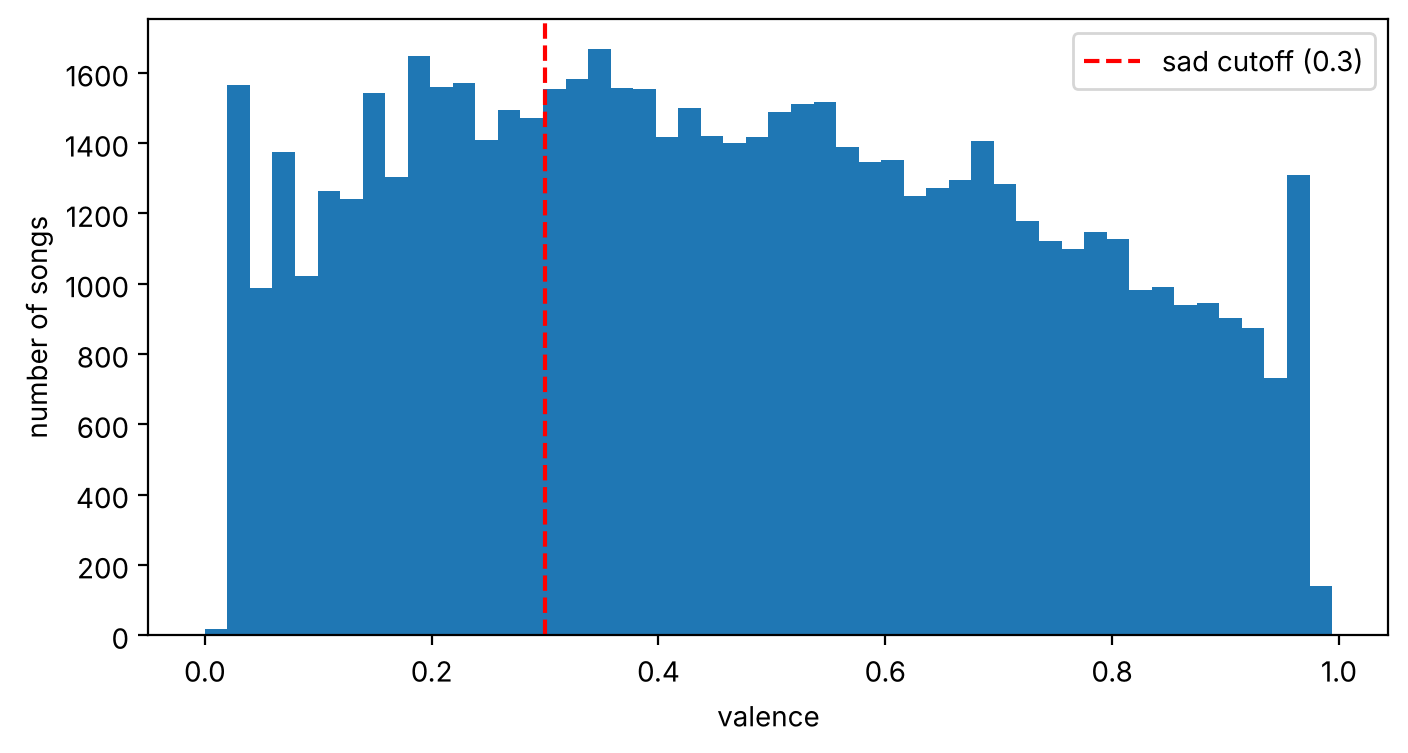

skew: 0.15
valence < 0.2: 19.1% of songs
valence < 0.3: 31.0% of songs
valence < 0.4: 43.7% of songs


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_df["valence"], bins=50)
ax.axvline(0.3, color="red", ls="--", label="sad cutoff (0.3)")
ax.set_xlabel("valence")
ax.set_ylabel("number of songs")
ax.legend()
plt.show()

print(f"skew: {train_df['valence'].skew():.2f}")
for cutoff in [0.2, 0.3, 0.4]:
    print(f"valence < {cutoff}: {(train_df['valence'] < cutoff).mean():.1%} of songs")

Valence covers the whole 0 to 1 range and is barely skewed, so we don't need to transform it.
With a cutoff of 0.3, 31% of songs count as sad. The classes are imbalanced, so for classification we should look at F1 and ROC-AUC, not just accuracy.

## 2. Feature distributions

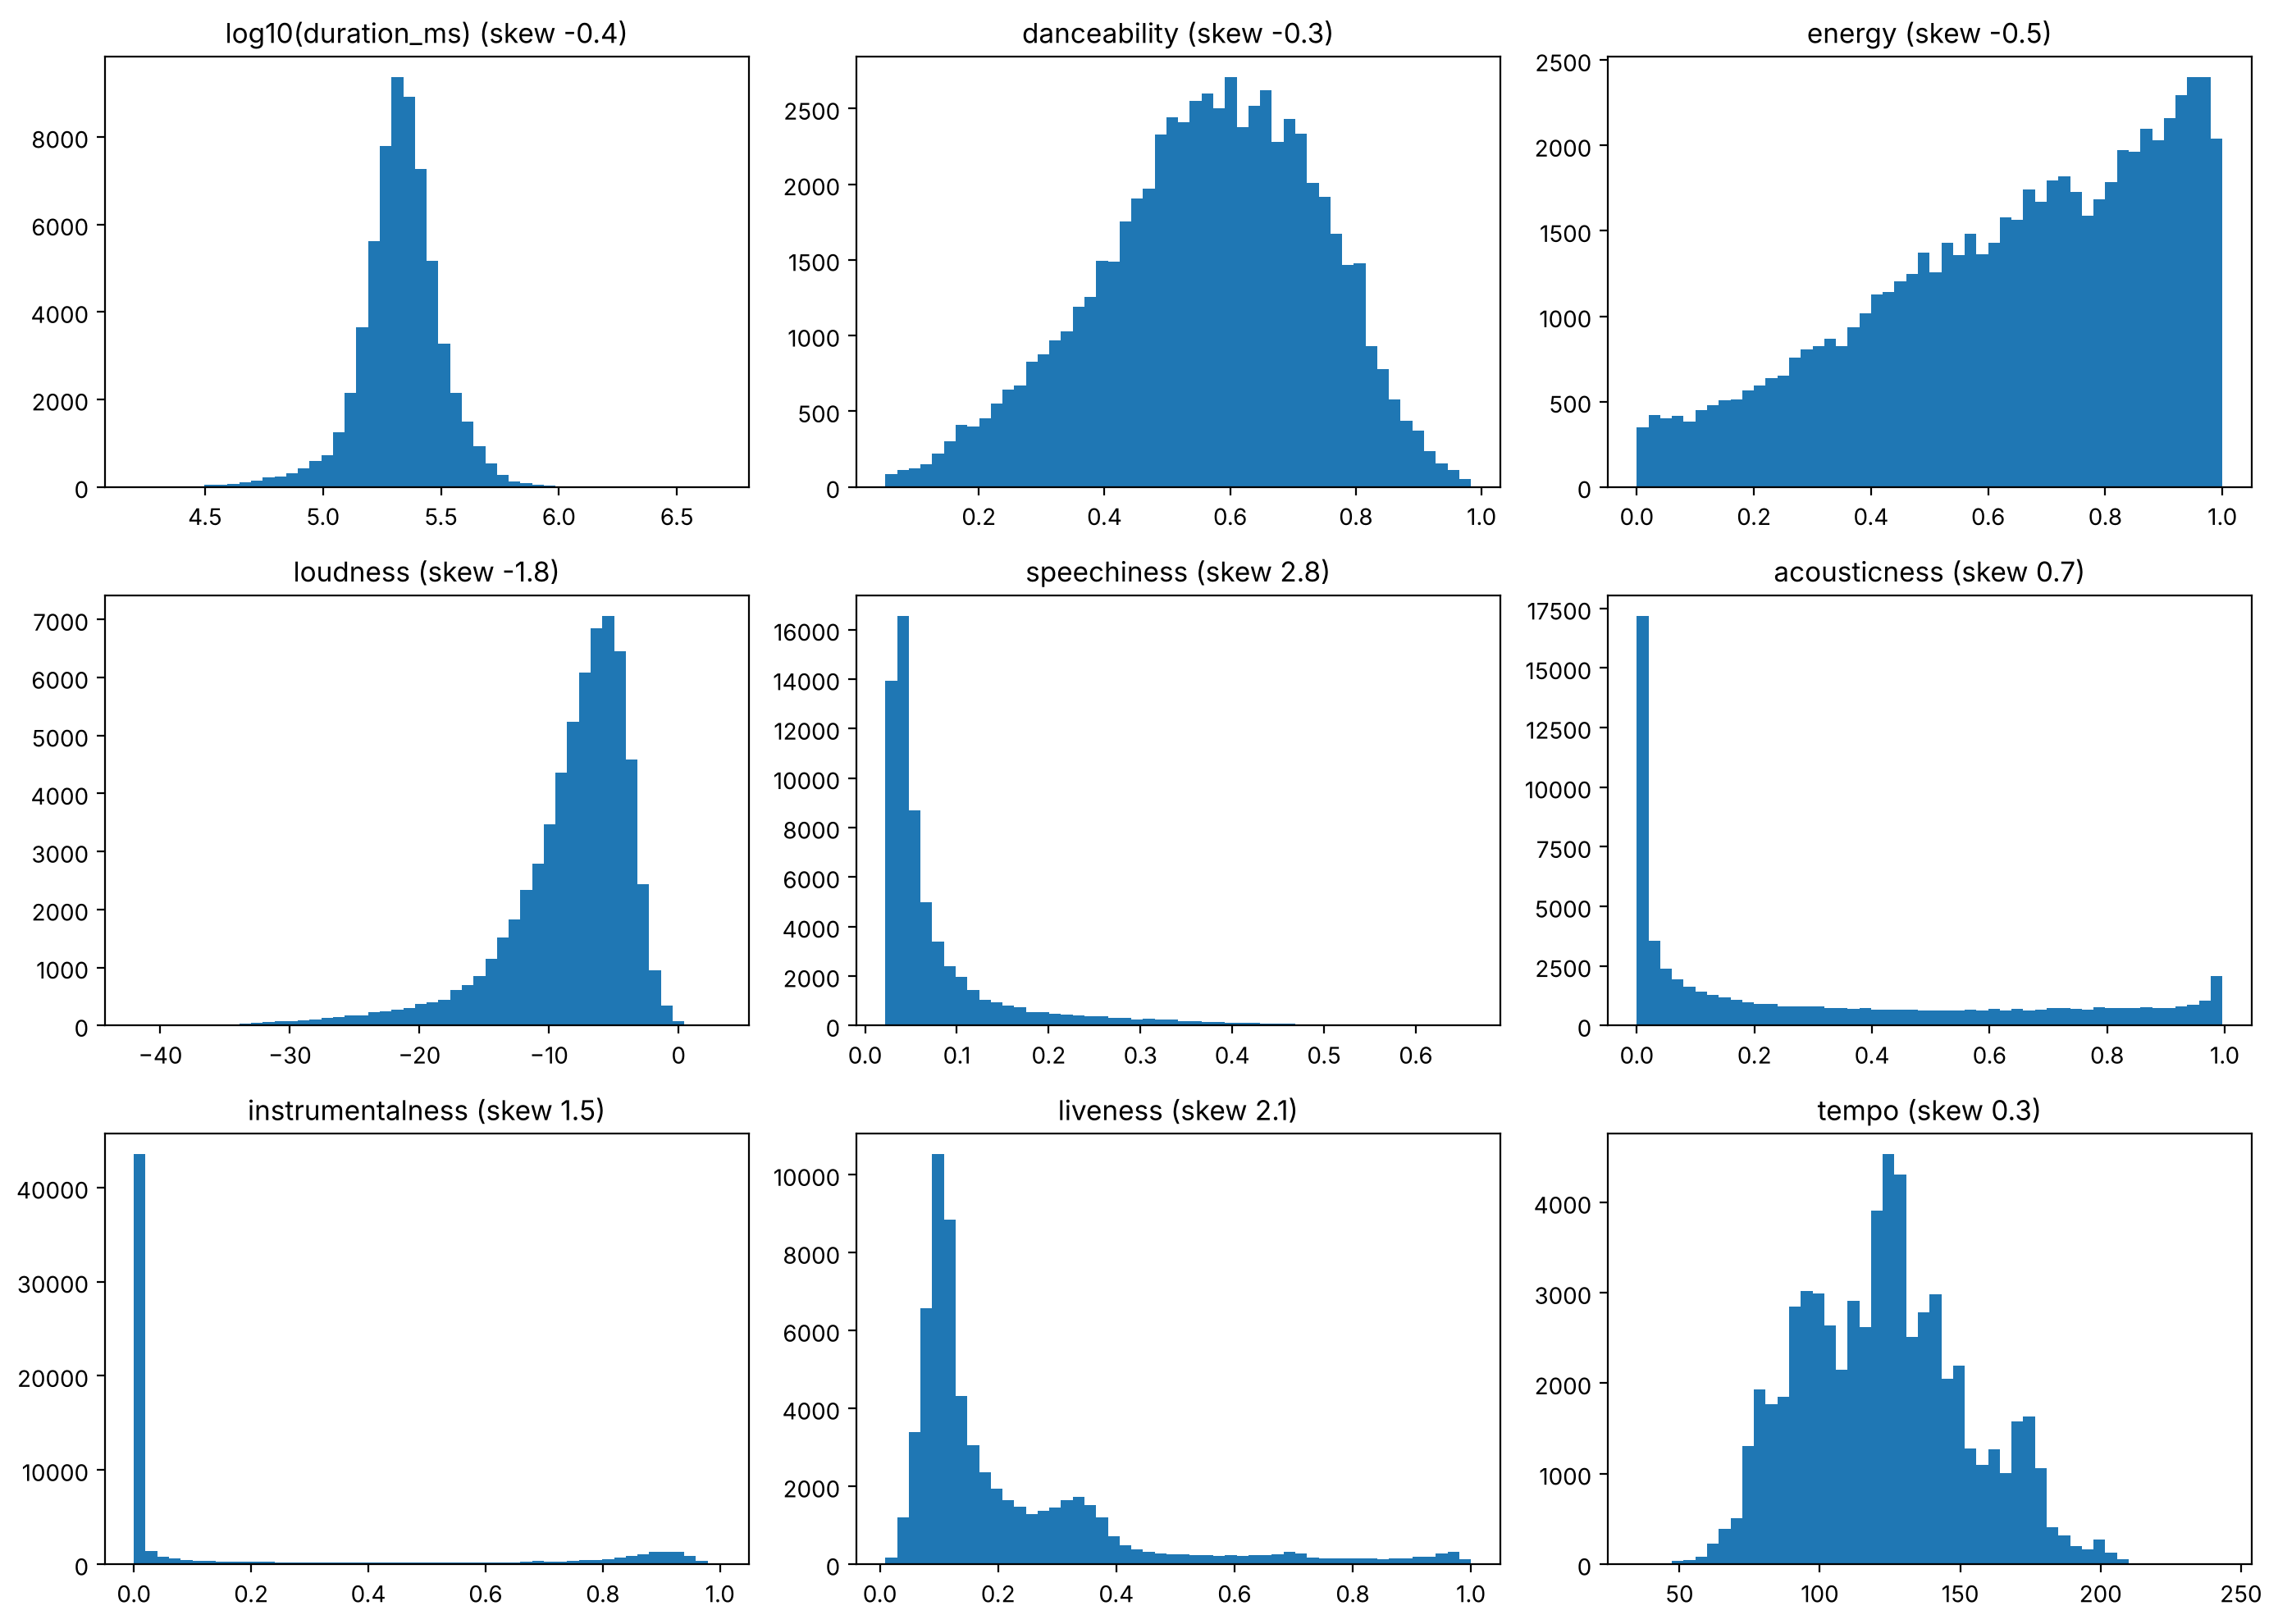

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, NUM_COLS):
    if col == "duration_ms":
        ax.hist(np.log10(train_df[col]), bins=50)
        ax.set_title(f"log10(duration_ms) (skew {np.log10(train_df[col]).skew():.1f})")
    else:
        ax.hist(train_df[col], bins=50)
        ax.set_title(f"{col} (skew {train_df[col].skew():.1f})")
plt.tight_layout()
plt.show()

In [ ]:
print(f"duration_ms skew before log: {train_df['duration_ms'].skew():.1f}, songs over an hour: {(train_df['duration_ms'] > 3_600_000).sum()}")
print(f"instrumentalness < 0.01: {(train_df['instrumentalness'] < 0.01).mean():.1%} of songs")
for col in ["speechiness", "liveness"]:
    print(f"{col} skew: {train_df[col].skew():.1f} before log, {np.log(train_df[col]).skew():.1f} after log")

duration_ms skew before log: 10.2, songs over an hour: 8
instrumentalness < 0.01: 66.8% of songs
speechiness skew: 2.8 before log, 1.1 after log
liveness skew: 2.1 before log, 0.5 after log


`duration_ms` is very skewed (skew 10) because of a few very long tracks, including 8 over an hour. On a log scale it looks normal, so the plot shows log duration instead.
`liveness` and `speechiness` are also right-skewed. A log transform fixes liveness well but only helps speechiness a little.
`loudness` is skewed the other way, with a tail of very quiet songs. `acousticness` has a big spike at 0 and a smaller one near 1.
`instrumentalness` is almost 0 for two thirds of the songs, with a second group near 0.9, so it's almost a yes/no feature.

### Categorical features

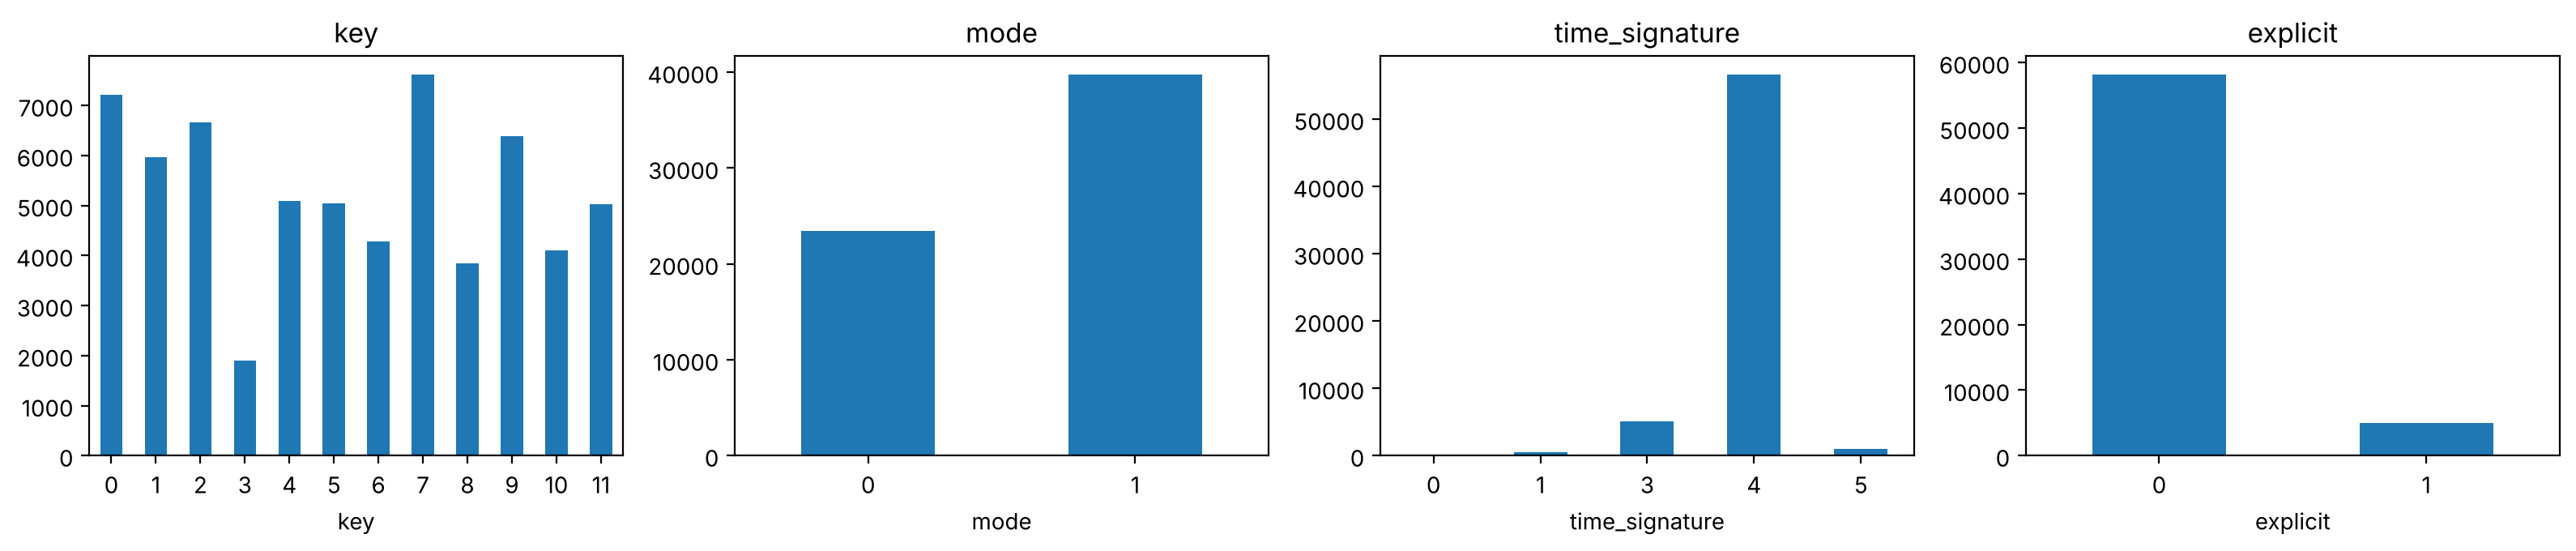

                count  mean
time_signature             
0                   4  0.39
1                 529  0.33
3                5048  0.35
4               56549  0.48
5                1008  0.37


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["key", "mode", "time_signature", "explicit"]):
    train_df[col].value_counts().sort_index().plot.bar(ax=ax, title=col)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print(train_df.groupby("time_signature")["valence"].agg(["count", "mean"]).round(2))

Mode is 1 for major and 0 for minor. 63% of songs are major and 8% are explicit.
Almost 90% of songs are in 4/4 time. The other time signatures are rare (and 0 isn't a real time signature), but they all have lower valence than 4/4 (0.33 to 0.39 vs. 0.48). A single "is 4/4" feature may be more useful than the raw number.

## 3. Correlations

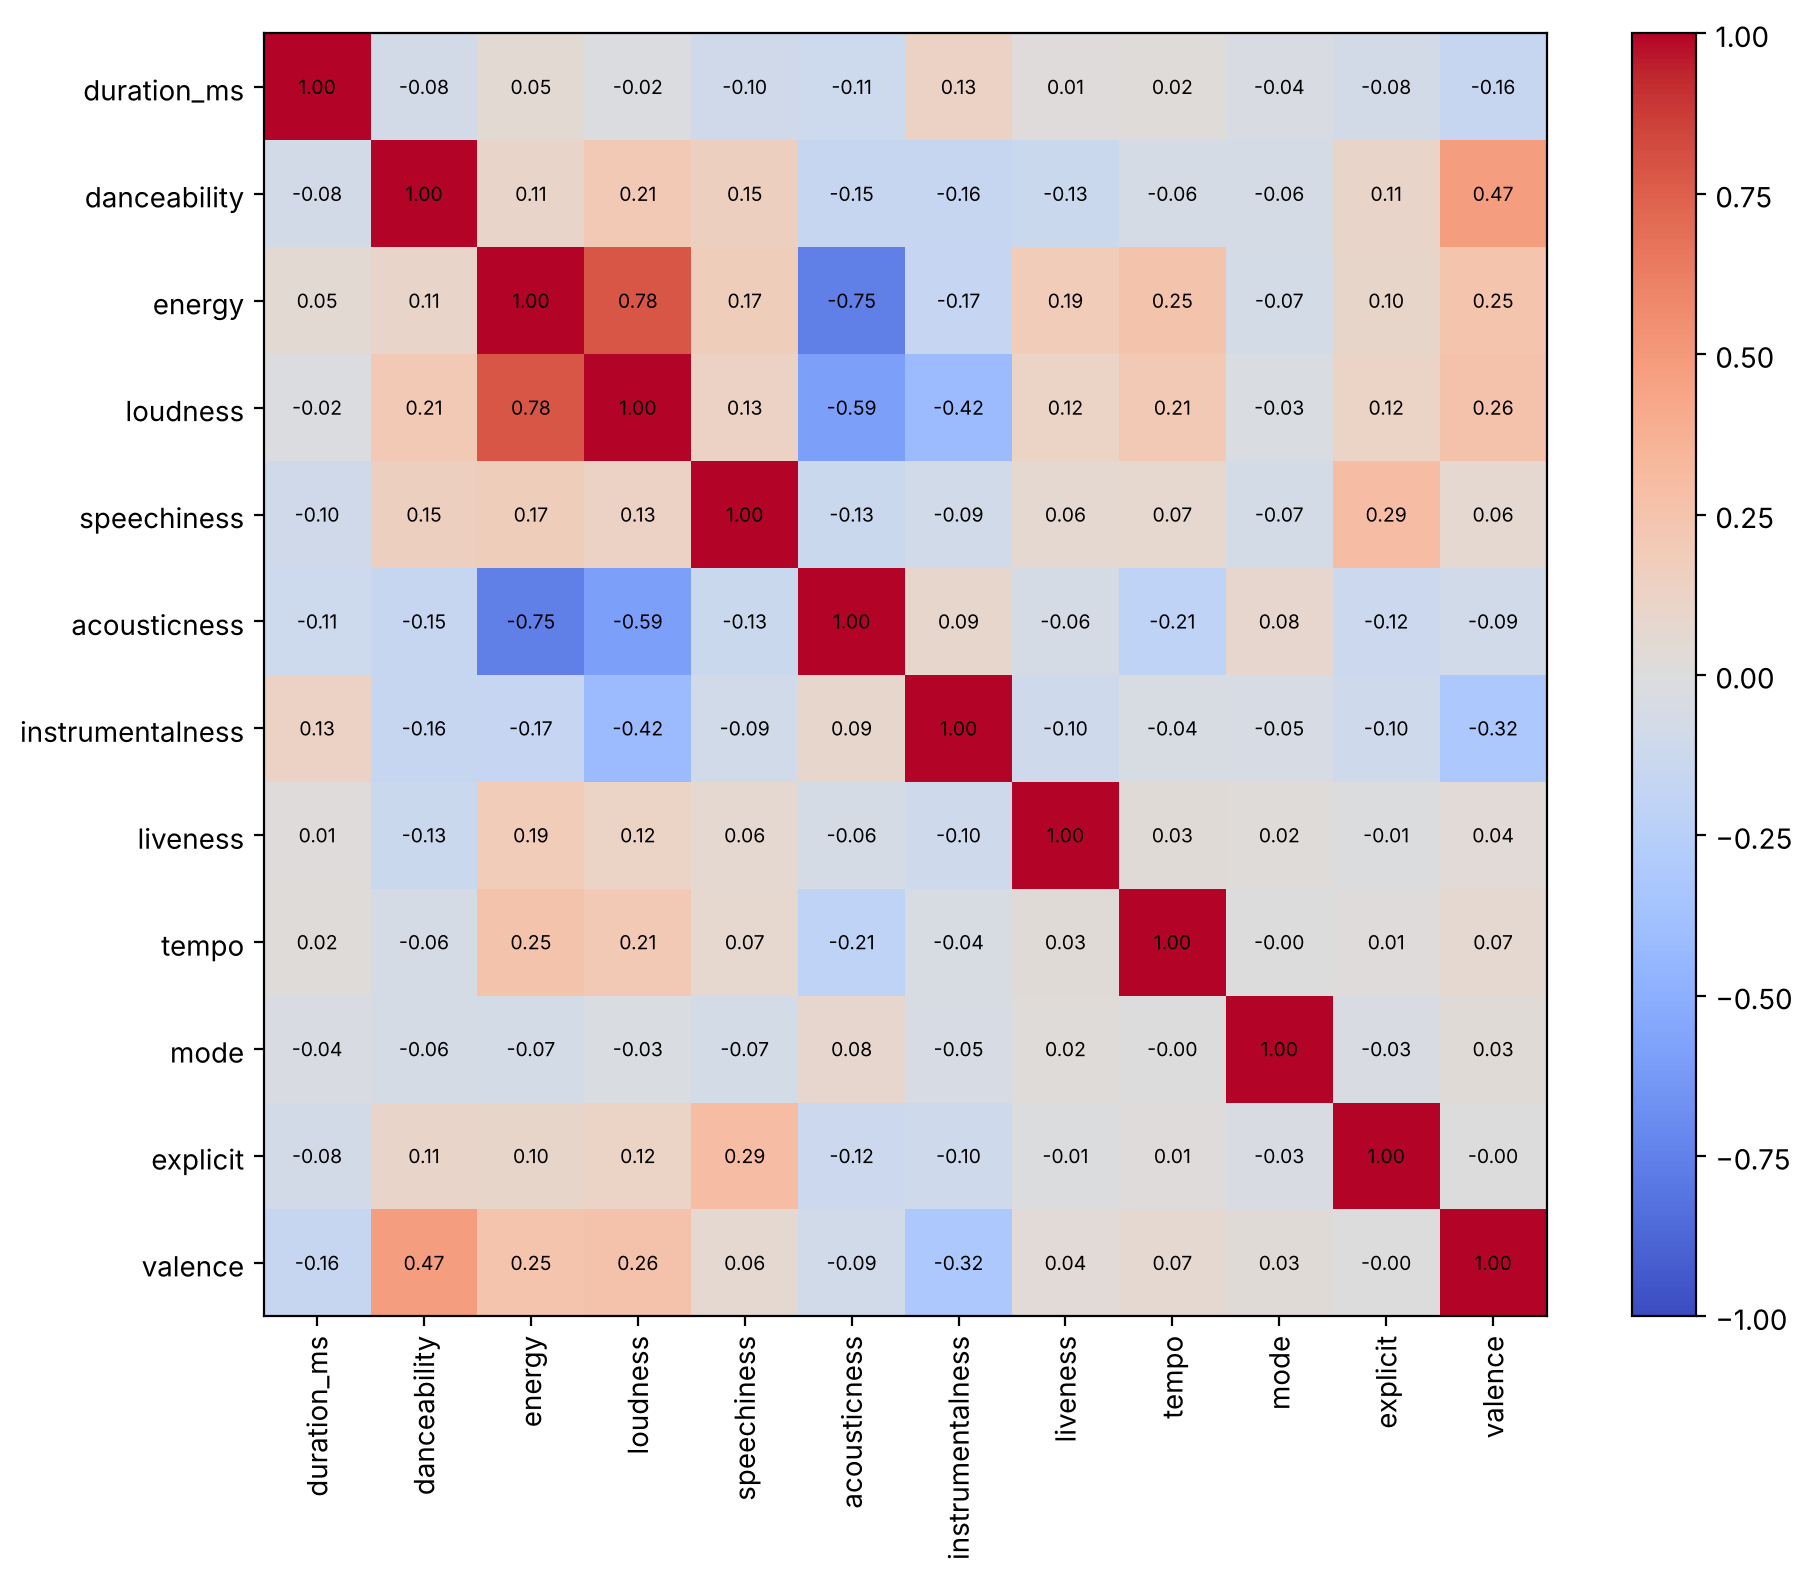

In [ ]:
corr_cols = NUM_COLS + ["mode", "explicit", "valence"]
corr = train_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
plt.tight_layout()
plt.show()

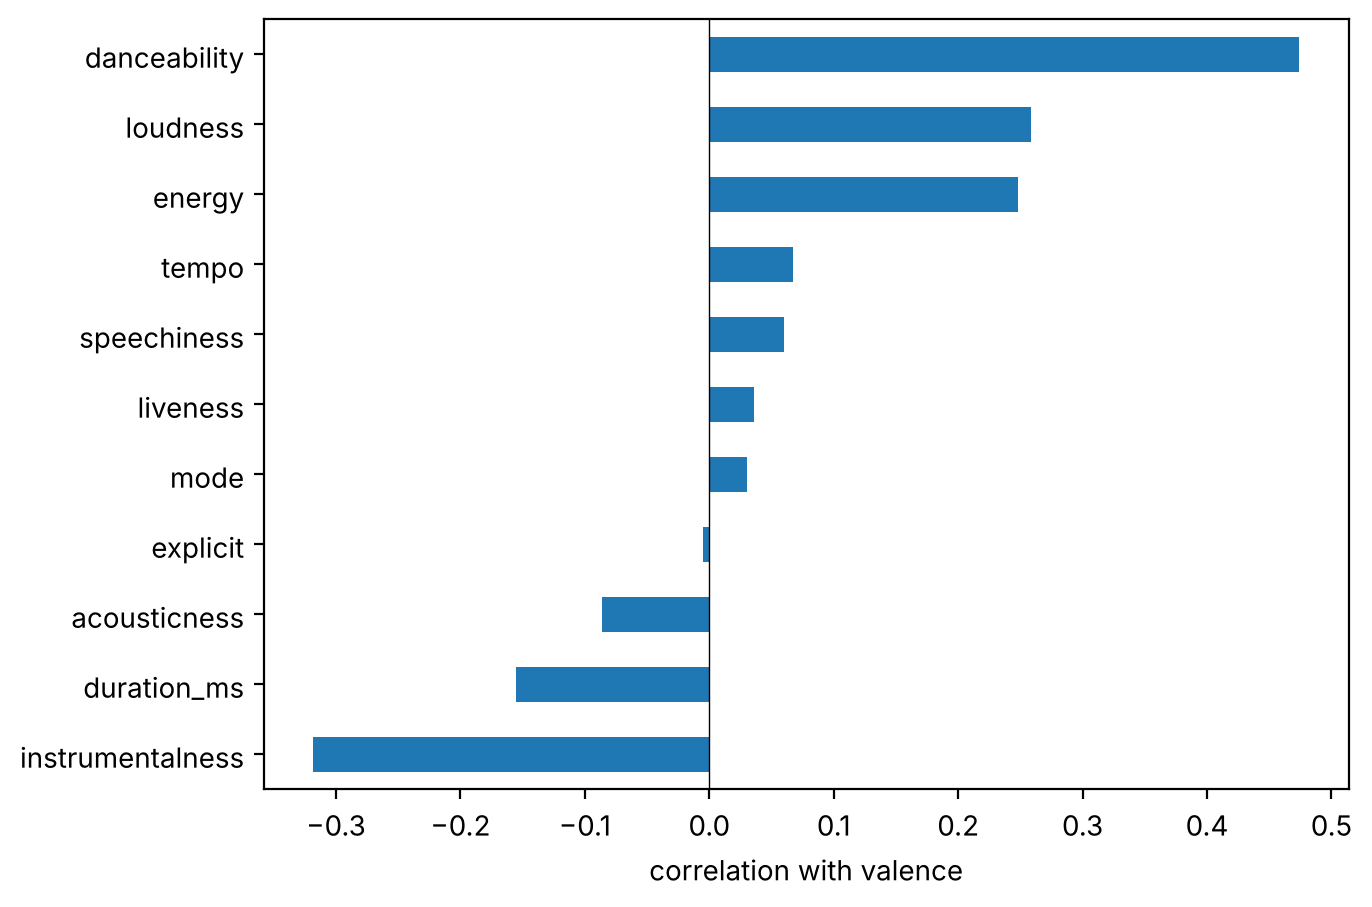

In [ ]:
corr["valence"].drop("valence").sort_values().plot.barh(figsize=(7, 5))
plt.axvline(0, color="black", lw=0.5)
plt.xlabel("correlation with valence")
plt.show()

Danceability has the strongest correlation with valence (0.47), followed by instrumentalness (−0.32), loudness (0.26), and energy (0.25). Mode and acousticness are close to 0.

Energy, loudness, and acousticness are strongly correlated with each other (energy and loudness 0.78, energy and acousticness −0.75), which makes their individual coefficients hard to interpret in a linear model.

## 4. Checking what we expected

We expected sad songs to be in a minor key, low energy, and acoustic.

In [ ]:
print(train_df.groupby("mode")["valence"].agg(["mean", "median", "count"]).rename(index={0: "minor", 1: "major"}).round(3))

        mean  median  count
mode                       
minor  0.459   0.446  23425
major  0.475   0.461  39713


Minor-key songs are only slightly sadder than major-key songs (0.46 vs. 0.48 on average).

Next, we sort the songs by each feature, split them into 10 equal groups, and plot the average valence of each group.

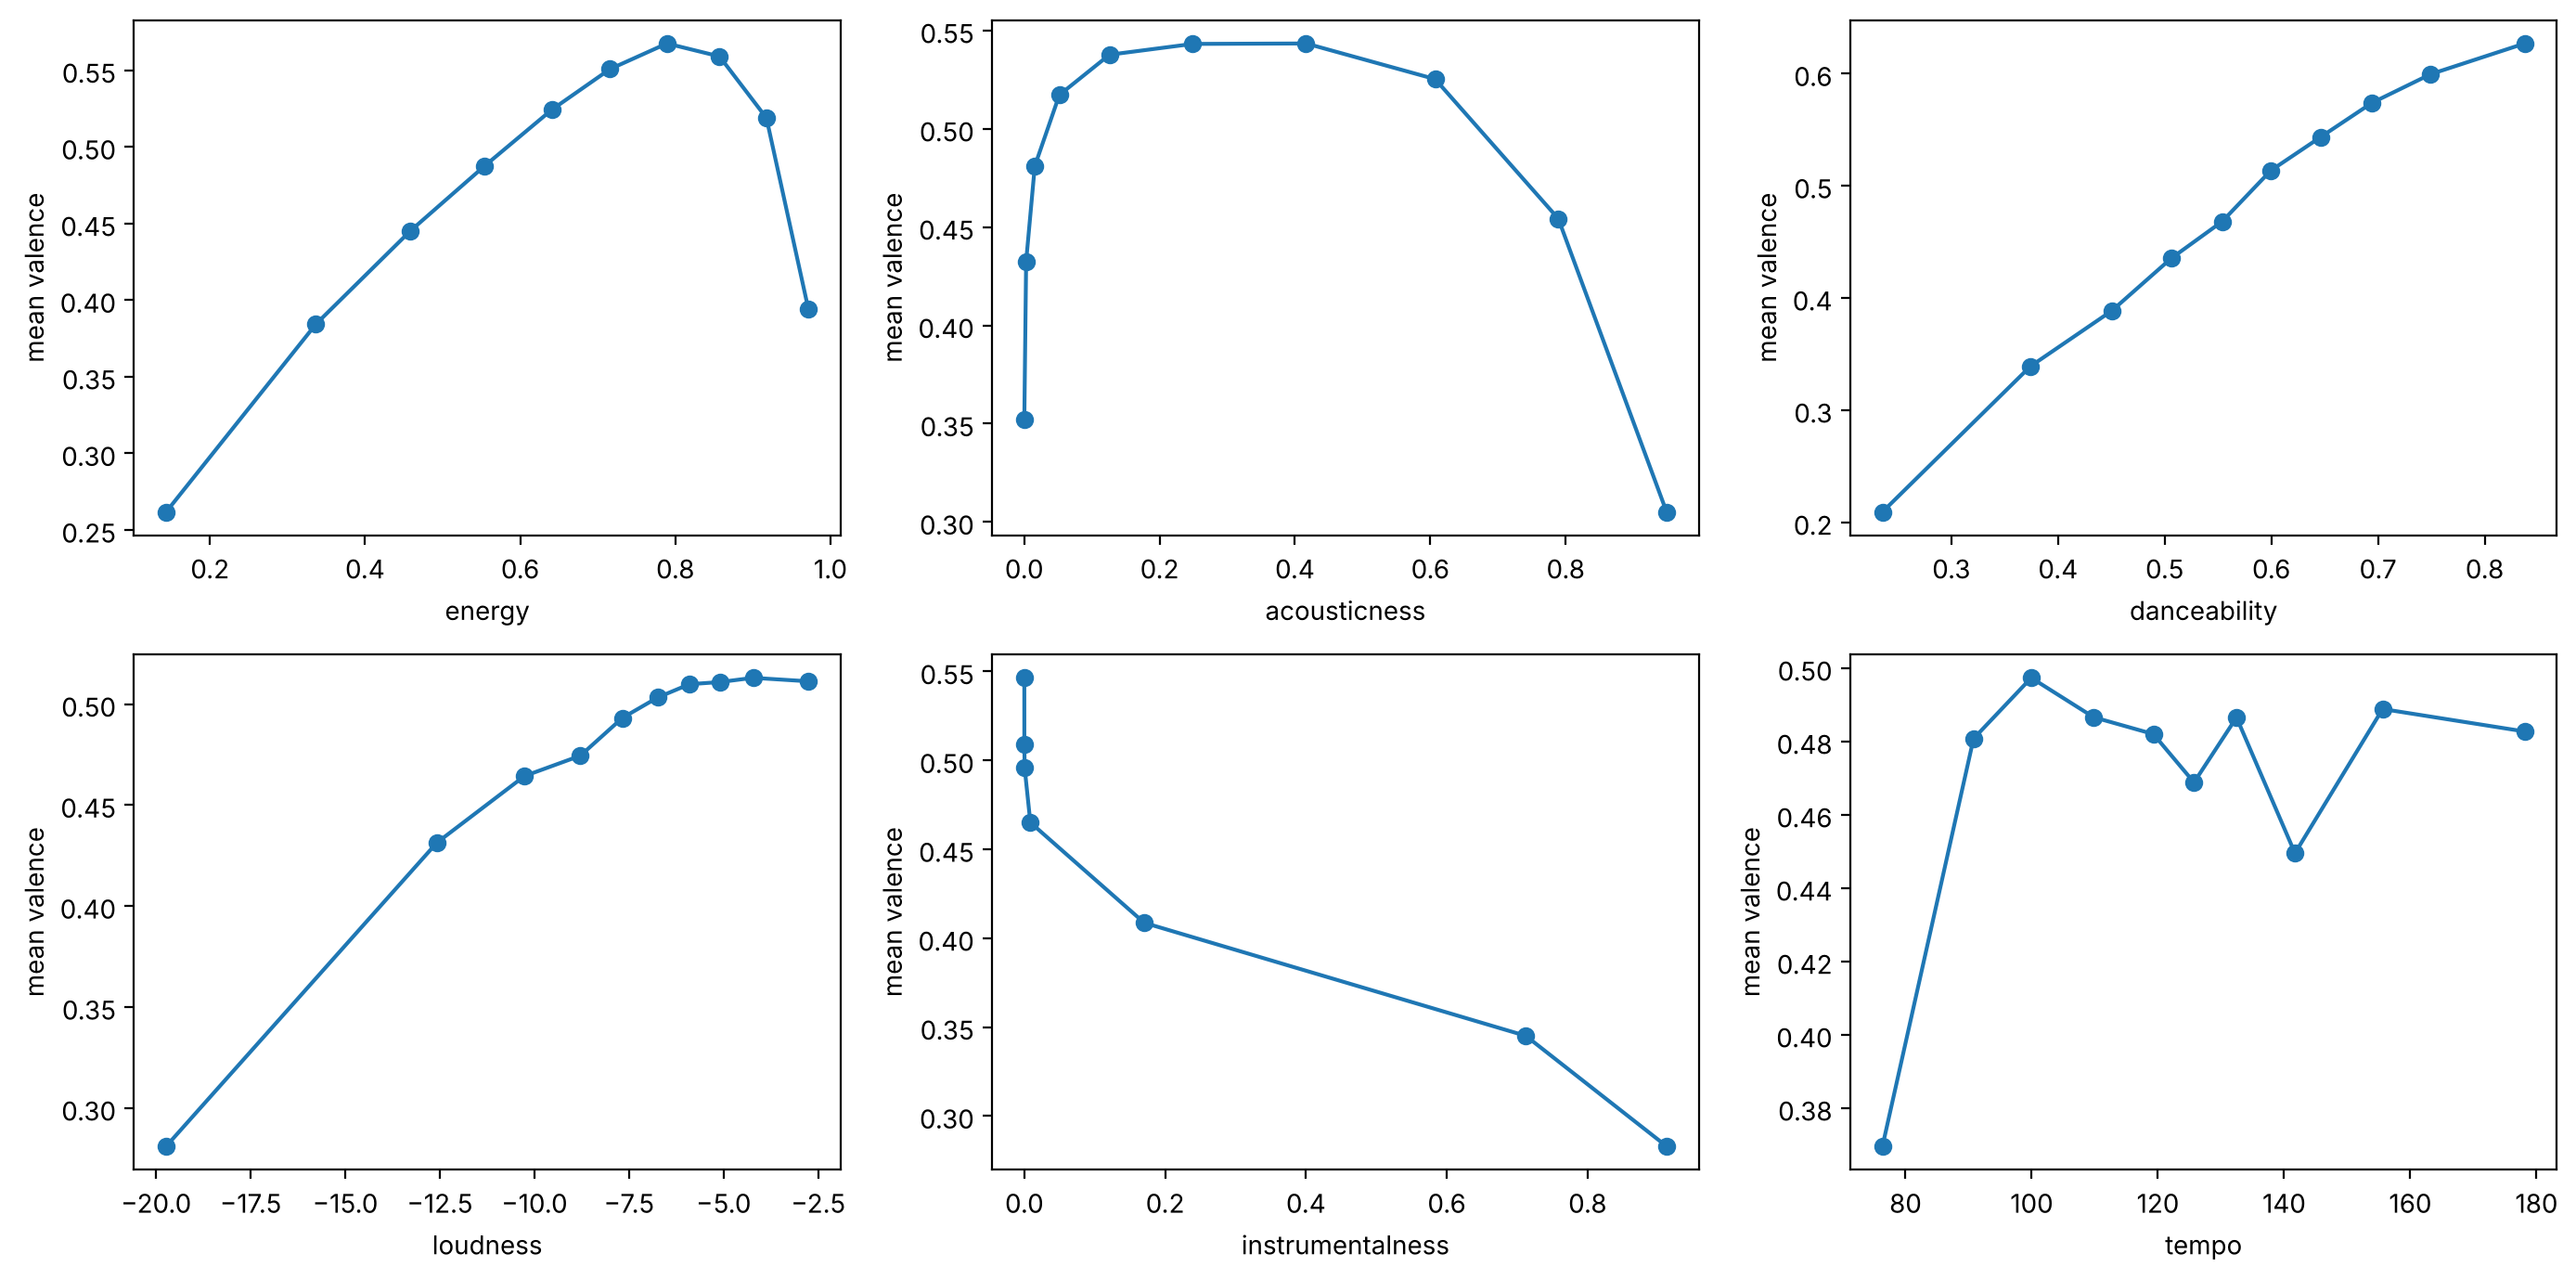

In [ ]:
check_cols = ["energy", "acousticness", "danceability", "loudness", "instrumentalness", "tempo"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, check_cols):
    bins = pd.qcut(train_df[col], 10, duplicates="drop")
    means = train_df.groupby(bins, observed=True)["valence"].mean()
    centers = train_df.groupby(bins, observed=True)[col].mean()
    ax.plot(centers, means, marker="o")
    ax.set_xlabel(col)
    ax.set_ylabel("mean valence")
plt.tight_layout()
plt.show()

Valence goes up with energy until about 0.8, then drops sharply for the most energetic 10% of songs (from about 0.56 to 0.39). Very low and very high energy both go with lower valence.

Acousticness has an upside-down U shape. Songs with almost no acoustic sound and very acoustic songs are both sad, and the middle is happiest. This is why its correlation with valence is close to 0, even though it has a strong effect at both ends.

Danceability has a nearly straight-line relationship with valence, and loudness goes up and then levels off. Instrumentalness goes down, and tempo only matters for very slow songs.

Since energy and acousticness are curved, we check how much a squared term helps when predicting valence from each one alone.

In [ ]:
def r2_poly(col, degree):
    coefs = np.polyfit(train_df[col], train_df["valence"], degree)
    pred = np.polyval(coefs, train_df[col])
    return 1 - ((train_df["valence"] - pred) ** 2).sum() / ((train_df["valence"] - train_df["valence"].mean()) ** 2).sum()

for col in ["energy", "acousticness"]:
    print(f"{col}: R² {r2_poly(col, 1):.3f} with a straight line, {r2_poly(col, 2):.3f} with a squared term")

instr = train_df["instrumentalness"] > 0.5
slow = train_df["tempo"] < 85
print(f"\ninstrumentalness > 0.5: {instr.mean():.0%} of songs, mean valence {train_df.loc[instr, 'valence'].mean():.2f} vs {train_df.loc[~instr, 'valence'].mean():.2f}")
print(f"tempo < 85: {slow.mean():.0%} of songs, mean valence {train_df.loc[slow, 'valence'].mean():.2f} vs {train_df.loc[~slow, 'valence'].mean():.2f}")

energy: R² 0.061 with a straight line, 0.113 with a squared term
acousticness: R² 0.007 with a straight line, 0.078 with a squared term

instrumentalness > 0.5: 19% of songs, mean valence 0.31 vs 0.51
tempo < 85: 10% of songs, mean valence 0.37 vs 0.48


The squared term almost doubles R² for energy and takes acousticness from almost no R² to 0.078.
Songs with instrumentalness above 0.5 average 0.31 valence vs. 0.51 for the rest, and songs under 85 BPM average 0.37 vs. 0.48.

## 5. Genre

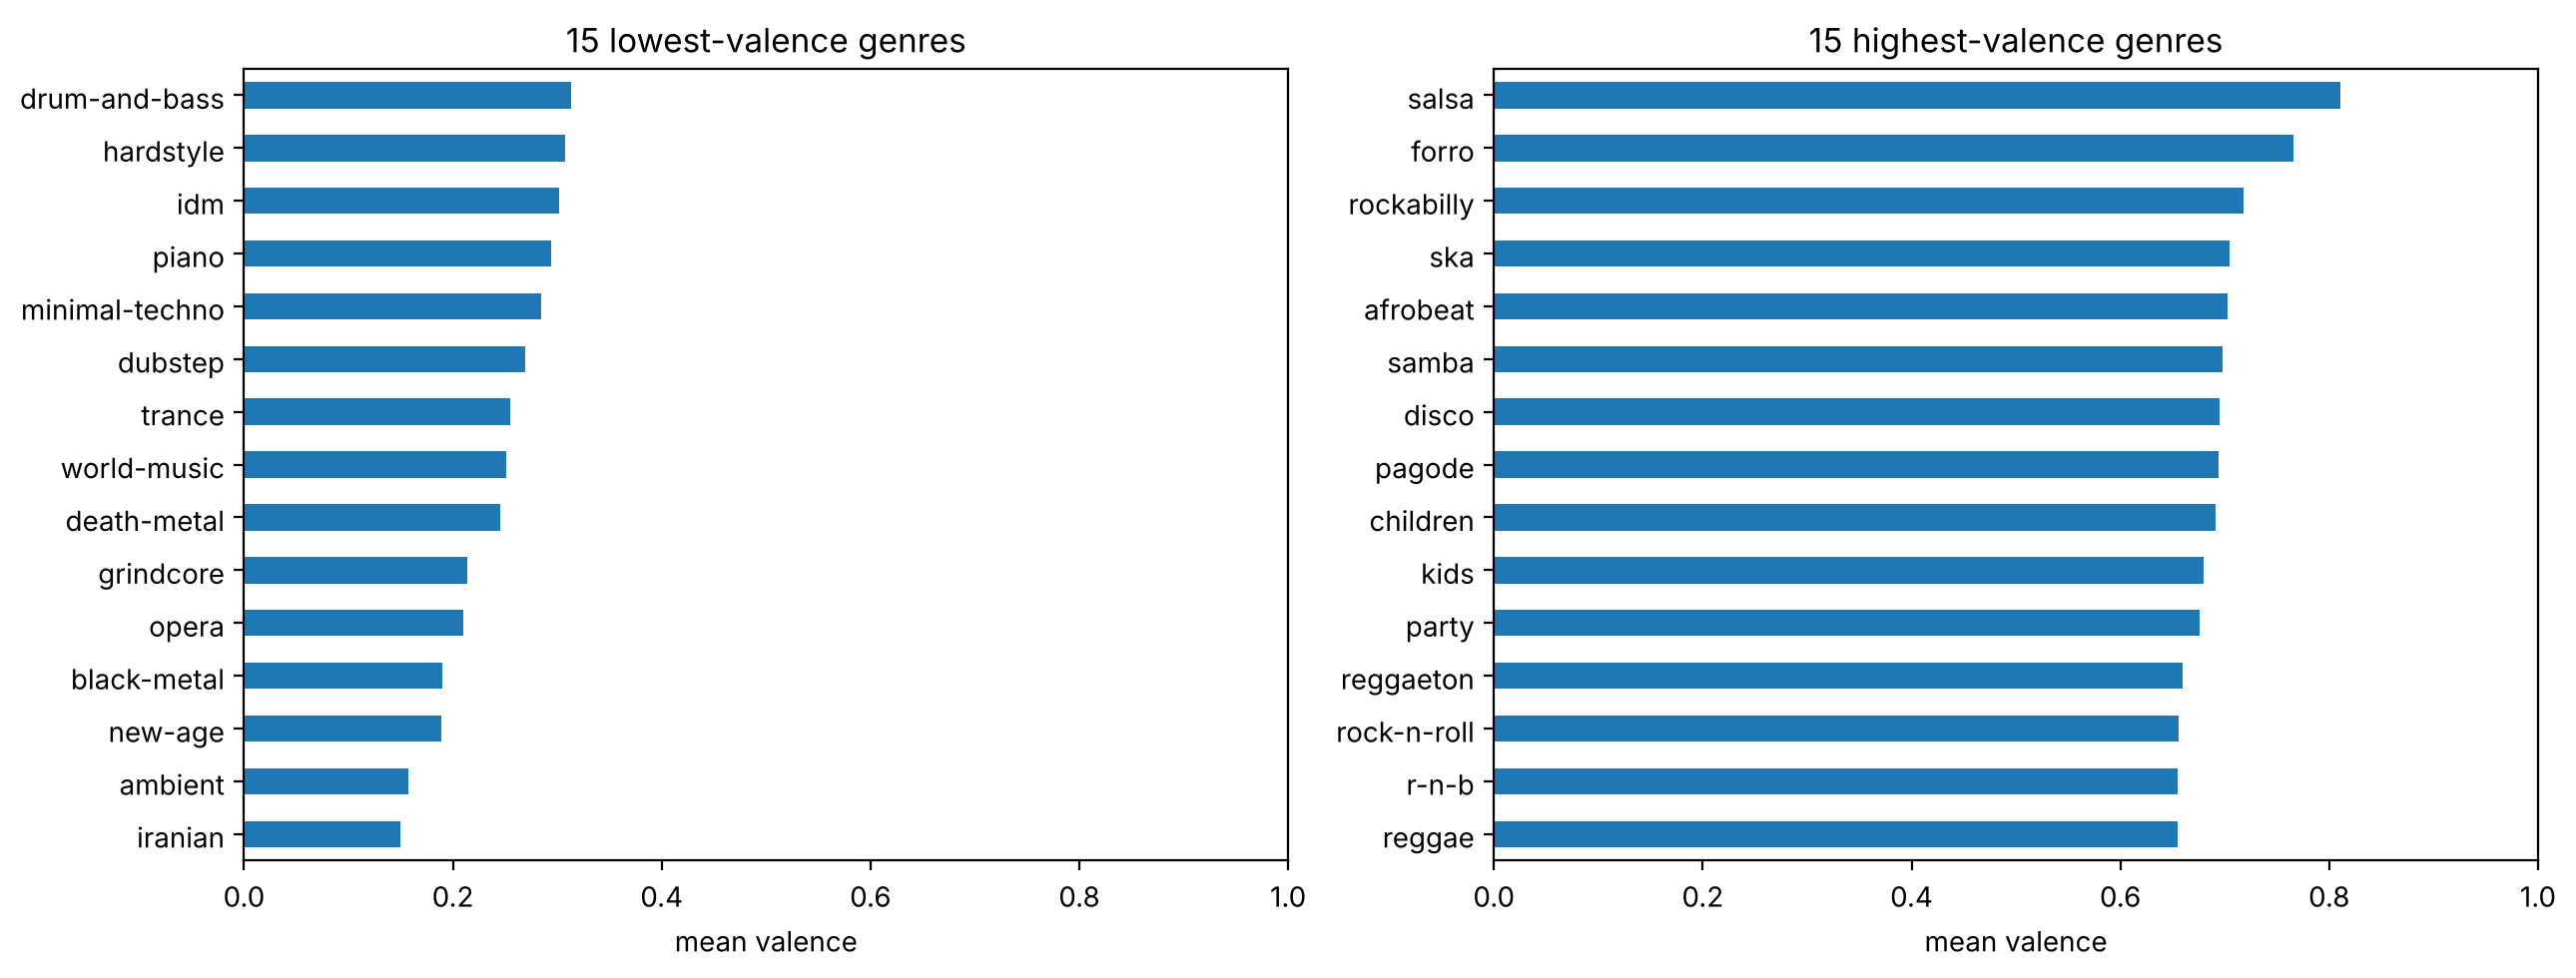

112 genres, mean valence from 0.15 to 0.81
R² from predicting each song as its genre's average: 0.32


In [ ]:
genre_mean = train_df.groupby("track_genre")["valence"].mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
genre_mean.head(15).plot.barh(ax=axes[0], title="15 lowest-valence genres")
genre_mean.tail(15).plot.barh(ax=axes[1], title="15 highest-valence genres")
for ax in axes:
    ax.set_xlabel("mean valence")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

genre_pred = train_df.groupby("track_genre")["valence"].transform("mean")
r2 = 1 - ((train_df["valence"] - genre_pred) ** 2).sum() / ((train_df["valence"] - train_df["valence"].mean()) ** 2).sum()
print(f"{train_df['track_genre'].nunique()} genres, mean valence from {genre_mean.min():.2f} to {genre_mean.max():.2f}")
print(f"R² from predicting each song as its genre's average: {r2:.2f}")

Average valence ranges from 0.15 (iranian) to 0.81 (salsa), and genre alone explains about a third of the variation in valence.

The lowest-valence genres fall into two groups, calm ones (ambient, new-age, opera, piano) and intense ones (black-metal, grindcore, death-metal, dubstep, hardstyle).

With 112 genres, one-hot encoding adds 112 columns. Target encoding (fit inside the cross-validation folds) or grouping genres into families would use fewer.

## 6. Sad vs. intense songs

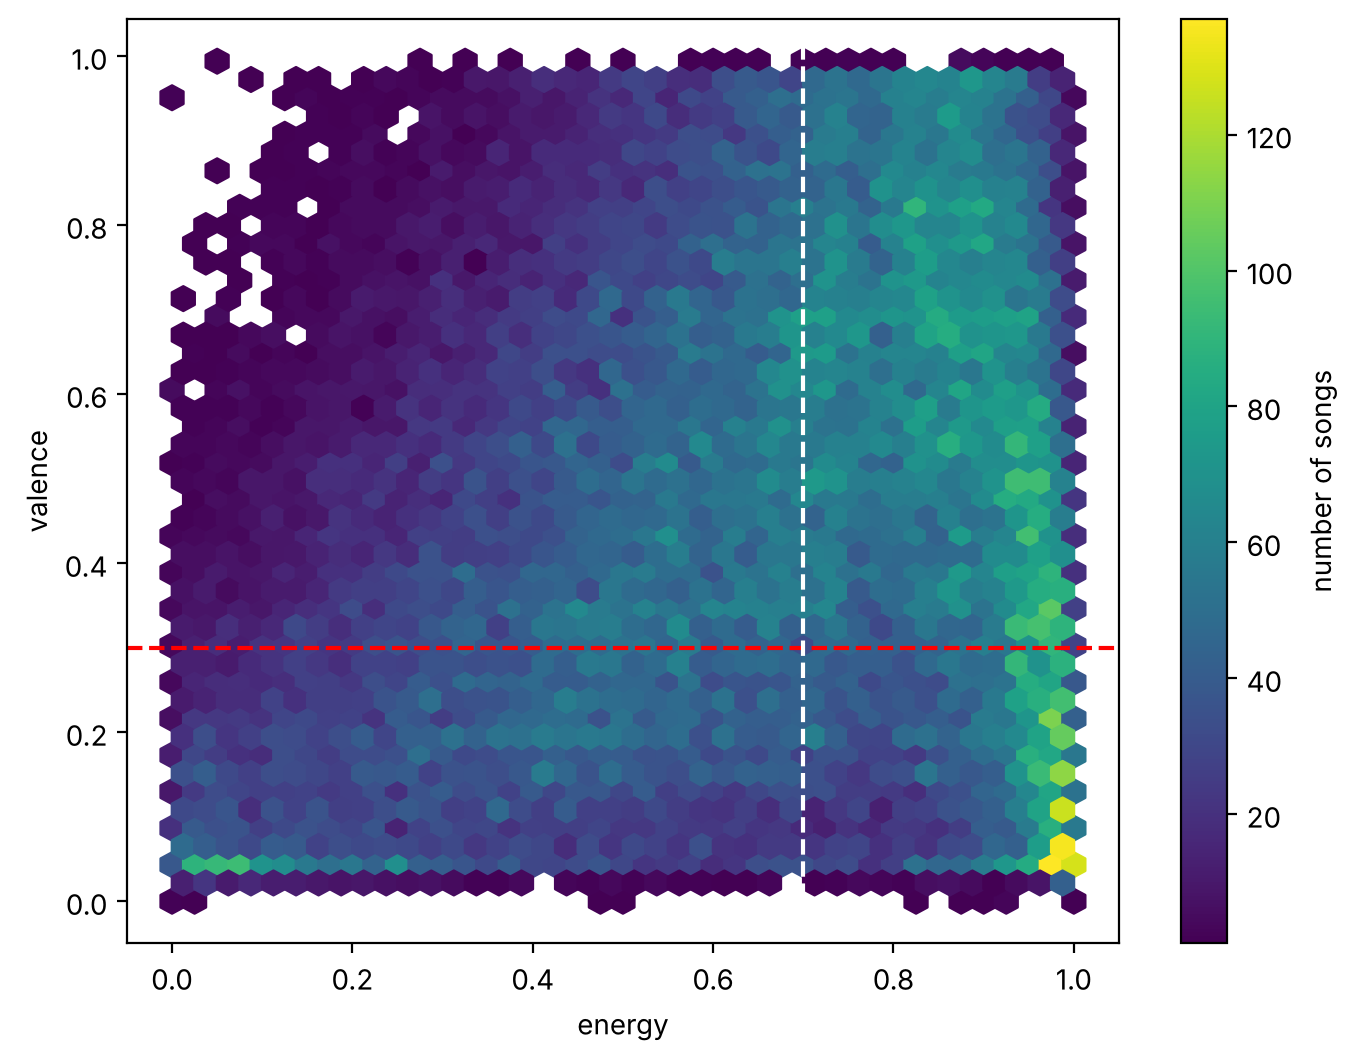

Sad songs with energy > 0.7: 37.6%
Sad songs with energy < 0.4: 34.0%

Genres with the most high-energy sad songs:
track_genre
grindcore        566
black-metal      524
death-metal      415
hardstyle        390
trance           365
drum-and-bass    358
happy            346
metalcore        292
iranian          231
club             221


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(train_df["energy"], train_df["valence"], gridsize=40, mincnt=1, cmap="viridis")
ax.axhline(0.3, color="red", ls="--")
ax.axvline(0.7, color="white", ls="--")
ax.set_xlabel("energy")
ax.set_ylabel("valence")
fig.colorbar(hb, label="number of songs")
plt.show()

sad = train_df[train_df["valence"] < 0.3]
print(f"Sad songs with energy > 0.7: {(sad['energy'] > 0.7).mean():.1%}")
print(f"Sad songs with energy < 0.4: {(sad['energy'] < 0.4).mean():.1%}")
print("\nGenres with the most high-energy sad songs:")
print(sad[sad["energy"] > 0.7]["track_genre"].value_counts().head(10).to_string())

Most low-valence songs are either low energy or very high energy.
38% of songs below 0.3 valence have energy above 0.7, about the same as the share with energy below 0.4. The high-energy ones are mostly metal (grindcore, black-metal, death-metal, metalcore) and hard electronic music (hardstyle, trance, drum-and-bass).

Low valence covers two different kinds of songs, calm sad songs and intense ones. A model that assumes more energy means happier will predict the intense ones too high.

## 7. Feature engineering ideas

1. Log transform `duration_ms` and `liveness`.
2. Add squared terms for energy and acousticness, which have curved relationships with valence.
3. Add an "is instrumental" flag (`instrumentalness > 0.5`) and a "slow song" flag (`tempo < 85`).
4. Replace `time_signature` with an "is 4/4" flag, and treat `key` as a category instead of a number.
5. Encode genre with one-hot, target encoding, or genre families.
6. Try interaction terms like energy × danceability or energy × genre family, to help separate intense songs from happy energetic ones.

---

# Part 3: Feature Engineering

*By Yuming Zou.*

Now we turn the cleaned data into the **final set of features** that every model will use.
The ideas come from the data exploration in Part 2, which looked at the **training set only**.

We follow two rules:
- **`valence` is never an input feature.** It is only the target.
- **Fixed rules can be applied to both sets** (for example "take the log of duration"), because they don't learn anything from the data.
  Anything that *learns* from the data (like a scaler) is **fit on the training set only**.

In [ ]:
train = train_df.copy()
test = test_df.copy()
print(train.shape, test.shape)

(63138, 15) (15785, 15)


## 1. Encode `explicit`, `key`, and `track_genre`

- `explicit` is True/False. Models need numbers, so we turn it into 1/0.
- `key` is stored as a number (0 = C, 1 = C#, ... 11 = B), but it is a **category**: key 11 is not "bigger" than key 0.
  If we left it as a number, a linear model would treat B as 11 times "more" than C#. So we one-hot encode it: one 0/1 column per key.
- `track_genre` is also a category. EDA found that **genre alone explains about a third of the variation in valence**, so it is an important feature.
  We one-hot encode all 112 genres. That adds 112 columns, but with 63,000 training songs (and at least 155 songs in every genre) the models have enough data for it.
  We also tested a simpler option, grouping the genres into broader families (below).

In [ ]:
def one_hot(values, categories, prefix):
    """One 0/1 column per category. The categories are fixed, so train and test get the same columns."""
    return pd.DataFrame({f"{prefix}_{c}": (values == c).astype(int) for c in categories}, index=values.index)

KEY_COLS = [f"key_{k}" for k in range(12)]
GENRE_LIST = sorted(train["track_genre"].unique())   # the list of genres comes from the training set
GENRE_COLS = [f"genre_{g}" for g in GENRE_LIST]

train["explicit"] = train["explicit"].astype(int)
test["explicit"] = test["explicit"].astype(int)
train = pd.concat([train, one_hot(train["key"], range(12), "key"), one_hot(train["track_genre"], GENRE_LIST, "genre")], axis=1)
test = pd.concat([test, one_hot(test["key"], range(12), "key"), one_hot(test["track_genre"], GENRE_LIST, "genre")], axis=1)

print(f"{len(KEY_COLS)} key columns, {len(GENRE_COLS)} genre columns")
print(f"Fewest training songs in one genre: {train['track_genre'].value_counts().min()}")

12 key columns, 112 genre columns
Fewest training songs in one genre: 155


### Test: grouping genres into families

112 genre columns is a lot, so we tested grouping the genres into **12 broader families** by musical style.
We placed each genre by looking at its top artists and its typical audio features. A few choices worth explaining:
- Genres named after a **country or language** (british, french, german, swedish, indian, iranian, turkish, malay) contain many different styles, so they go into "regional".
- **`happy`** is mostly "happy hardcore", a very fast, loud dance style, so it goes into "electronic", not "pop".
- **`world-music`** is mostly Christian worship music, so it goes with gospel and soul.
- **`groove`** and **`hardcore`** are mostly groove metal and hardcore punk, so they go into "metal".

**How we tested it:** we predict each training song's valence as the average valence of its group, and compare R² for the 112 genres vs. the 12 families.

In [ ]:
GENRE_FAMILIES = {
    "rock": ["alt-rock", "alternative", "british", "emo", "garage", "goth", "grunge", "hard-rock", "indie",
             "j-rock", "power-pop", "psych-rock", "punk", "punk-rock", "rock", "rock-n-roll", "rockabilly"],
    "metal": ["black-metal", "death-metal", "grindcore", "groove", "hardcore", "heavy-metal", "industrial",
              "metal", "metalcore"],
    "electronic": ["breakbeat", "chicago-house", "club", "deep-house", "detroit-techno", "drum-and-bass", "dub",
                   "dubstep", "edm", "electronic", "happy", "hardstyle", "house", "idm", "minimal-techno",
                   "progressive-house", "techno", "trance", "trip-hop"],
    "pop": ["anime", "cantopop", "chill", "dance", "electro", "indie-pop", "j-idol", "j-pop", "k-pop", "mandopop",
            "party", "pop", "sad", "synth-pop"],
    "hiphop_rnb": ["hip-hop", "r-n-b"],
    "soul_jazz_blues": ["blues", "disco", "funk", "gospel", "jazz", "soul", "world-music"],
    "latin": ["brazil", "forro", "latin", "latino", "mpb", "pagode", "reggaeton", "salsa", "samba", "sertanejo",
              "spanish", "tango"],
    "reggae_afro": ["afrobeat", "dancehall", "j-dance", "reggae", "ska"],
    "folk_country": ["acoustic", "bluegrass", "country", "folk", "guitar", "honky-tonk", "romance",
                     "singer-songwriter", "songwriter"],
    "classical_calm": ["ambient", "classical", "new-age", "opera", "piano", "study"],
    "regional": ["french", "german", "indian", "iranian", "malay", "pop-film", "swedish", "turkish"],
    "kids_soundtrack": ["children", "disney", "kids", "show-tunes"],
}
genre_to_family = {g: fam for fam, genres in GENRE_FAMILIES.items() for g in genres}
print("Genres without a family:", sorted(set(train["track_genre"]) - set(genre_to_family)))

def r2_group_mean(data, groups):
    """R² when every song is predicted as the average valence of its group."""
    pred = data.groupby(groups)["valence"].transform("mean")
    return 1 - ((data["valence"] - pred) ** 2).sum() / ((data["valence"] - data["valence"].mean()) ** 2).sum()

family = train["track_genre"].map(genre_to_family)
print(f"R² from the group average: 112 genres {r2_group_mean(train, train['track_genre']):.2f}, 12 families {r2_group_mean(train, family):.2f}")

Genres without a family: []
R² from the group average: 112 genres 0.32, 12 families 0.16


**Result:** the families explain only **16%** of the variation in valence, vs. **32%** for the full genres. Grouping throws away about half of what genre tells us.
Genres in the same family can sound very different in mood (for example, `black-metal` and `industrial` are both "metal", but their average valence is 0.19 vs. 0.42).
Since we have enough data for all 112 genres, **we keep the full genres and drop the families.**

## 2. Time signature: "is it 4/4?"

EDA showed that almost 90% of songs are in 4/4, and **every other time signature has lower average valence** (0.33 to 0.39, vs. 0.48 for 4/4).
Also, 0 and 1 are most likely detection errors, not real time signatures.

So instead of keeping five rare categories, we make one simple feature: `is_4_4` (1 if the song is in 4/4, 0 otherwise).

In [ ]:
print(train.groupby("time_signature")["valence"].agg(["count", "mean"]).round(2), "\n")

for d in (train, test):
    d["is_4_4"] = (d["time_signature"] == 4).astype(int)

print(f"Songs in 4/4: {train['is_4_4'].mean():.1%}")

                count  mean
time_signature             
0                   4  0.39
1                 529  0.33
3                5048  0.35
4               56549  0.48
5                1008  0.37 

Songs in 4/4: 89.6%


## 3. Log of `duration_ms` and `liveness`

Both features are **right-skewed**: most values are small, with a long tail of large ones.
EDA found a skew of 10.2 for duration (8 songs are over an hour long) and 2.1 for liveness.
A few extreme songs can pull a linear model or kNN a lot. Taking the log pulls in the long tail. The log versions replace the original columns.

Neither feature has zeros (the shortest song is about 16 seconds, and the smallest liveness is about 0.01), so the log is always defined.
We also tested the log of `speechiness` (below).

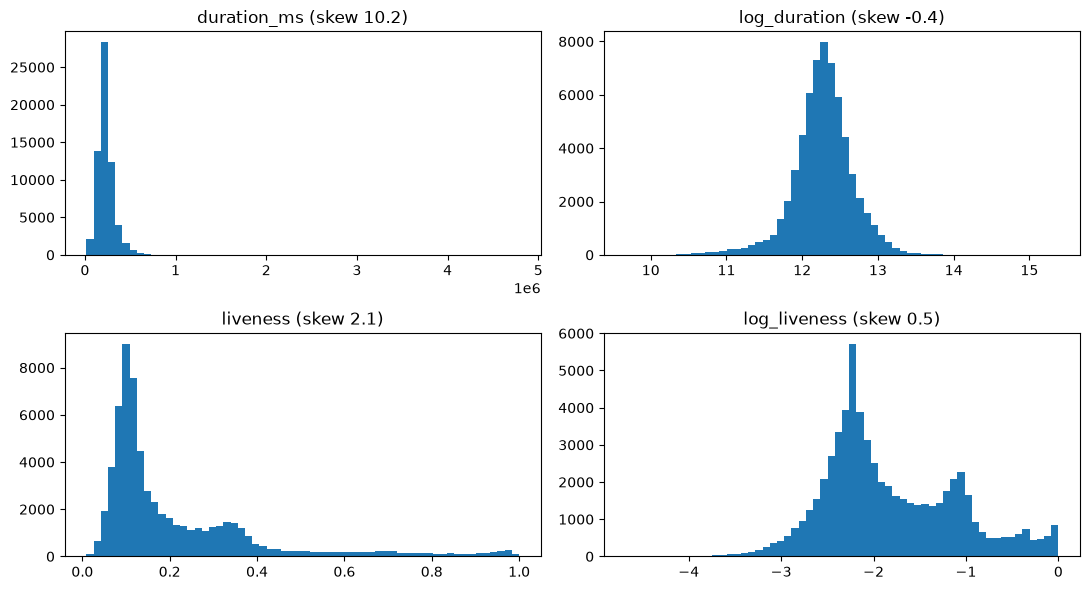

In [ ]:
for d in (train, test):
    d["log_duration"] = np.log(d["duration_ms"])
    d["log_liveness"] = np.log(d["liveness"])

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, (raw_col, log_col) in enumerate([("duration_ms", "log_duration"), ("liveness", "log_liveness")]):
    axes[row, 0].hist(train[raw_col], bins=60)
    axes[row, 0].set_title(f"{raw_col} (skew {train[raw_col].skew():.1f})")
    axes[row, 1].hist(train[log_col], bins=60)
    axes[row, 1].set_title(f"{log_col} (skew {train[log_col].skew():.1f})")
plt.tight_layout()
plt.show()

### Test: log of `speechiness`

`speechiness` is right-skewed too. We check whether a log helps, by looking at the skew **and** at how much the feature relates to valence.

In [ ]:
log_speech = np.log(train["speechiness"])
print(f"skew: {train['speechiness'].skew():.1f} before log, {log_speech.skew():.1f} after")
print(f"correlation with valence: {train['speechiness'].corr(train['valence']):.2f} before log, {log_speech.corr(train['valence']):.2f} after")

skew: 2.8 before log, 1.1 after
correlation with valence: 0.06 before log, 0.07 after


**Result:** the log lowers the skew (2.8 to 1.1), but speechiness barely relates to valence either way (correlation 0.06 vs. 0.07).
A log only helps if it makes the feature more useful, and here it doesn't. **We keep speechiness as it is.**

## 4. Yes/no flags: instrumental and slow songs

EDA found two features where a simple yes/no split captures most of the effect:
- **`instrumentalness`** is almost 0 for two thirds of songs, with a second group near 0.9. Songs above 0.5 average 0.31 valence, vs. 0.51 for the rest.
- **`tempo`** only matters for very slow songs. Songs under 85 BPM average 0.37 valence, vs. 0.48 for the rest.

The cut-offs (0.5 and 85) were picked from plots of the **training set**, so the test set played no part in choosing them.
We add the flags next to the original columns, so the models get both the exact value and the simple yes/no.

In [ ]:
for d in (train, test):
    d["is_instrumental"] = (d["instrumentalness"] > 0.5).astype(int)
    d["is_slow"] = (d["tempo"] < 85).astype(int)

for flag in ["is_instrumental", "is_slow"]:
    means = train.groupby(flag)["valence"].mean()
    print(f"{flag}: {train[flag].mean():.0%} of songs, mean valence {means[1]:.2f} (yes) vs {means[0]:.2f} (no)")

is_instrumental: 19% of songs, mean valence 0.31 (yes) vs 0.51 (no)
is_slow: 10% of songs, mean valence 0.37 (yes) vs 0.48 (no)


## 5. Squared terms for `energy` and `acousticness`

EDA found that these two features have **curved** relationships with valence:
- **energy:** valence goes up with energy, then drops for the most energetic songs. Very calm and very intense songs are both sadder.
- **acousticness:** an upside-down U. Songs with almost no acoustic sound and very acoustic songs are both sadder.

A linear model can only draw straight lines. If we add `energy²` next to `energy`, it can draw a curve (a parabola) instead.
EDA showed that a squared term almost doubles R² for energy (0.061 to 0.113) and raises acousticness from 0.007 to 0.078.

In [ ]:
for d in (train, test):
    d["energy_sq"] = d["energy"] ** 2
    d["acousticness_sq"] = d["acousticness"] ** 2

## 6. Interaction terms

An interaction term (two features multiplied) lets the effect of one feature depend on the other.
We tested three ideas:
- `energy × acousticness` (from our project plan)
- `energy × danceability` (suggested by EDA, to separate intense sad songs from happy dance songs)
- `mode × energy` (from our project plan: is a minor, low-energy song extra sad?)

**How we tested them:** for each idea, we fit a straight line using the two features alone, then again with the product added, on the training set.
If R² goes up clearly, the product adds something the two features can't show by themselves.

In [ ]:
def r2_linear(data, cols):
    """R² of a least-squares straight-line fit of valence on the given columns."""
    X = np.column_stack([np.ones(len(data))] + [data[c] for c in cols])
    y = data["valence"].to_numpy()
    coefs, *_ = np.linalg.lstsq(X, y, rcond=None)
    pred = X @ coefs
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

check = train.copy()
rows = []
for a, b in [("energy", "acousticness"), ("energy", "danceability"), ("mode", "energy")]:
    check["product"] = check[a] * check[b]
    without = r2_linear(check, [a, b])
    with_product = r2_linear(check, [a, b, "product"])
    rows.append({"interaction": f"{a} x {b}", "R² without": round(without, 3),
                 "R² with": round(with_product, 3), "gain": round(with_product - without, 3)})
pd.DataFrame(rows)

,interaction,R² without,R² with,gain
0,energy x acousticness,0.084,0.161,0.077
1,energy x danceability,0.264,0.265,0.002
2,mode x energy,0.064,0.064,0.000


In [ ]:
# Why does energy x acousticness help? Acousticness means different things for calm and intense songs.
for name, part in [("energy > 0.8", train[train["energy"] > 0.8]), ("energy < 0.4", train[train["energy"] < 0.4])]:
    print(f"{name}: correlation of acousticness with valence = {part['acousticness'].corr(part['valence']):.2f}")

energy > 0.8: correlation of acousticness with valence = 0.35
energy < 0.4: correlation of acousticness with valence = -0.12


**Result:**
- **`energy × acousticness` helps a lot**: R² almost doubles (0.084 to 0.161). For intense songs, more acoustic sound goes with *happier* songs (correlation +0.35).
  For calm songs it goes slightly the other way (−0.12). One straight line for acousticness can't show this, but the product can. **We keep it.**
- **`energy × danceability` adds nothing** (R² 0.264 to 0.265). Danceability raises valence by about the same amount whether a song is calm or intense, so the two features already cover it. **We drop it.**
- **`mode × energy` adds nothing** (0.064 to 0.064). Mode barely relates to valence in any energy range. **We drop it.**

In [ ]:
for d in (train, test):
    d["energy_x_acousticness"] = d["energy"] * d["acousticness"]

## 7. Test: PCA features

PCA combines the audio features into new "components". The first few components keep most of the variation in the data, so PCA is often used to get fewer features.
We test whether the components would be good model inputs, using the same straight-line R² check as in section 6.
The scaler and PCA are fit on the training set only.

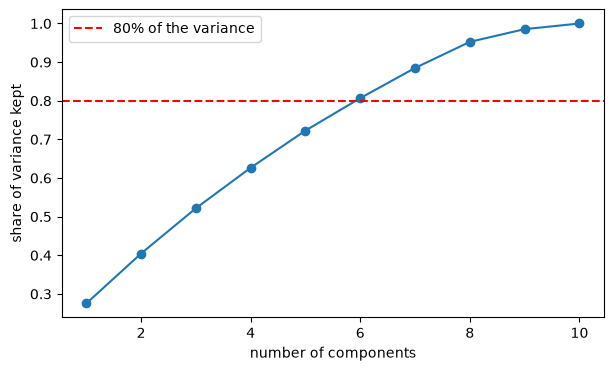

Components needed to keep 80% of the variance: 6 of 10
R² with the 10 original features: 0.377
R² with the first 2 components:   0.223
R² with the first 6 components:   0.261


In [ ]:
PCA_COLS = ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
            "log_liveness", "tempo", "log_duration", "mode"]

scaled = StandardScaler().fit_transform(train[PCA_COLS])
pca = PCA(random_state=RANDOM_STATE).fit(scaled)
components = pca.transform(scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.8, color="red", ls="--", label="80% of the variance")
plt.xlabel("number of components")
plt.ylabel("share of variance kept")
plt.legend()
plt.show()

pc_data = pd.DataFrame(components, columns=[f"PC{i + 1}" for i in range(len(PCA_COLS))], index=train.index)
pc_data["valence"] = train["valence"]
print(f"Components needed to keep 80% of the variance: {np.argmax(cum_var >= 0.8) + 1} of {len(PCA_COLS)}")
print(f"R² with the 10 original features: {r2_linear(train, PCA_COLS):.3f}")
print(f"R² with the first 2 components:   {r2_linear(pc_data, ['PC1', 'PC2']):.3f}")
print(f"R² with the first 6 components:   {r2_linear(pc_data, [f'PC{i}' for i in range(1, 7)]):.3f}")

**Result:**
- We need **6 of the 10 components** to keep 80% of the variance, so PCA doesn't shrink the data much. The audio features don't overlap that much.
- Those 6 components predict valence clearly worse than the 10 original features (R² 0.261 vs. 0.377).
  PCA keeps the directions where the features vary the most, but it never looks at valence. The parts it throws away still matter for predicting valence.
- Components are mixes of features (for example, PC1 is mostly energy and loudness against acousticness), so a model built on them is hard to explain.

**We don't use PCA features in the models.**

## 8. The classification label

For the classification task, a song is "sad" if `valence < 0.3`. This is a fixed rule, so we add it to both sets.
EDA found that 31% of training songs are sad. The classes are a bit imbalanced, so the team uses F1 and ROC-AUC, not just accuracy.

`sad` is built from `valence`, so **neither `sad` nor `valence` may be used as an input feature**.

In [ ]:
for d in (train, test):
    d["sad"] = (d["valence"] < 0.3).astype(int)

print(f"Share of sad songs: train {train['sad'].mean():.1%}, test {test['sad'].mean():.1%}")

Share of sad songs: train 31.0%, test 31.0%


## 9. The final features

This is the one feature list every model uses.

In [ ]:
FEATURES = (
    ["danceability", "energy", "loudness", "speechiness", "acousticness", "instrumentalness",
     "log_liveness", "tempo", "log_duration", "mode", "explicit"]                         # audio features
    + KEY_COLS                                                                            # 4.1
    + ["is_4_4", "is_instrumental", "is_slow",                                            # 4.2, 4.4
       "energy_sq", "acousticness_sq", "energy_x_acousticness"]                           # 4.5, 4.6
    + GENRE_COLS                                                                          # 4.1
)

assert "valence" not in FEATURES and "sad" not in FEATURES   # leakage check
print(f"{len(FEATURES)} features: 11 audio, {len(KEY_COLS)} key, 6 new, {len(GENRE_COLS)} genre")

141 features: 11 audio, 12 key, 6 new, 112 genre


## 10. Save the final data

We save one training file and one test file. Each has the features, the two targets (`valence` and `sad`), and `track_genre`.
`track_genre` is **not** an input (the genre columns already cover it). It is only there so the team can look at errors by genre.

**Scaling.** The features have very different ranges: `loudness` is about −42 to 0 dB, `tempo` about 30 to 240, and most others are 0 to 1.
kNN, linear models, and neural networks need the features scaled with `StandardScaler`. Tree models don't.
We don't save scaled files. The scaler should be fit inside each cross-validation fold, as part of a `Pipeline`.
If we scaled the whole training set once, the mean and spread would include the validation fold, which is a small leak.

In [ ]:
save_cols = FEATURES + ["valence", "sad", "track_genre"]
train[save_cols].to_csv("train_features.csv", index=False)
test[save_cols].to_csv("test_features.csv", index=False)
print(f"Saved train_features.csv {train[save_cols].shape} and test_features.csv {test[save_cols].shape}")

Saved train_features.csv (63138, 144) and test_features.csv (15785, 144)


**For the modeling parts:** Parts 4 to 6 load the final data like this.

```python
train = pd.read_csv("train_features.csv")
test = pd.read_csv("test_features.csv")

X_train = train.drop(columns=["valence", "sad", "track_genre"])
y_train = train["valence"]        # regression target
y_train_sad = train["sad"]        # classification target
```

- For kNN, linear models, and neural networks, put the scaler in a pipeline: `make_pipeline(StandardScaler(), model)`.
- Do all tuning with cross-validation on `train`. Use `test` only for the final scores.

## 11. Summary of features

| Feature | What it is | Why |
|---|---|---|
| `explicit` | 0/1 instead of True/False | Models need numbers |
| `key_0` ... `key_11` | One-hot key | Key is a category, not a number |
| `genre_*` (112) | One-hot genre | Genre explains about a third of valence |
| `is_4_4` | 1 if the song is in 4/4 (replaces `time_signature`) | All other time signatures have lower valence; 0 and 1 are errors |
| `log_duration`, `log_liveness` | Log transform (replaces the originals) | Very right-skewed (skew 10.2 and 2.1) |
| `is_instrumental` | `instrumentalness > 0.5` | Instrumentalness is almost yes/no; valence 0.31 vs. 0.51 |
| `is_slow` | `tempo < 85` | Tempo only matters for very slow songs; valence 0.37 vs. 0.48 |
| `energy_sq`, `acousticness_sq` | Squared terms | Curved relationships with valence |
| `energy_x_acousticness` | Product | R² 0.084 to 0.161; acousticness means different things for calm and intense songs |

**What we tried and did not keep:**

| Idea | Why not |
|---|---|
| `energy × danceability` | No gain (R² 0.264 to 0.265) |
| `mode × energy` | No gain (R² 0.064 to 0.064) |
| Log of `speechiness` | Lowers the skew, but speechiness barely relates to valence either way (correlation 0.06 vs. 0.07) |
| Grouping genres into 12 families | Explains only 16% of valence vs. 32% for the full genres; we have enough data for all 112 |
| PCA features | Needs 6 of 10 components for 80% of the variance, and those predict valence worse than the original features (R² 0.261 vs. 0.377). |

---

# Part 4: Baseline and Linear Models

*By Aryan.*

In this part we train a baseline, linear regression, ridge, lasso, and logistic regression.
We do both tasks, predicting `valence` (regression) and predicting whether a song is sad, meaning `valence < 0.3` (classification).
The inputs are the 141 features in `train_features.csv`. All tuning is done with 5-fold cross-validation on the training set, and `test_features.csv` is only used at the end.

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, lasso_path
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, train_test_split)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, average_precision_score)

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3

We only load the training set here. The test set is loaded at the end.

In [ ]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"])
y = train_df["valence"]          # regression target
y_sad = train_df["sad"]          # classification target
genre = train_df["track_genre"]  # only used to look at errors by genre

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Preprocessing

The features are already encoded (one-hot genre and key, the flags, and the log, squared, and interaction terms from feature engineering).
Linear models are sensitive to the scale of the features, so every model is a `Pipeline` that standardizes the features inside each training fold. This also lets us compare coefficients later.

In [ ]:
GENRE_COLS = [c for c in X.columns if c.startswith("genre_")]
KEY_COLS = [c for c in X.columns if c.startswith("key_")]
AUDIO_COLS = [c for c in X.columns if c not in GENRE_COLS]   # everything except genre
BASE_COLS = ["danceability", "energy", "loudness", "speechiness", "acousticness",
             "instrumentalness", "log_liveness", "tempo", "log_duration"]
ENGINEERED_TERMS = ["energy_sq", "acousticness_sq", "energy_x_acousticness"]
SMALL_COLS = [c for c in AUDIO_COLS if c not in KEY_COLS]     # the 17 non-one-hot features
print(f"{len(GENRE_COLS)} genre columns, {len(KEY_COLS)} key columns, {len(SMALL_COLS)} other features")

def make_pipe(model, cols=None, poly=False):
    """Scale the chosen columns (all by default), optionally add degree-2 terms for the base audio features."""
    cols = cols or list(X.columns)
    if poly:
        rest = [c for c in cols if c not in BASE_COLS + ENGINEERED_TERMS]
        pre = ColumnTransformer([
            ("poly", Pipeline([("scale", StandardScaler()),
                               ("poly", PolynomialFeatures(2, include_bias=False))]), BASE_COLS),
            ("rest", StandardScaler(), rest),
        ])
    else:
        pre = ColumnTransformer([("scale", StandardScaler(), cols)])
    return Pipeline([("pre", pre), ("model", model)])

# The same folds are used for every model, so the scores are comparable.
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # keeps 31% sad in every fold

112 genre columns, 12 key columns, 17 other features


### Results table

Two functions that score a model with 5-fold cross-validation and save the result in a table.

In [ ]:
reg_results = []
clf_results = []

def eval_regressor(name, model, X_=X, y_=y, notes=""):
    """5-fold CV for a regression pipeline. Returns the scores and saves a row in reg_results."""
    s = cross_validate(model, X_, y_, cv=kf, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error",
                                "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -s["test_rmse"].mean(), "RMSE_std": s["test_rmse"].std(),
           "MAE": -s["test_mae"].mean(), "R2": s["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def eval_classifier(name, model, X_=X, y_=y_sad, threshold=0.5, notes=""):
    """5-fold CV for a classifier. Uses out-of-fold probabilities so we can apply any threshold."""
    proba = cross_val_predict(model, X_, y_, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_, pred), "ROC_AUC": roc_auc_score(y_, proba),
           "accuracy": (pred == y_).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, accuracy {row['accuracy']:.4f}")
    return row, proba

## 3. Baselines

For regression, the baseline always predicts the mean valence. For classification, the baseline always predicts "not sad".

In [ ]:
eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000


In [ ]:
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


Predicting the mean gives an RMSE of about 0.26. Always guessing "not sad" is 69% accurate but has an F1 of 0, so we use F1 and ROC-AUC instead of accuracy.

## 4. Regression

### 4.1 Did feature engineering help?

We compare linear regression on the cleaned features before feature engineering (`train_clean.csv`, with genre, key, and time signature one-hot encoded) and on the engineered features.
Both files have the same songs in the same order, so the two versions are scored on exactly the same folds. We also check each version with and without genre.

In [ ]:
raw_df = pd.read_csv("train_clean.csv")
assert (raw_df["valence"].values == y.values).all()   # same songs, same order

X_raw = raw_df.drop(columns=["valence"])
X_raw["explicit"] = X_raw["explicit"].astype(int)
RAW_NUM = [c for c in X_raw.columns if c not in ["track_genre", "key", "time_signature"]]

def make_raw_pipe(cat_cols):
    pre = ColumnTransformer([("num", StandardScaler(), RAW_NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
    return Pipeline([("pre", pre), ("model", LinearRegression())])

lin_raw_audio = make_raw_pipe(["key", "time_signature"])
lin_raw = make_raw_pipe(["track_genre", "key", "time_signature"])
lin_audio = make_pipe(LinearRegression(), AUDIO_COLS)
lin_full = make_pipe(LinearRegression())

eval_regressor("Linear regression (raw, no genre)", lin_raw_audio, X_raw, notes="before feature engineering")
eval_regressor("Linear regression (raw + genre)", lin_raw, X_raw, notes="before feature engineering")
eval_regressor("Linear regression (engineered, no genre)", lin_audio, notes="engineered features")
eval_regressor("Linear regression (engineered + genre)", lin_full, notes="engineered features");

Linear regression (raw, no genre): RMSE 0.2070 (+/- 0.0016), MAE 0.1689, R2 0.3762


Linear regression (raw + genre): RMSE 0.1842 (+/- 0.0009), MAE 0.1480, R2 0.5060


Linear regression (engineered, no genre): RMSE 0.2035 (+/- 0.0018), MAE 0.1660, R2 0.3971


Linear regression (engineered + genre): RMSE 0.1822 (+/- 0.0009), MAE 0.1464, R2 0.5170


The engineered features improve R² both without genre (0.376 to 0.397) and with genre (0.506 to 0.517). The gain is smaller once genre is in, because genre already explains some of what the new features capture.
Genre is still the biggest single improvement (about 0.12 R²), so we keep it in all the models below.

### 4.2 Ridge and lasso

Ridge and lasso add a penalty on large coefficients, controlled by `alpha`. Lasso can also set coefficients to 0. We tune `alpha` with grid search.

In [ ]:
ridge_grid = GridSearchCV(make_pipe(Ridge()), {"model__alpha": np.logspace(-3, 4, 15)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X, y)
print("Best ridge alpha:", ridge_grid.best_params_["model__alpha"])

lasso_grid = GridSearchCV(make_pipe(Lasso(max_iter=10000)), {"model__alpha": np.logspace(-6, -1, 11)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X, y)
print("Best lasso alpha:", lasso_grid.best_params_["model__alpha"])

Best ridge alpha: 3.1622776601683795


Best lasso alpha: 3.1622776601683795e-05


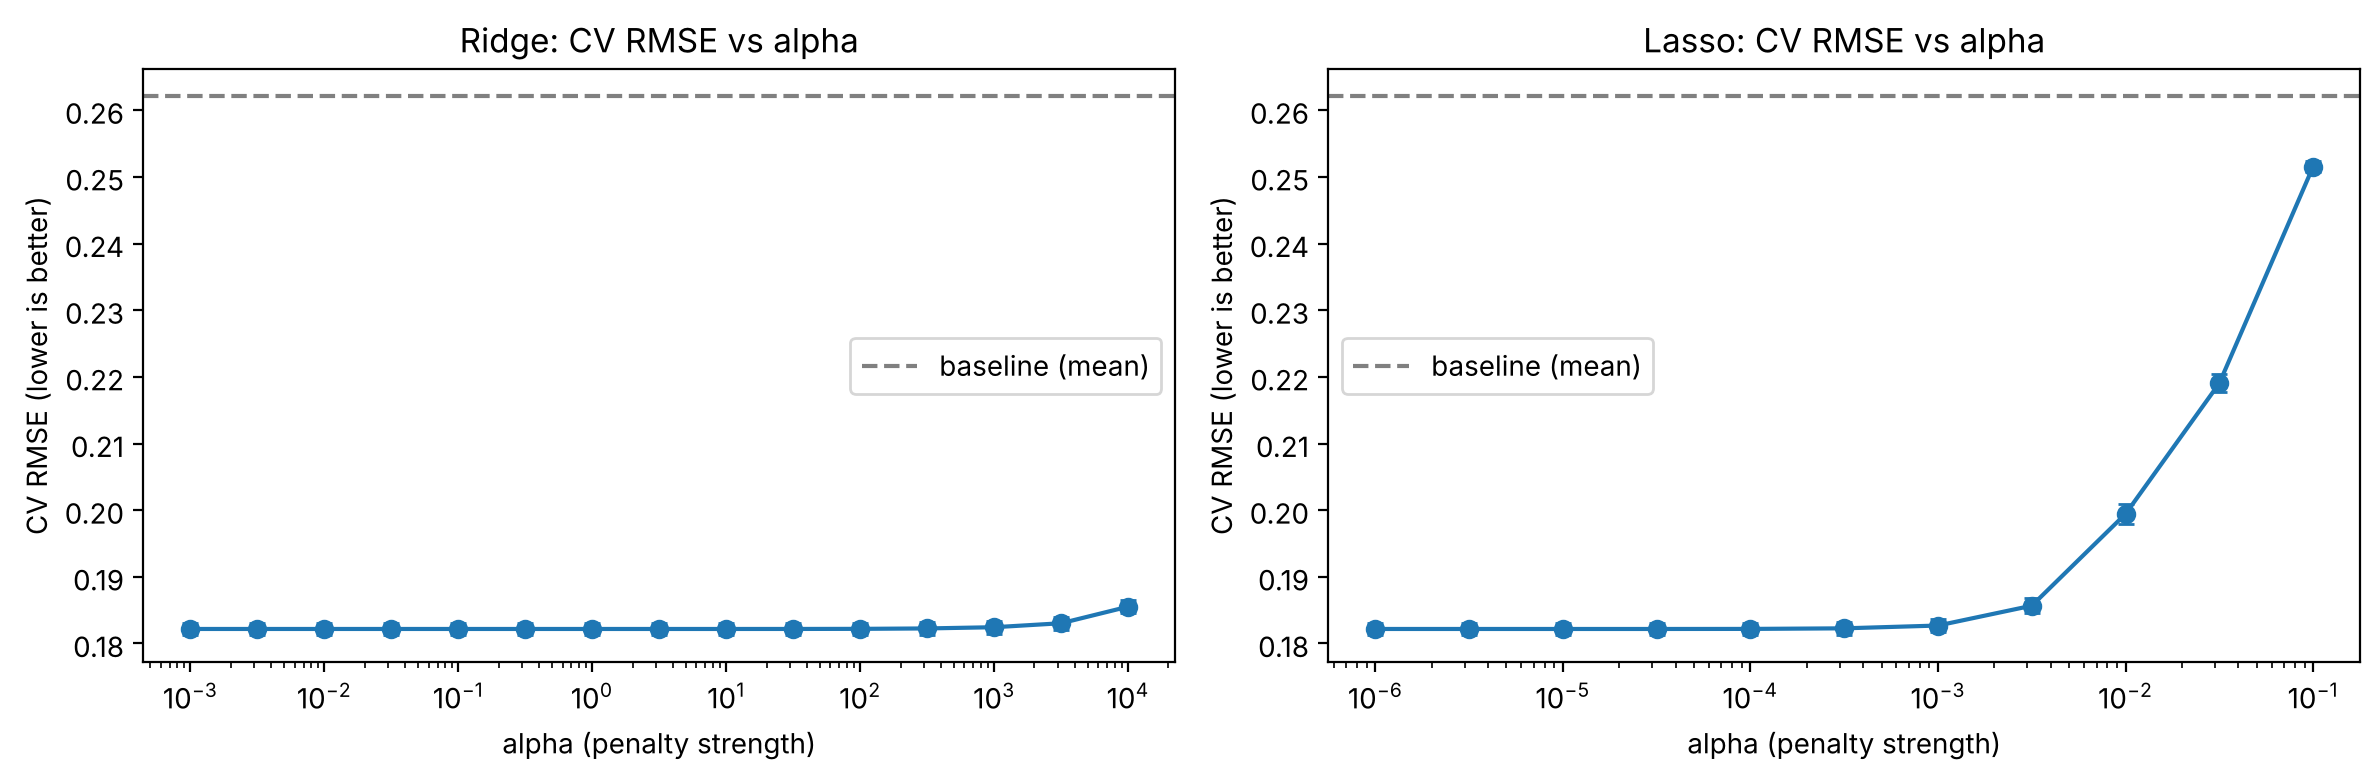

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, name in [(axes[0], ridge_grid, "Ridge"), (axes[1], lasso_grid, "Lasso")]:
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    mean_rmse = -grid.cv_results_["mean_test_score"]
    std_rmse = grid.cv_results_["std_test_score"]
    ax.errorbar(alphas, mean_rmse, yerr=std_rmse, marker="o", capsize=3)
    ax.axhline(reg_results[0]["RMSE"], color="gray", ls="--", label="baseline (mean)")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (penalty strength)")
    ax.set_ylabel("CV RMSE (lower is better)")
    ax.set_title(f"{name}: CV RMSE vs alpha")
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
eval_regressor("Ridge (tuned)", ridge_grid.best_estimator_,
               notes=f"alpha={ridge_grid.best_params_['model__alpha']:.3g}")
eval_regressor("Lasso (tuned)", lasso_grid.best_estimator_,
               notes=f"alpha={lasso_grid.best_params_['model__alpha']:.3g}");

Ridge (tuned): RMSE 0.1822 (+/- 0.0009), MAE 0.1464, R2 0.5170


Lasso (tuned): RMSE 0.1822 (+/- 0.0009), MAE 0.1465, R2 0.5170


Ridge and lasso score the same as plain linear regression, and a large alpha only makes things worse.
We have about 63,000 songs and 141 features, so the model isn't overfitting and the penalty doesn't have much to fix.

### 4.3 Polynomial features

Feature engineering added squared terms for energy and acousticness and an energy × acousticness term. Here we go further and add every squared and pairwise product term for the 9 continuous audio features, to see if other curves or interactions matter. We don't do this for the genre and key columns, since it would add thousands of columns.

In [ ]:
ridge_poly_grid = GridSearchCV(make_pipe(Ridge(), poly=True), {"model__alpha": np.logspace(-2, 4, 13)},
                               cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_poly_grid.fit(X, y)
print("Best alpha:", ridge_poly_grid.best_params_["model__alpha"])

eval_regressor("Ridge + degree-2 polynomial (tuned)", ridge_poly_grid.best_estimator_,
               notes=f"alpha={ridge_poly_grid.best_params_['model__alpha']:.3g}");

Best alpha: 31.622776601683793


Ridge + degree-2 polynomial (tuned): RMSE 0.1787 (+/- 0.0010), MAE 0.1429, R2 0.5352


This lowers RMSE from 0.182 to 0.179 (R² 0.517 to 0.535). That gain is bigger than the gain from feature engineering, so the hand-picked squared and interaction terms don't capture every curve or interaction. Models that learn these on their own, like trees, may do better.

### 4.4 Lasso path

As alpha goes up, lasso sets more coefficients to 0. Features that stay in the longest are the most useful. We use the 17 features that aren't genre or key columns, so the plot is readable.

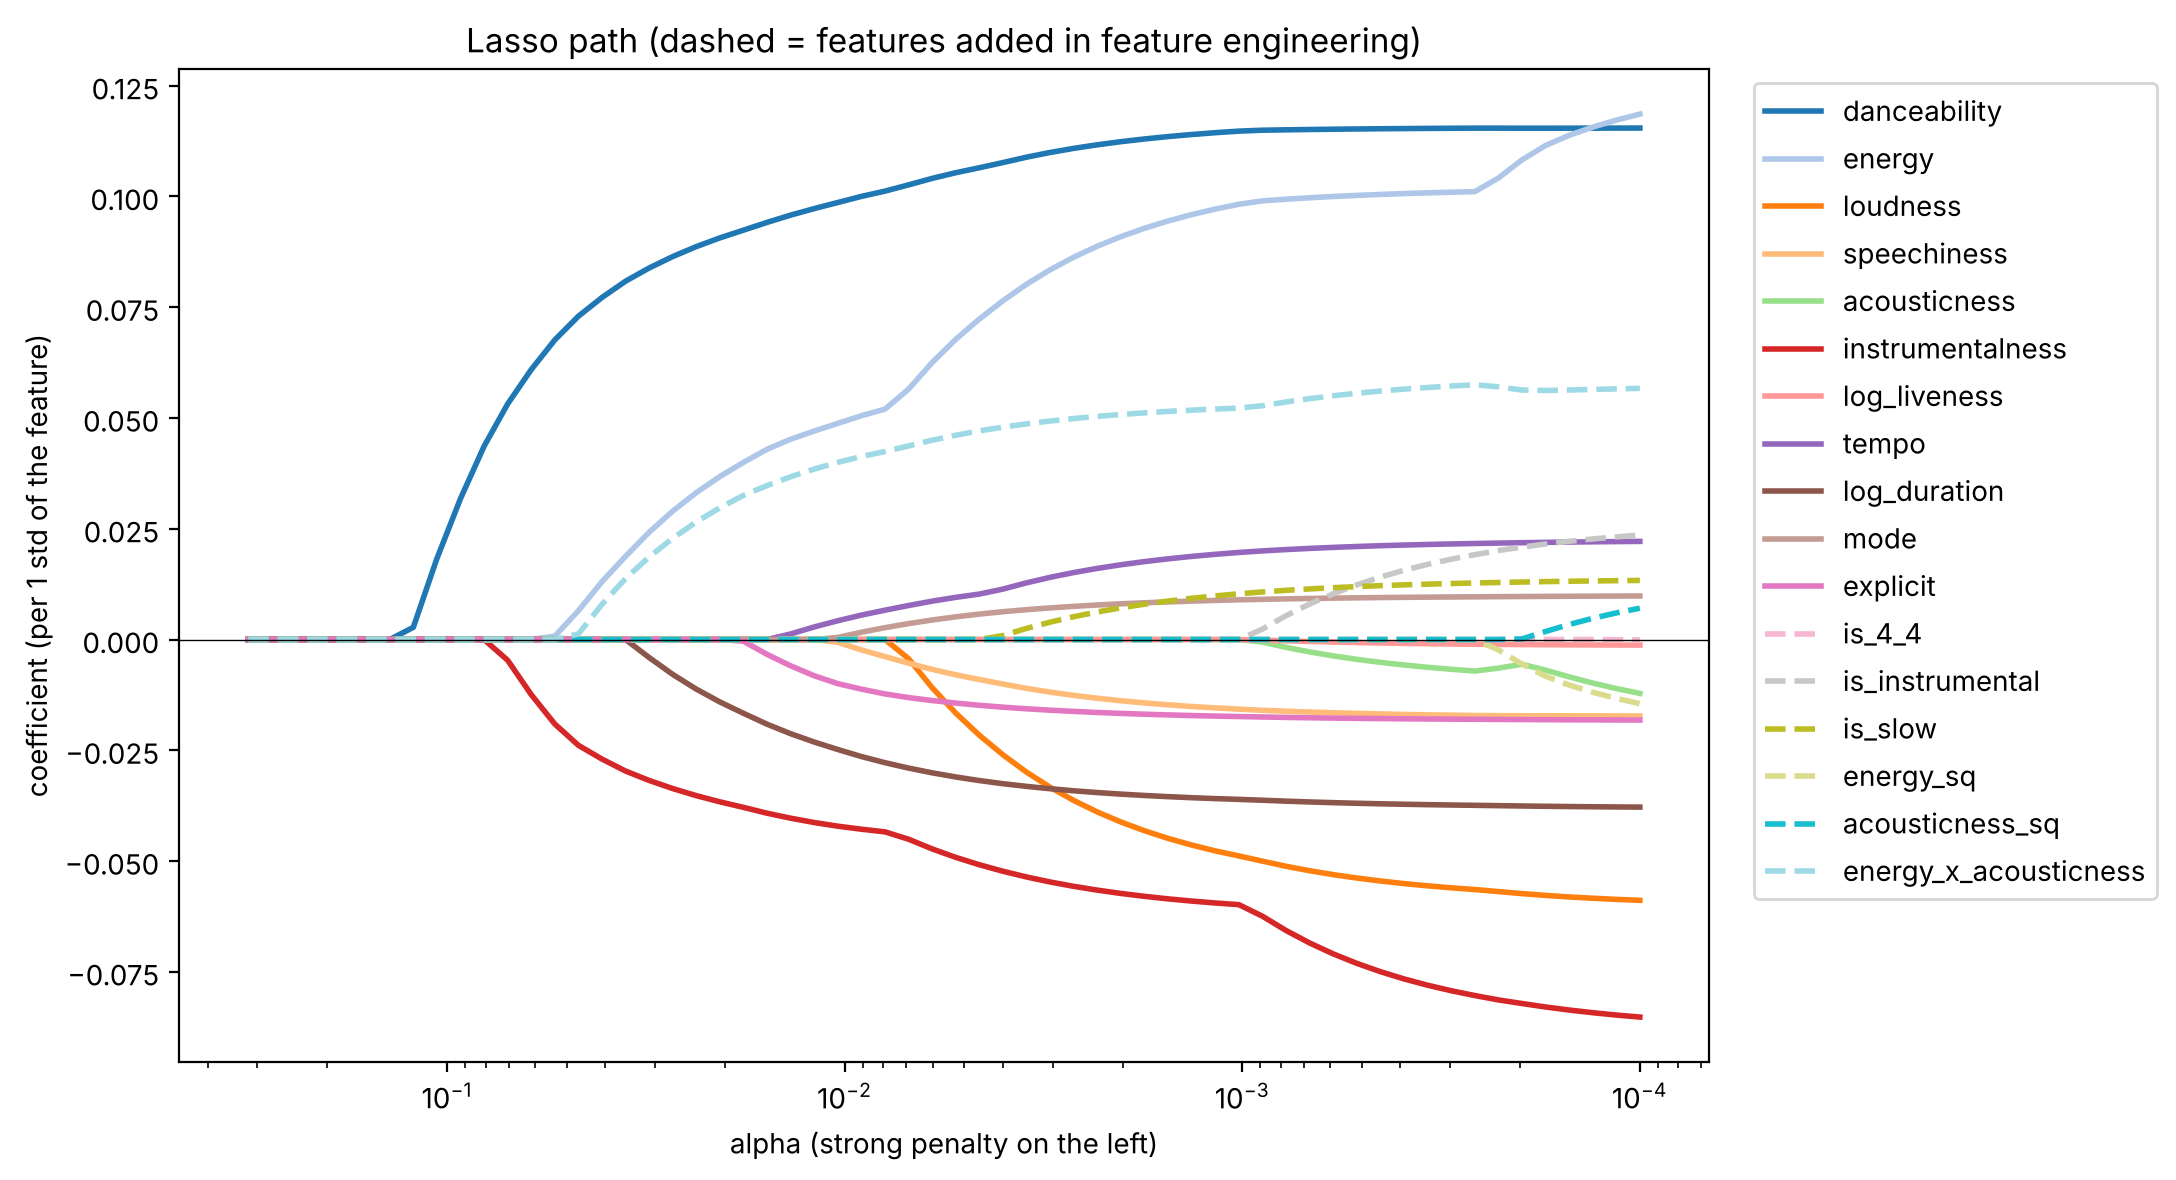

Features in the order lasso keeps them (first = most important):
  danceability           enters at alpha = 0.1215
  instrumentalness       enters at alpha = 0.0704
  energy                 enters at alpha = 0.0536
  energy_x_acousticness  enters at alpha = 0.0467
  log_duration           enters at alpha = 0.0310
  explicit               enters at alpha = 0.0180
  tempo                  enters at alpha = 0.0137
  speechiness            enters at alpha = 0.0104
  mode                   enters at alpha = 0.0104
  loudness               enters at alpha = 0.0069
  is_slow                enters at alpha = 0.0040
  acousticness           enters at alpha = 0.0009
  log_liveness           enters at alpha = 0.0009
  is_instrumental        enters at alpha = 0.0009
  energy_sq              enters at alpha = 0.0002
  acousticness_sq        enters at alpha = 0.0002
  is_4_4                 enters at alpha = 0.0001


In [ ]:
X_small_scaled = StandardScaler().fit_transform(X[SMALL_COLS])
alphas_path, coefs_path, _ = lasso_path(X_small_scaled, y - y.mean(), alphas=np.logspace(-4, -0.5, 60))

fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(SMALL_COLS)))
for i, col in enumerate(SMALL_COLS):
    ax.plot(alphas_path, coefs_path[i], label=col, color=colors[i], lw=2,
            ls="--" if col in ENGINEERED_TERMS or col.startswith("is_") else "-")
ax.set_xscale("log")
ax.invert_xaxis()                       # left = strong penalty, right = weak penalty
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("alpha (strong penalty on the left)")
ax.set_ylabel("coefficient (per 1 std of the feature)")
ax.set_title("Lasso path (dashed = features added in feature engineering)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Order in which features first become non-zero (as the penalty gets weaker)
first_alpha = {col: (alphas_path[np.nonzero(coefs_path[i])[0][0]] if np.any(coefs_path[i]) else 0)
               for i, col in enumerate(SMALL_COLS)}
print("Features in the order lasso keeps them (first = most important):")
for col, a in sorted(first_alpha.items(), key=lambda kv: -kv[1]):
    print(f"  {col:22s} enters at alpha = {a:.4f}")

Danceability is kept first, then instrumentalness, energy, and energy × acousticness. That interaction term is the most useful feature added in feature engineering. The other engineered features come in late with small coefficients, and `is_4_4` comes in last.

Mode also comes in late with a small coefficient, so major vs. minor key barely matters.

### 4.5 Regression results (cross-validation)

In [ ]:
pd.DataFrame(reg_results).round(4)

,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,"Linear regression (raw, no genre)",0.2070,0.0016,0.1689,0.3762,before feature engineering
2,Linear regression (raw + genre),0.1842,0.0009,0.1480,0.5060,before feature engineering
3,"Linear regression (engineered, no genre)",0.2035,0.0018,0.1660,0.3971,engineered features
4,Linear regression (engineered + genre),0.1822,0.0009,0.1464,0.5170,engineered features
5,Ridge (tuned),0.1822,0.0009,0.1464,0.5170,alpha=3.16
6,Lasso (tuned),0.1822,0.0009,0.1465,0.5170,alpha=3.16e-05
7,Ridge + degree-2 polynomial (tuned),0.1787,0.0010,0.1429,0.5352,alpha=31.6


## 5. Classification

### 5.1 Logistic regression

We tune `C` (smaller C means a stronger penalty) and `class_weight`. Since only 31% of songs are sad, `class_weight="balanced"` makes mistakes on sad songs count more. We score with ROC-AUC.

In [ ]:
logreg_grid = GridSearchCV(make_pipe(LogisticRegression(max_iter=3000)),
                           {"model__C": np.logspace(-3, 2, 6),
                            "model__class_weight": [None, "balanced"]},
                           cv=skf, scoring="roc_auc", n_jobs=-1)
logreg_grid.fit(X, y_sad)
print("Best settings:", logreg_grid.best_params_)
print(f"Best CV ROC-AUC: {logreg_grid.best_score_:.4f}")

Best settings: {'model__C': np.float64(100.0), 'model__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8656


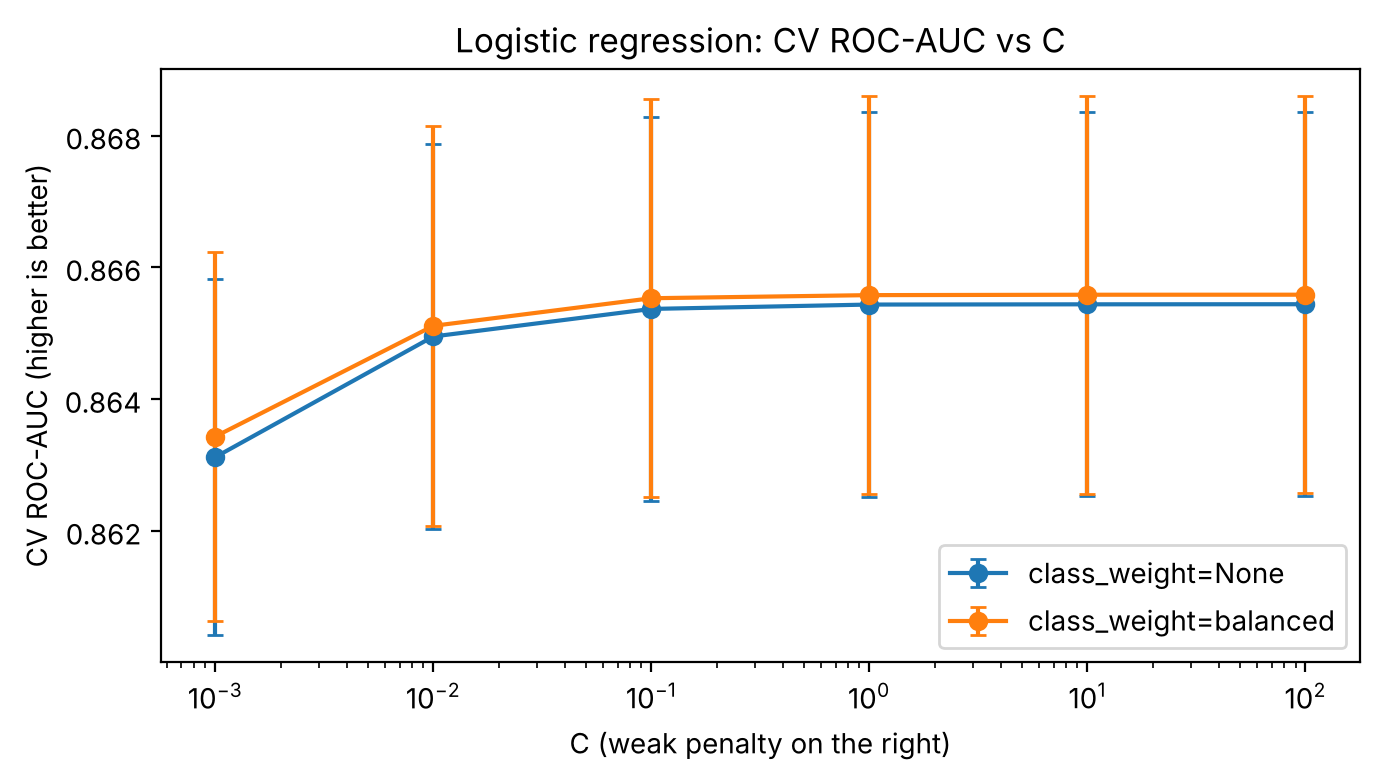

In [ ]:
cv = pd.DataFrame(logreg_grid.cv_results_)
cv["class_weight"] = cv["param_model__class_weight"].map(lambda v: "balanced" if v == "balanced" else "None")
fig, ax = plt.subplots(figsize=(7, 4))
for cw, g in cv.groupby("class_weight"):
    ax.errorbar(g["param_model__C"].astype(float), g["mean_test_score"], yerr=g["std_test_score"],
                marker="o", capsize=3, label=f"class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (weak penalty on the right)")
ax.set_ylabel("CV ROC-AUC (higher is better)")
ax.set_title("Logistic regression: CV ROC-AUC vs C")
ax.legend()
plt.tight_layout()
plt.show()

ROC-AUC levels off from about C = 0.1, so any C from 0.1 to 100 gives almost the same score (grid search picks C = 100 by a very small margin). Class weight barely changes ROC-AUC, since ROC-AUC only depends on how songs are ranked, not on the threshold.

As in regression, we also check logistic regression on the features before feature engineering, with the same settings and folds.

In [ ]:
logreg_raw = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), RAW_NUM),
                                                  ("cat", OneHotEncoder(handle_unknown="ignore"),
                                                   ["track_genre", "key", "time_signature"])])),
                       ("model", LogisticRegression(max_iter=3000, C=logreg_grid.best_params_["model__C"],
                                                    class_weight=logreg_grid.best_params_["model__class_weight"]))])
raw_auc = cross_validate(logreg_raw, X_raw, y_sad, cv=skf, scoring="roc_auc", n_jobs=-1)["test_score"].mean()
print(f"CV ROC-AUC before feature engineering: {raw_auc:.4f}, after: {logreg_grid.best_score_:.4f}")

CV ROC-AUC before feature engineering: 0.8625, after: 0.8656


Feature engineering raises ROC-AUC a little, from 0.8625 to 0.8656.

### 5.2 Choosing the threshold

We pick the threshold that gives the best F1, using out-of-fold predictions on the training set.

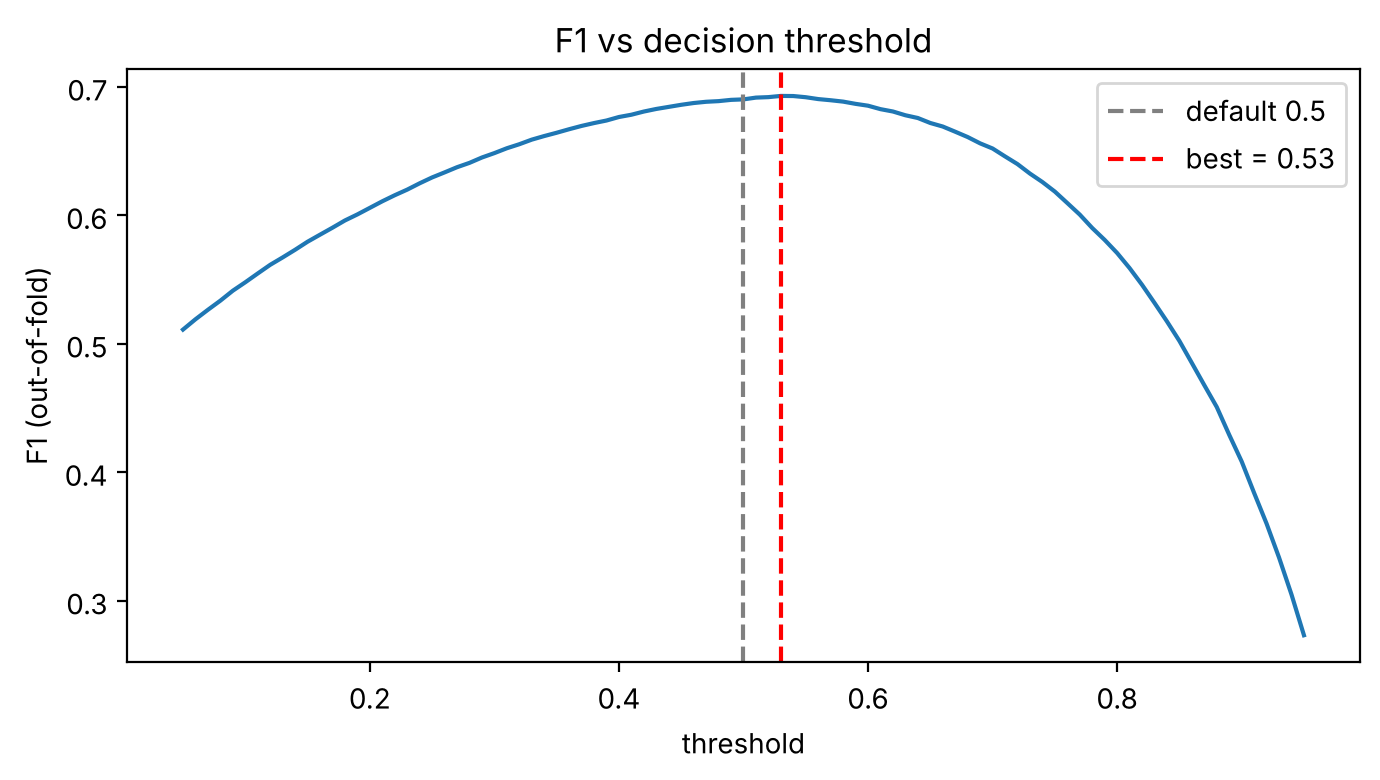

Best threshold: 0.53, F1 = 0.6930 (vs. 0.6903 at 0.5)


In [ ]:
best_logreg = logreg_grid.best_estimator_
oof_proba = cross_val_predict(best_logreg, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_sad, (oof_proba >= t).astype(int)) for t in thresholds]
best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, f1s)
ax.axvline(0.5, color="gray", ls="--", label="default 0.5")
ax.axvline(best_t, color="red", ls="--", label=f"best = {best_t:.2f}")
ax.set_xlabel("threshold")
ax.set_ylabel("F1 (out-of-fold)")
ax.set_title("F1 vs decision threshold")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Best threshold: {best_t:.2f}, F1 = {max(f1s):.4f} (vs. {f1_score(y_sad, (oof_proba >= 0.5).astype(int)):.4f} at 0.5)")

In [ ]:
cw_note = f"C={logreg_grid.best_params_['model__C']:.3g}, class_weight={logreg_grid.best_params_['model__class_weight']}"
eval_classifier("Logistic regression (tuned, threshold 0.5)", best_logreg, threshold=0.5, notes=cw_note)
eval_classifier(f"Logistic regression (tuned, threshold {best_t:.2f})", best_logreg, threshold=best_t, notes=cw_note);

Logistic regression (tuned, threshold 0.5): F1 0.6903, ROC-AUC 0.8656, accuracy 0.7829


Logistic regression (tuned, threshold 0.53): F1 0.6930, ROC-AUC 0.8656, accuracy 0.7916


The best threshold is 0.53, close to 0.5, because the balanced class weights already make up for the imbalance. As a check, here is the same search without class weights.

In [ ]:
unweighted = make_pipe(LogisticRegression(C=logreg_grid.best_params_["model__C"], max_iter=3000))
oof_unw = cross_val_predict(unweighted, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
f1s_unw = [f1_score(y_sad, (oof_unw >= t).astype(int)) for t in thresholds]
best_t_unw = round(float(thresholds[int(np.argmax(f1s_unw))]), 2)
print(f"No class weights, threshold 0.50: F1 = {f1_score(y_sad, (oof_unw >= 0.5).astype(int)):.4f}")
print(f"No class weights, best threshold {best_t_unw:.2f}: F1 = {max(f1s_unw):.4f}")

No class weights, threshold 0.50: F1 = 0.6552
No class weights, best threshold 0.33: F1 = 0.6925


Without class weights, F1 at 0.5 drops to 0.655, but moving the threshold down to 0.33 brings it back to 0.693, the same as the balanced model. Both approaches fix the same problem.

The threshold was picked on the same predictions it's scored on, so that F1 is a little optimistic. The test set gives the real number.

### 5.3 Confusion matrix, ROC and precision-recall curves

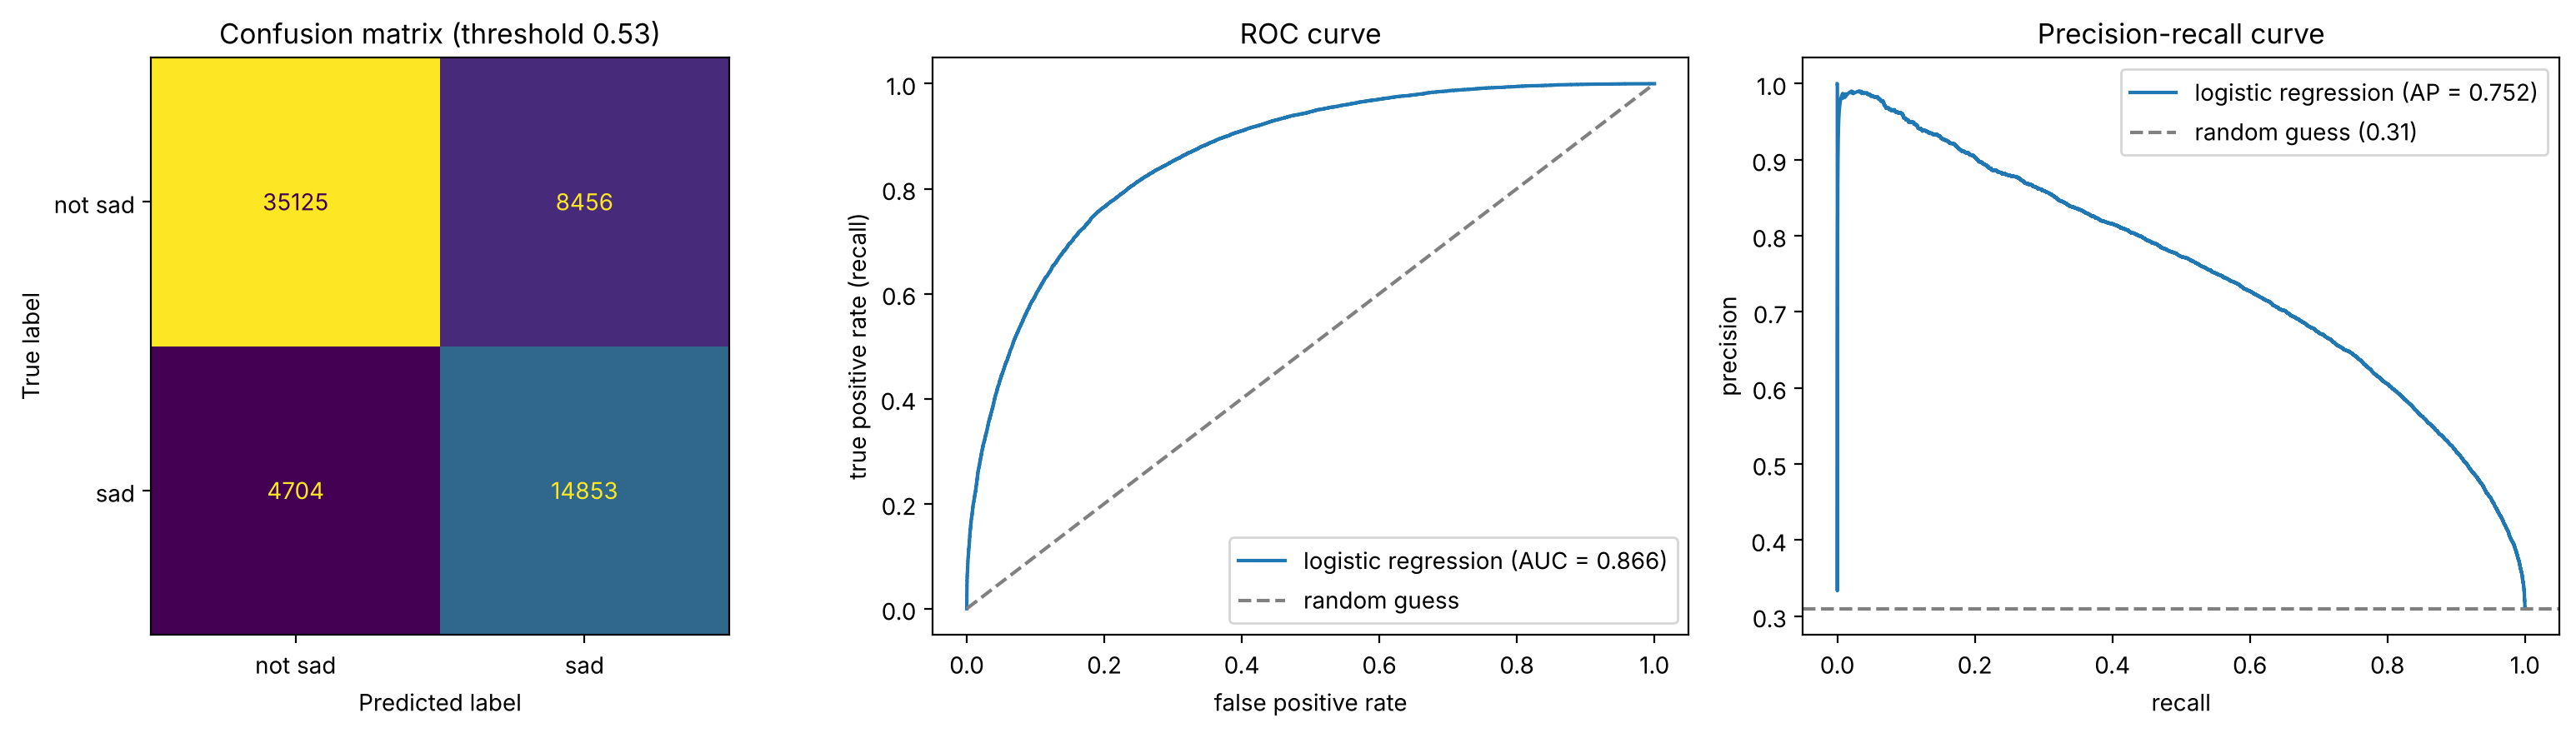

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_sad, (oof_proba >= best_t).astype(int)),
                       display_labels=["not sad", "sad"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {best_t:.2f})")

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
axes[1].plot(fpr, tpr, label=f"logistic regression (AUC = {roc_auc_score(y_sad, oof_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", label="random guess")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()

prec, rec, _ = precision_recall_curve(y_sad, oof_proba)
axes[2].plot(rec, prec, label=f"logistic regression (AP = {average_precision_score(y_sad, oof_proba):.3f})")
axes[2].axhline(y_sad.mean(), color="gray", ls="--", label=f"random guess ({y_sad.mean():.2f})")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curve")
axes[2].legend()

plt.tight_layout()
plt.show()

### 5.4 Classification results (cross-validation)

In [ ]:
pd.DataFrame(clf_results).round(4)

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6903,0.8656,0.7829,"C=100, class_weight=balanced"
2,"Logistic regression (tuned, threshold 0.53)",0.53,0.6930,0.8656,0.7916,"C=100, class_weight=balanced"


## 6. Interpreting the models

### 6.1 Ridge coefficients

The features are scaled, so each coefficient is the change in valence for a one standard deviation increase.

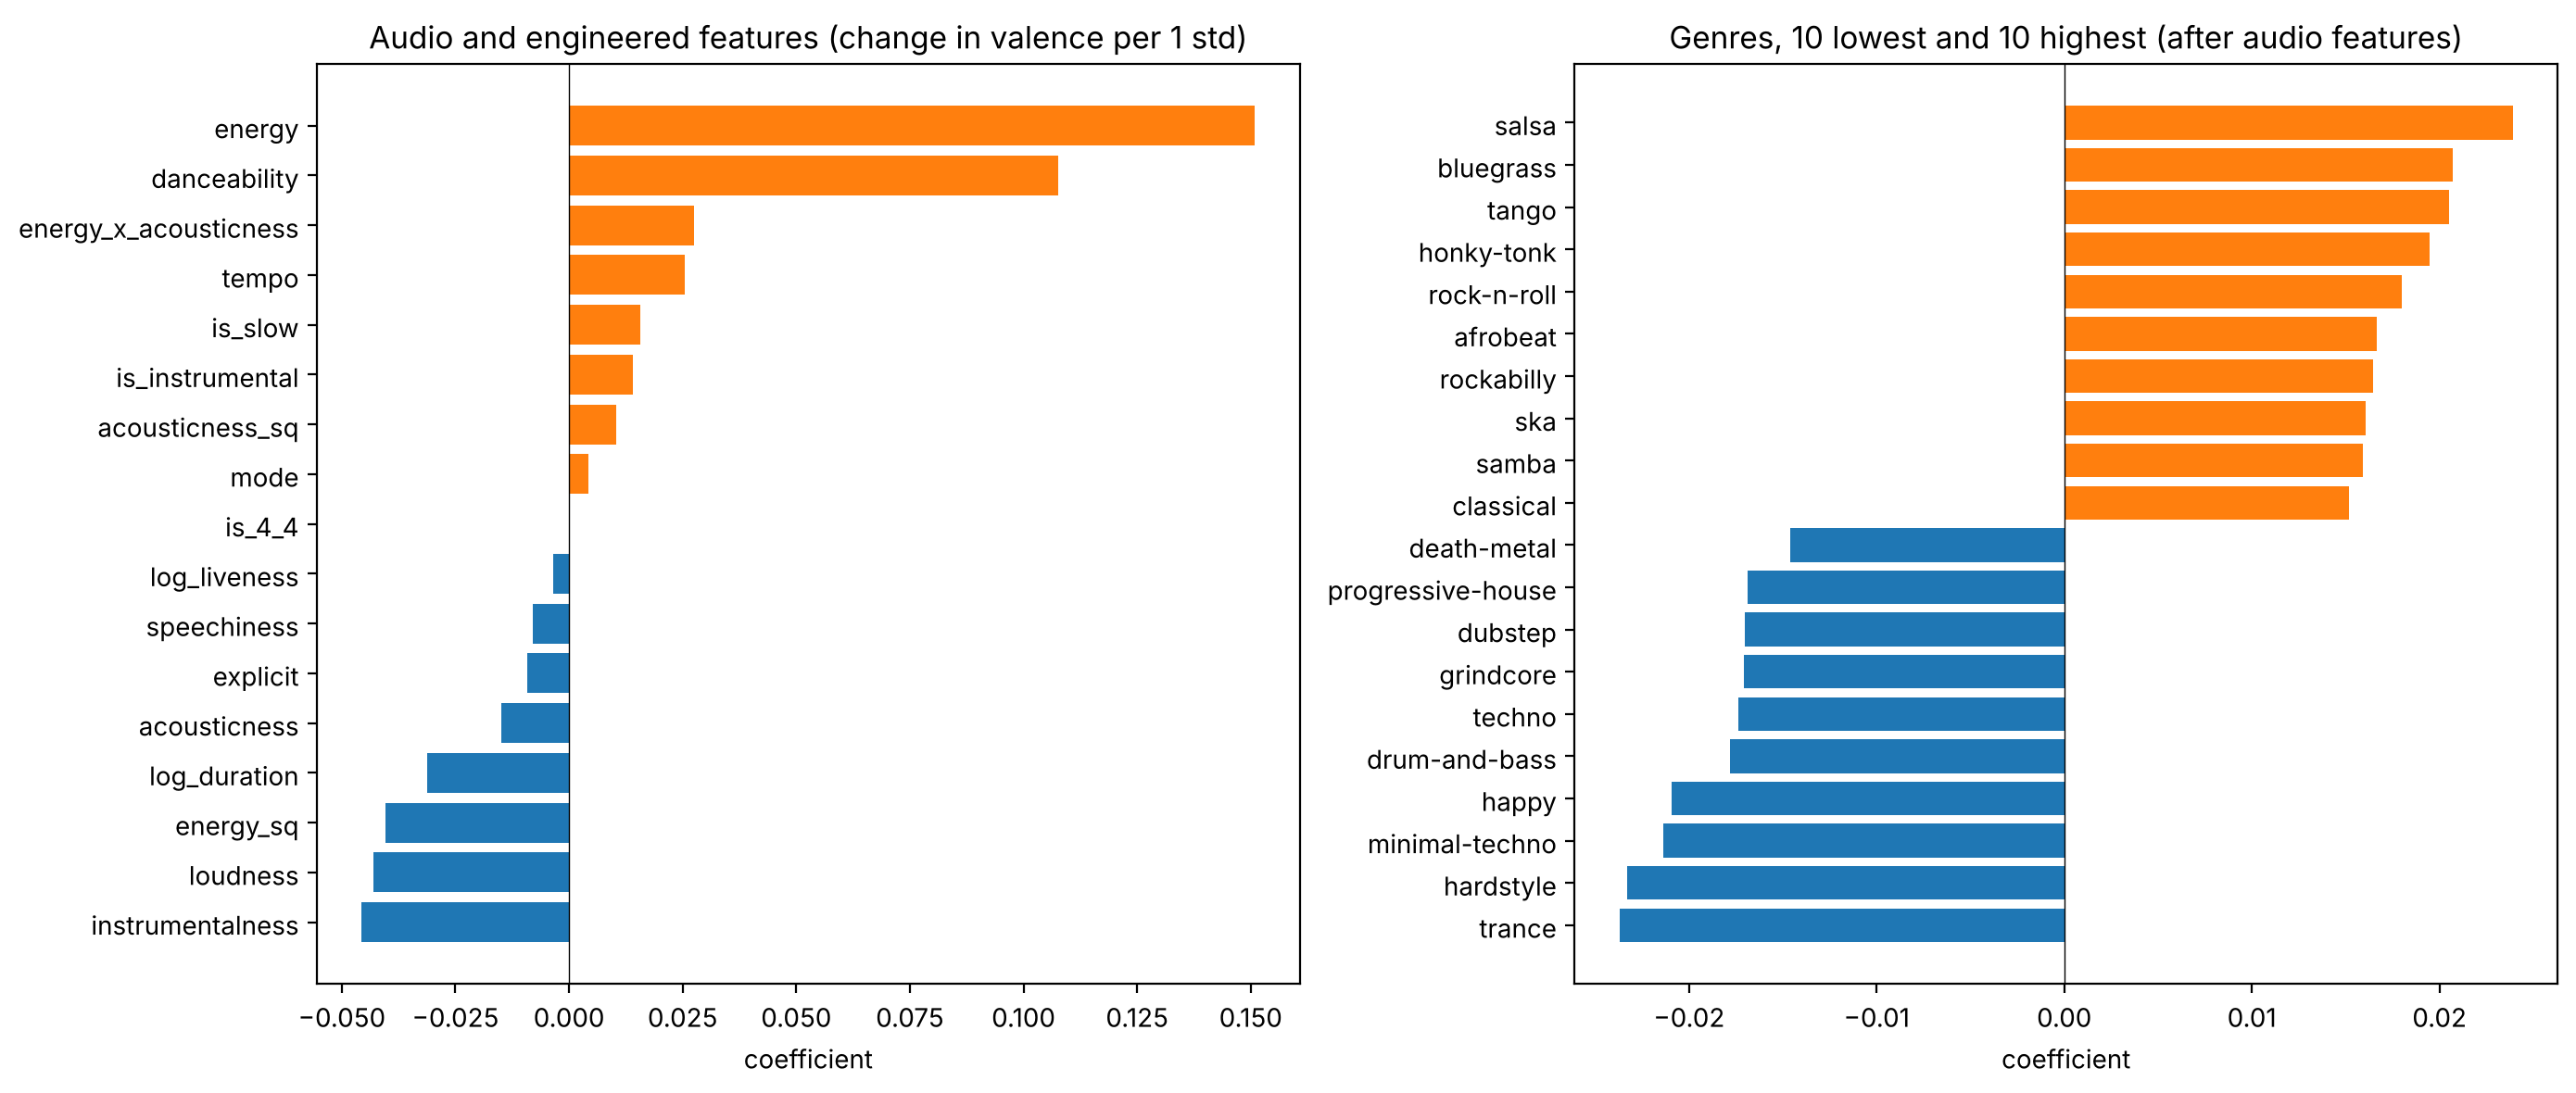

In [ ]:
ridge_best = ridge_grid.best_estimator_.fit(X, y)
coefs = pd.Series(ridge_best.named_steps["model"].coef_, index=X.columns)

small_coefs = coefs[SMALL_COLS].sort_values()
genre_coefs = coefs[GENRE_COLS].rename(lambda n: n.replace("genre_", "")).sort_values()
genre_show = pd.concat([genre_coefs.head(10), genre_coefs.tail(10)])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(small_coefs.index, small_coefs.values, color=np.where(small_coefs.values < 0, "tab:blue", "tab:orange"))
axes[0].axvline(0, color="black", lw=0.5)
axes[0].set_title("Audio and engineered features (change in valence per 1 std)")
axes[0].set_xlabel("coefficient")
axes[1].barh(genre_show.index, genre_show.values, color=np.where(genre_show.values < 0, "tab:blue", "tab:orange"))
axes[1].axvline(0, color="black", lw=0.5)
axes[1].set_title("Genres, 10 lowest and 10 highest (after audio features)")
axes[1].set_xlabel("coefficient")
plt.tight_layout()
plt.show()

Energy and danceability have the largest positive coefficients, and `energy_sq` is negative. Together they give the curve the EDA found, where valence rises with energy and then drops for the most energetic songs. Instrumentalness and loudness are the most negative. Mode is close to 0, and `is_4_4` is 0, so the 4/4 flag adds nothing once the other features are in.

The energy × acousticness term is positive. Among very energetic songs, the more acoustic ones are happier, which matches what feature engineering found.

The genre coefficients are adjustments on top of the audio features. Trance, hardstyle, and techno songs are energetic and danceable, so the audio features predict a high valence, but their actual valence is lower, so they get negative coefficients. The same happens to the "happy" genre. Classical goes the other way.

### 6.2 Permutation importance

We shuffle a feature and see how much the RMSE goes up on a validation set (20% of the training set). Some features are spread over several columns, so we shuffle those columns together. All 112 genre columns are shuffled as one group and all 12 key columns as another, and each feature is shuffled together with the engineered columns built from it (for example energy with `energy_sq`).

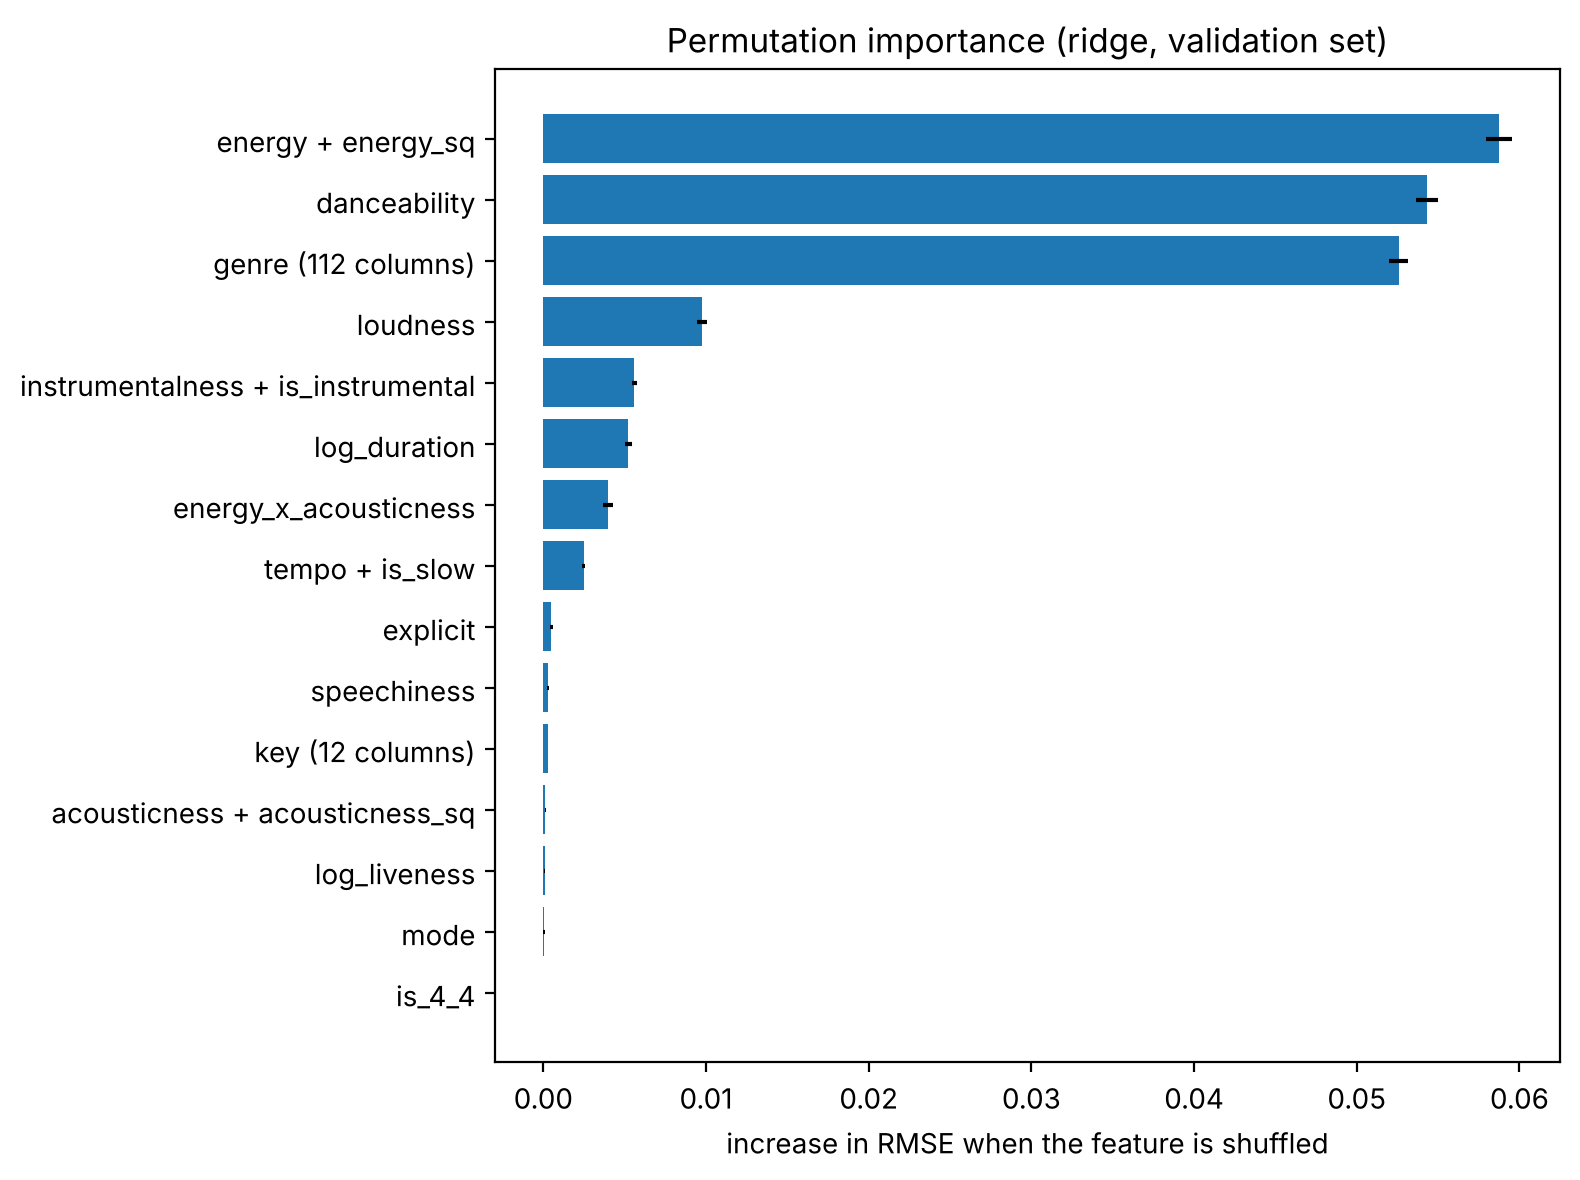

,increase_in_RMSE,std
feature,,
energy + energy_sq,0.0587,0.0008
danceability,0.0543,0.0007
genre (112 columns),0.0526,0.0006
loudness,0.0097,0.0003
instrumentalness + is_instrumental,0.0056,0.0002
log_duration,0.0052,0.0002
energy_x_acousticness,0.0040,0.0003
tempo + is_slow,0.0025,0.0001
explicit,0.0005,0.0001


In [ ]:
FEATURE_GROUPS = {
    "genre (112 columns)": GENRE_COLS,
    "key (12 columns)": KEY_COLS,
    "energy + energy_sq": ["energy", "energy_sq"],
    "acousticness + acousticness_sq": ["acousticness", "acousticness_sq"],
    "energy_x_acousticness": ["energy_x_acousticness"],
    "instrumentalness + is_instrumental": ["instrumentalness", "is_instrumental"],
    "tempo + is_slow": ["tempo", "is_slow"],
}
grouped = {c for cols in FEATURE_GROUPS.values() for c in cols}
FEATURE_GROUPS.update({c: [c] for c in X.columns if c not in grouped})

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
perm_model = ridge_grid.best_estimator_.fit(X_tr, y_tr)
base_rmse = np.sqrt(mean_squared_error(y_val, perm_model.predict(X_val)))

rng = np.random.default_rng(RANDOM_STATE)
rows = []
for name, cols in FEATURE_GROUPS.items():
    increases = []
    for _ in range(5):
        X_shuffled = X_val.copy()
        X_shuffled[cols] = X_val[cols].values[rng.permutation(len(X_val))]   # shuffle the group's rows together
        increases.append(np.sqrt(mean_squared_error(y_val, perm_model.predict(X_shuffled))) - base_rmse)
    rows.append({"feature": name, "increase_in_RMSE": np.mean(increases), "std": np.std(increases)})
perm_imp = pd.DataFrame(rows).set_index("feature").sort_values("increase_in_RMSE")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(perm_imp.index, perm_imp["increase_in_RMSE"], xerr=perm_imp["std"])
ax.set_xlabel("increase in RMSE when the feature is shuffled")
ax.set_title("Permutation importance (ridge, validation set)")
plt.tight_layout()
plt.show()
perm_imp.sort_values("increase_in_RMSE", ascending=False).round(4)

Energy (with its squared term), danceability, and genre matter by far the most. Loudness, instrumentalness, duration, and energy × acousticness add a little.

Acousticness on its own adds almost nothing, because its effect is now carried by the energy × acousticness term. Key, mode, liveness, and the 4/4 flag also add almost nothing.

### 6.3 Error analysis

We look at out-of-fold predictions from the polynomial ridge model. Residual = predicted − true.

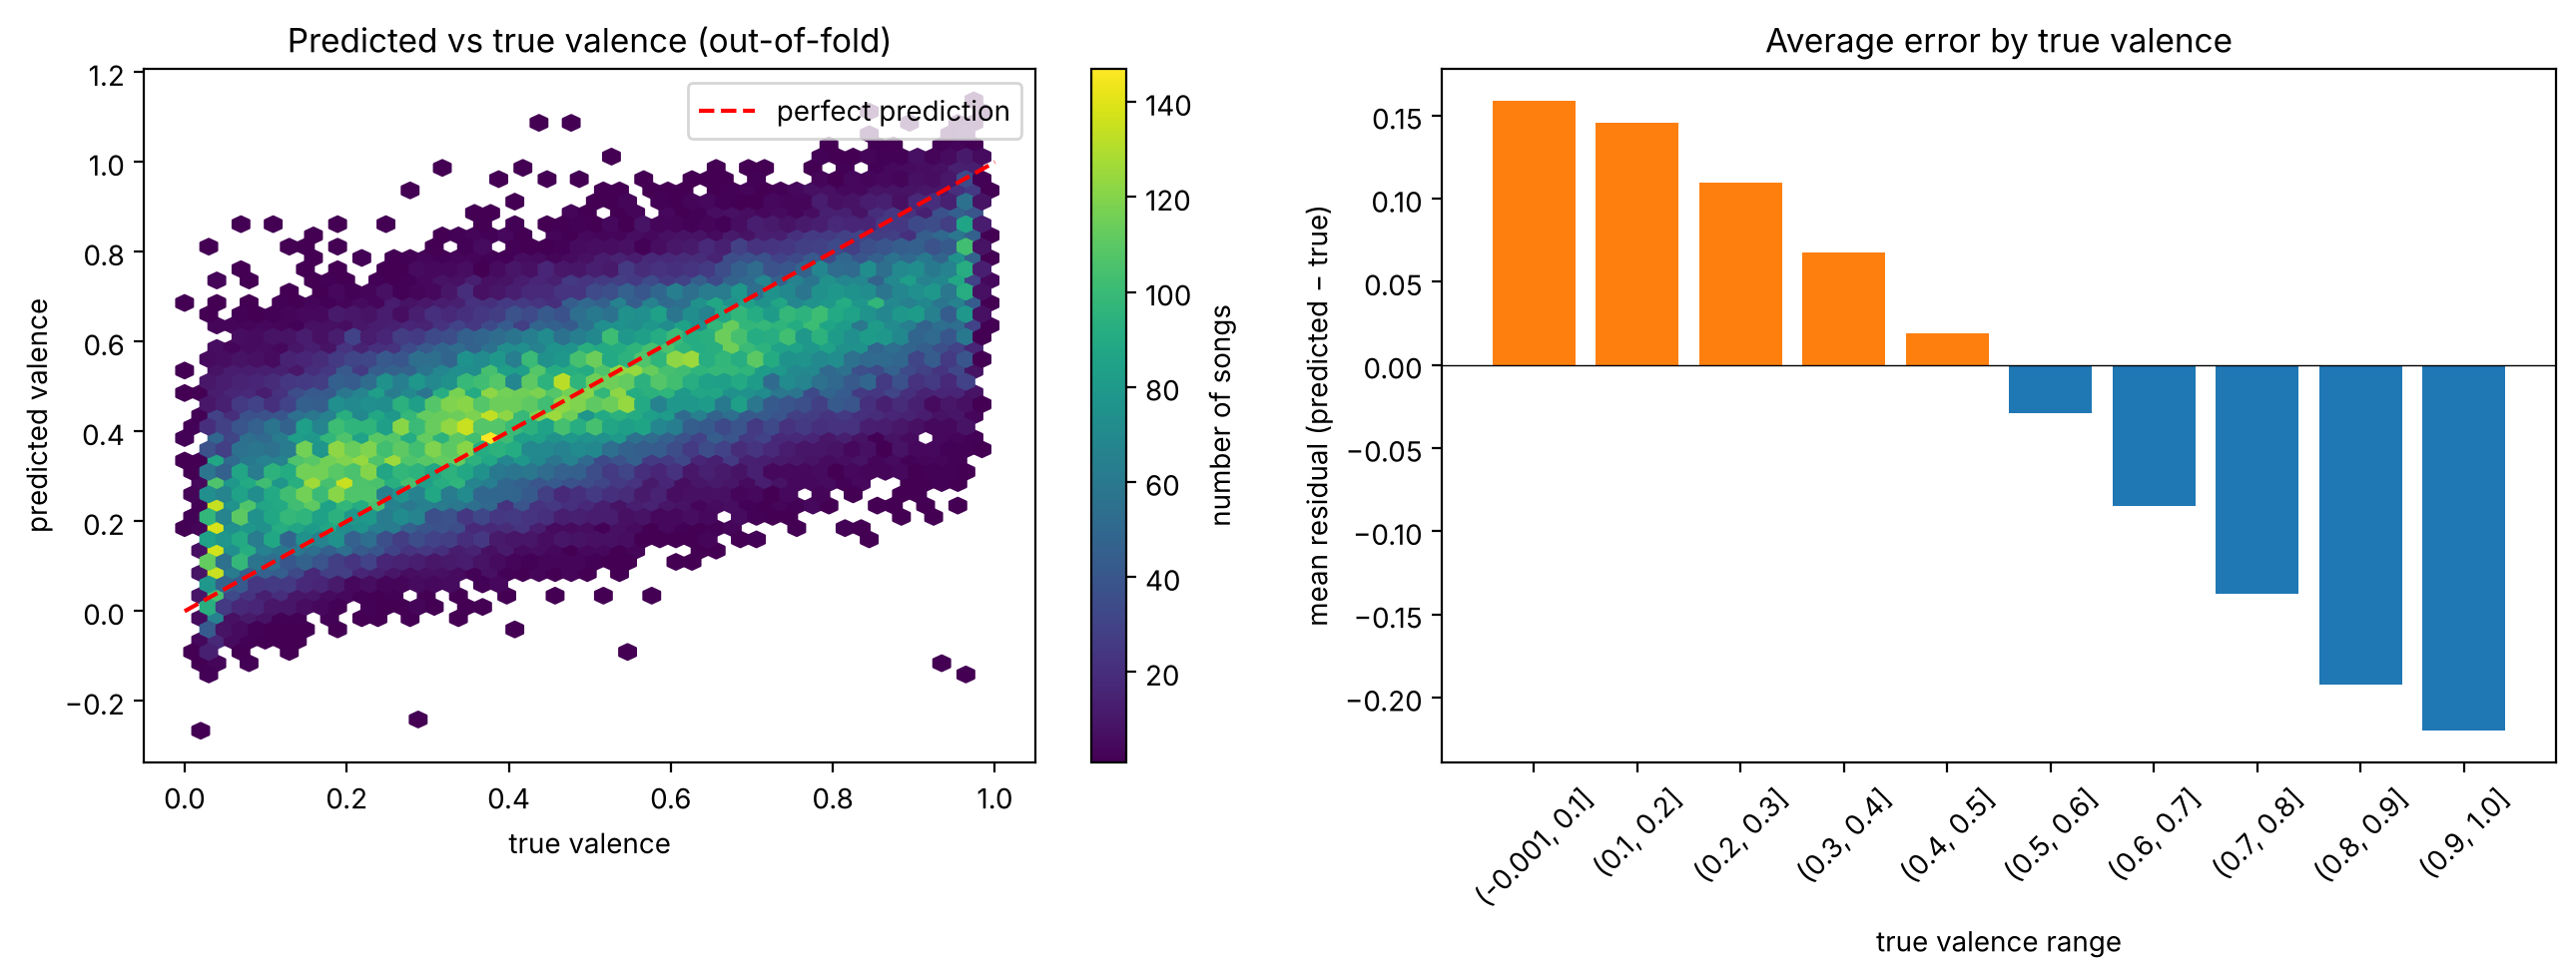

In [ ]:
best_reg = ridge_poly_grid.best_estimator_
oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=-1)
resid = oof_pred - y

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
axes[0].plot([0, 1], [0, 1], color="red", ls="--", label="perfect prediction")
axes[0].set_xlabel("true valence")
axes[0].set_ylabel("predicted valence")
axes[0].set_title("Predicted vs true valence (out-of-fold)")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="number of songs")

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
axes[1].bar([str(b) for b in by_bin.index], by_bin.values,
            color=np.where(by_bin.values > 0, "tab:orange", "tab:blue"))
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_xlabel("true valence range")
axes[1].set_ylabel("mean residual (predicted − true)")
axes[1].set_title("Average error by true valence")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The model pulls its predictions toward the middle. The saddest songs are predicted too happy and the happiest songs too sad.

The EDA found that low valence covers both calm sad songs and intense ones (like metal). We compare the error for these two groups.

In [ ]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4)  ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "all other songs": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()),
           "mean true valence": y[mask].mean(),
           "mean predicted valence": oof_pred[mask].mean(),
           "MAE": resid[mask].abs().mean(),
           "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
error_by_group.round(3)

,songs,mean true valence,mean predicted valence,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.151,0.226,0.108,0.075
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.167,0.331,0.175,0.164
all other songs,43581.0,0.605,0.545,0.138,-0.061


The model does well on calm sad songs (MAE 0.108) but badly on intense low-valence songs (MAE 0.175). It predicts them at 0.33 on average when their true valence is 0.17.
Even with the engineered features, a linear model still learns that more energy means happier, which is wrong for these songs.

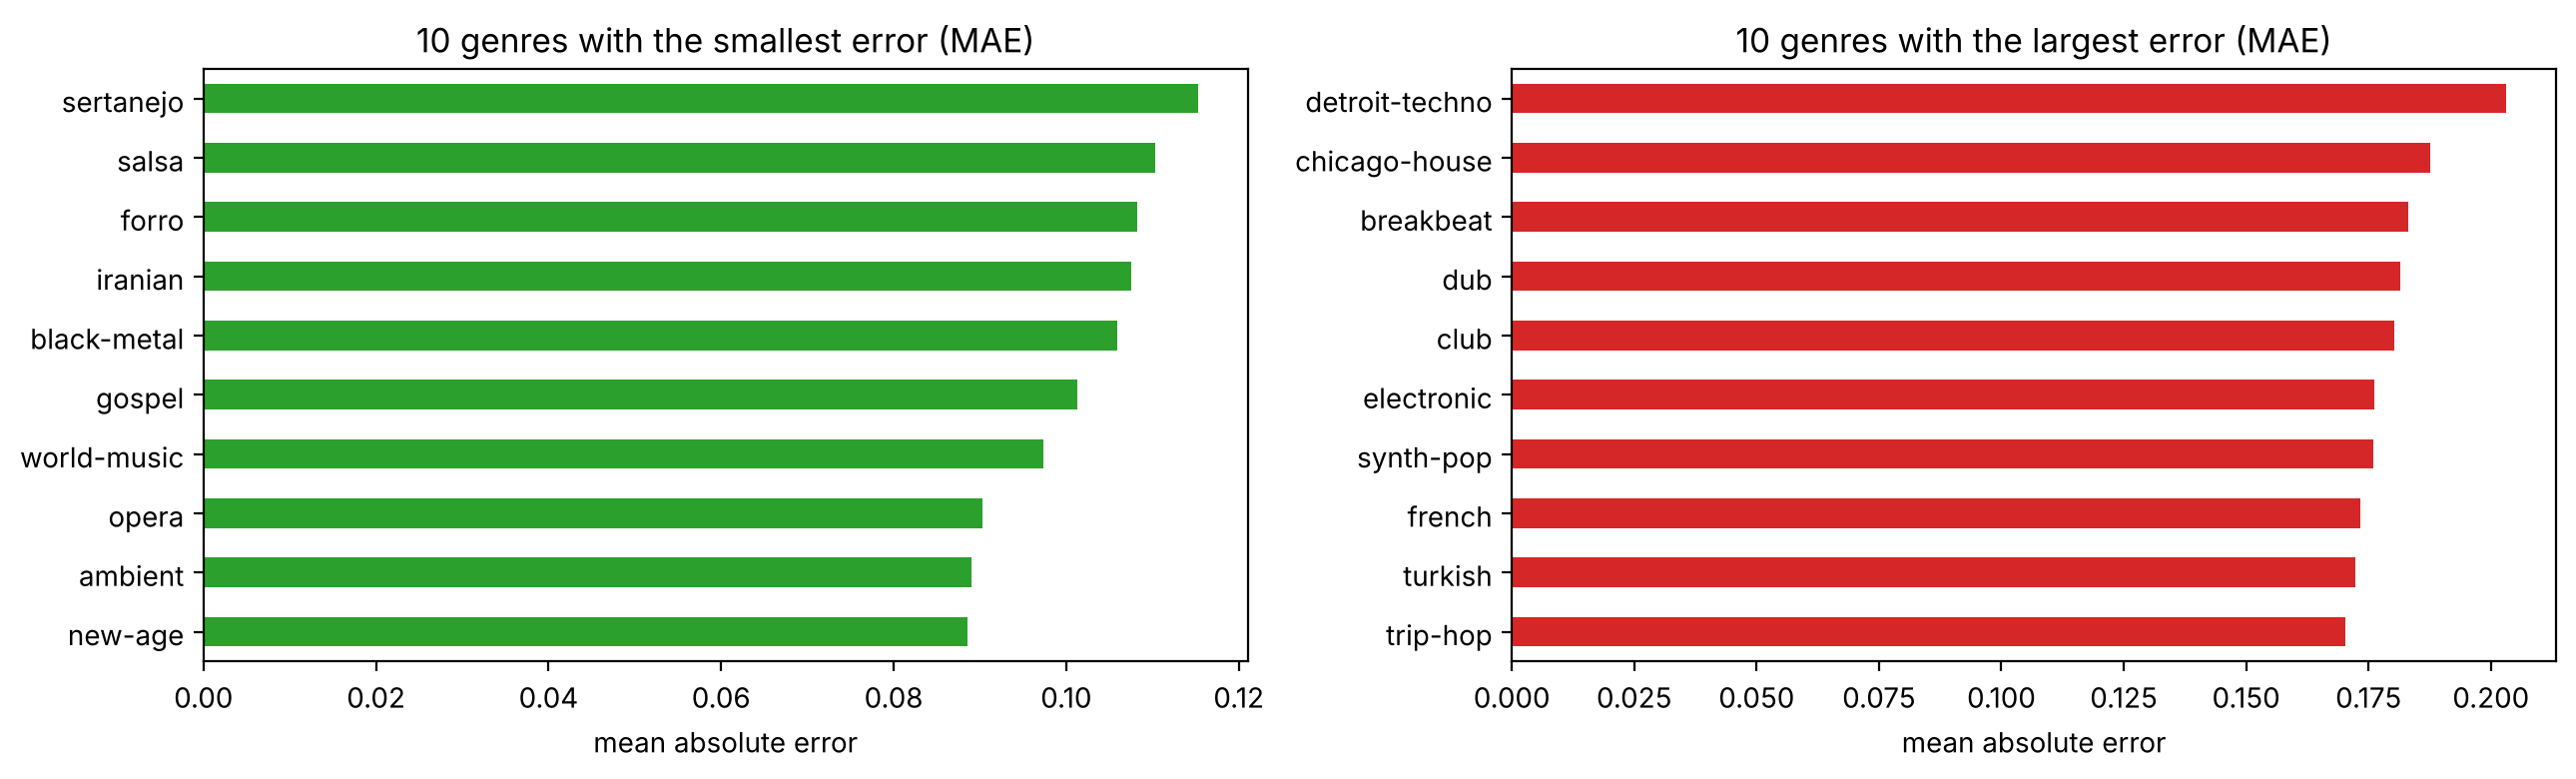

In [ ]:
mae_by_genre = resid.abs().groupby(genre).mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mae_by_genre.head(10).plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("10 genres with the smallest error (MAE)")
mae_by_genre.tail(10).plot.barh(ax=axes[1], color="tab:red")
axes[1].set_title("10 genres with the largest error (MAE)")
for ax in axes:
    ax.set_xlabel("mean absolute error")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

The worst genres are mostly electronic dance genres (detroit-techno, chicago-house, breakbeat, club), which is the same problem as above. The best are genres with consistent valence, like new-age, ambient, opera, and black-metal.

## 7. Test set results

We train each final model on the whole training set and score it once on the test set.

In [ ]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"])
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
assert list(X_test.columns) == list(X.columns)
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

raw_test = pd.read_csv("test_clean.csv")
X_raw_test = raw_test.drop(columns=["valence"])
X_raw_test["explicit"] = X_raw_test["explicit"].astype(int)
assert (raw_test["valence"].values == y_test.values).all()

final_reg = {
    "Baseline: predict mean": (DummyRegressor(strategy="mean"), X, X_test),
    "Linear regression (raw + genre)": (lin_raw, X_raw, X_raw_test),
    "Linear regression (engineered + genre)": (lin_full, X, X_test),
    "Ridge (tuned)": (ridge_grid.best_estimator_, X, X_test),
    "Ridge + degree-2 polynomial (tuned)": (ridge_poly_grid.best_estimator_, X, X_test),
}
test_reg = []
for name, (model, X_fit, X_score) in final_reg.items():
    pred = model.fit(X_fit, y).predict(X_score)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,Linear regression (raw + genre),0.1850,0.1488,0.4905
2,Linear regression (engineered + genre),0.1826,0.1468,0.5035
3,Ridge (tuned),0.1826,0.1468,0.5035
4,Ridge + degree-2 polynomial (tuned),0.1791,0.1432,0.5224


In [ ]:
final_clf = best_logreg.fit(X, y_sad)
test_proba = final_clf.predict_proba(X_test)[:, 1]
test_clf = []
for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    test_clf.append({"threshold": t, "model": f"Logistic regression (threshold {t:.2f})",
                     "test F1": f1_score(y_test_sad, pred),
                     "test ROC-AUC": roc_auc_score(y_test_sad, test_proba),
                     "test accuracy": (pred == y_test_sad).mean()})
base_pred = np.zeros_like(y_test_sad)
test_clf.insert(0, {"model": "Baseline: always 'not sad'", "test F1": f1_score(y_test_sad, base_pred),
                    "test ROC-AUC": 0.5, "test accuracy": (base_pred == y_test_sad).mean()})
pd.DataFrame(test_clf).drop(columns="threshold").round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,Logistic regression (threshold 0.50),0.6824,0.8565,0.7764
2,Logistic regression (threshold 0.53),0.6840,0.8565,0.7850


The test scores are close to the cross-validation scores, so the models aren't overfitting. The engineered features also beat the raw features on the test set (R² 0.504 vs. 0.491).

## 8. Summary

- Feature engineering helped the linear models a little. R² went from 0.506 to 0.517 in cross-validation (0.491 to 0.504 on the test set), and ROC-AUC from 0.863 to 0.866. The most useful new feature is energy × acousticness.
- The best regression model is ridge with polynomial features (test R² 0.52, RMSE 0.18, compared to 0.26 for the baseline).
- Logistic regression gets a test F1 of 0.68 and ROC-AUC of 0.86.
- Ridge and lasso don't help over plain linear regression.
- Balanced class weights and a lower threshold give the same F1.
- Minor key doesn't make songs much sadder. Energy matters the most, but in a curved way.
- The biggest errors are still on high-energy songs with low valence, especially in electronic genres.

### Results for the shared sheet

In [ ]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left")
clf_table = pd.DataFrame(clf_results)
test_by_t = {r["threshold"]: r for r in test_clf if "threshold" in r}
for col in ["test F1", "test ROC-AUC", "test accuracy"]:
    clf_table[col] = [test_by_t[r["threshold"]][col] if r["model"].startswith("Logistic")
                      else (test_clf[0][col] if r["model"].startswith("Baseline") else np.nan)
                      for _, r in clf_table.iterrows()]
reg_table.to_csv("results_linear_regression.csv", index=False)
clf_table.to_csv("results_linear_classification.csv", index=False)
print("Saved results_linear_regression.csv and results_linear_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_linear_regression.csv and results_linear_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,"Linear regression (raw, no genre)",0.2070,0.0016,0.1689,0.3762,before feature engineering,NaN,NaN,NaN
2,Linear regression (raw + genre),0.1842,0.0009,0.1480,0.5060,before feature engineering,0.1850,0.1488,0.4905
3,"Linear regression (engineered, no genre)",0.2035,0.0018,0.1660,0.3971,engineered features,NaN,NaN,NaN
4,Linear regression (engineered + genre),0.1822,0.0009,0.1464,0.5170,engineered features,0.1826,0.1468,0.5035
5,Ridge (tuned),0.1822,0.0009,0.1464,0.5170,alpha=3.16,0.1826,0.1468,0.5035
6,Lasso (tuned),0.1822,0.0009,0.1465,0.5170,alpha=3.16e-05,NaN,NaN,NaN
7,Ridge + degree-2 polynomial (tuned),0.1787,0.0010,0.1429,0.5352,alpha=31.6,0.1791,0.1432,0.5224


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6903,0.8656,0.7829,"C=100, class_weight=balanced",0.6824,0.8565,0.7764
2,"Logistic regression (tuned, threshold 0.53)",0.53,0.6930,0.8656,0.7916,"C=100, class_weight=balanced",0.6840,0.8565,0.7850


---

# Part 5: Tree Models

*By Xingyao Chen.*

Decision trees, random forests, and gradient boosting predict continuous valence and the sad label (valence < 0.3).
The inputs are the 141 numeric features in train_features.csv; test_features.csv is used for final scoring.

## 1. Setup

Import the libraries and set the random seed and number of parallel CPU fits.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier)
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3
N_JOBS = 2

Load the training features and targets. The text column track_genre is excluded because genre is already represented by the genre_* columns.

In [ ]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y = train_df["valence"]
y_sad = train_df["sad"]

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Cross-validation

Create five shuffled folds for regression and five stratified folds for classification. Stratification preserves the class proportions in each fold.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Evaluation functions

Calculate regression RMSE, MAE, and R2 using five-fold CV. Classification uses out-of-fold probabilities to calculate F1, ROC-AUC, and accuracy.

In [ ]:
reg_results = []
clf_results = []

def eval_regressor(name, model, notes=""):
    scores = cross_validate(model, X, y, cv=kf, n_jobs=N_JOBS, error_score="raise",
                            scoring={"rmse": "neg_root_mean_squared_error",
                                     "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -scores["test_rmse"].mean(), "RMSE_std": scores["test_rmse"].std(),
           "MAE": -scores["test_mae"].mean(), "R2": scores["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), "
          f"MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def record_classifier(name, proba, threshold=0.5, notes=""):
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_sad, pred), "ROC_AUC": roc_auc_score(y_sad, proba),
           "accuracy": (pred == y_sad).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, "
          f"accuracy {row['accuracy']:.4f}")
    return row

def eval_classifier(name, model, notes=""):
    proba = cross_val_predict(model, X, y_sad, cv=skf,
                             method="predict_proba", n_jobs=N_JOBS)[:, 1]
    record_classifier(name, proba, notes=notes)
    return proba

### Tuning tables and plots

Display candidate scores and plot one parameter at a time, holding the other parameters at their selected values. Each plot is a separate figure.

In [ ]:
def show_search(search):
    print("Best parameters:", search.best_params_)
    results = pd.DataFrame(search.cv_results_)
    parameters = [c for c in results if c.startswith("param_")]
    table = results[parameters + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]].copy()
    if "param_class_weight" in table:
        table["param_class_weight"] = table["param_class_weight"].fillna("None (equal weights)")
    if "param_max_depth" in table:
        table["param_max_depth"] = table["param_max_depth"].apply(lambda x: "No limit" if pd.isna(x) else int(x))
    if search.scoring == "neg_root_mean_squared_error":
        table[["mean_train_score", "mean_test_score"]] *= -1
    display(table.rename(columns={"mean_train_score": "training_score",
                                  "mean_test_score": "validation_score",
                                  "std_test_score": "validation_std",
                                  "rank_test_score": "rank"}).sort_values("rank"))

def plot_search(search, parameters, title):
    for parameter in parameters:
        results = pd.DataFrame(search.cv_results_)
        for other, value in search.best_params_.items():
            if other != parameter:
                results = results[[p[other] == value for p in results["params"]]]
        sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
        positions = np.arange(len(results))
        labels = [str(p[parameter]) for p in results["params"]]
        plt.figure(figsize=(8, 5))
        plt.plot(positions, sign * results["mean_train_score"], "o-", label="training")
        plt.errorbar(positions, sign * results["mean_test_score"],
                     yerr=results["std_test_score"], fmt="o-", capsize=3, label="validation")
        plt.xticks(positions, labels)
        plt.xlabel(parameter)
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {parameter}")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 3. Initial models

Evaluate the mean-valence and always-not-sad baselines, then evaluate each tree model with its default parameters.

In [ ]:
initial_reg = {
    "Decision tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random forest": RandomForestRegressor(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
initial_clf = {
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"))
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000
Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


In [ ]:
for name, model in initial_reg.items():
    eval_regressor(f"{name} (initial)", model)
pd.DataFrame(reg_results).round(4)

Decision tree (initial): RMSE 0.2574 (+/- 0.0018), MAE 0.1982, R2 0.0358
Random forest (initial): RMSE 0.1801 (+/- 0.0010), MAE 0.1433, R2 0.5278
Gradient boosting (initial): RMSE 0.1870 (+/- 0.0015), MAE 0.1521, R2 0.4910


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,


In [ ]:
for name, model in initial_clf.items():
    eval_classifier(f"{name} (initial)", model)
pd.DataFrame(clf_results).round(4)

Decision tree (initial): F1 0.5732, ROC-AUC 0.6908, accuracy 0.7355
Random forest (initial): F1 0.6500, ROC-AUC 0.8663, accuracy 0.8090
Gradient boosting (initial): F1 0.6207, ROC-AUC 0.8565, accuracy 0.7998


,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.5,0.0000,0.5000,0.6902,
1,Decision tree (initial),0.5,0.5732,0.6908,0.7355,
2,Random forest (initial),0.5,0.6500,0.8663,0.8090,
3,Gradient boosting (initial),0.5,0.6207,0.8565,0.7998,


## 4. Regression tuning

Select parameters by the lowest mean CV RMSE.

### 4.1 Decision tree

Compare maximum depth and minimum samples per leaf.

Best parameters: {'max_depth': 12, 'min_samples_leaf': 50}


,param_max_depth,param_min_samples_leaf,training_score,validation_score,validation_std,rank
11,12,50,1.870344e-01,0.200491,0.001191,1
14,16,50,1.836703e-01,0.200805,0.001212,2
20,No limit,50,1.834093e-01,0.200827,0.001160,3
17,24,50,1.834093e-01,0.200827,0.001160,3
10,12,10,1.772562e-01,0.203061,0.001347,5
8,8,50,1.982739e-01,0.203997,0.000989,6
7,8,10,1.972116e-01,0.204201,0.000936,7
6,8,1,1.968662e-01,0.204564,0.000986,8
9,12,1,1.723652e-01,0.207024,0.001127,9
13,16,10,1.593373e-01,0.209422,0.001582,10


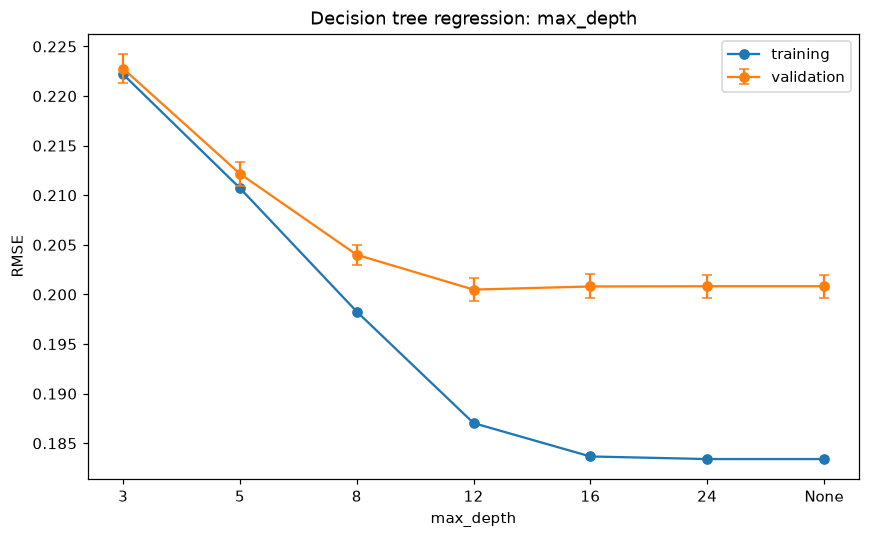

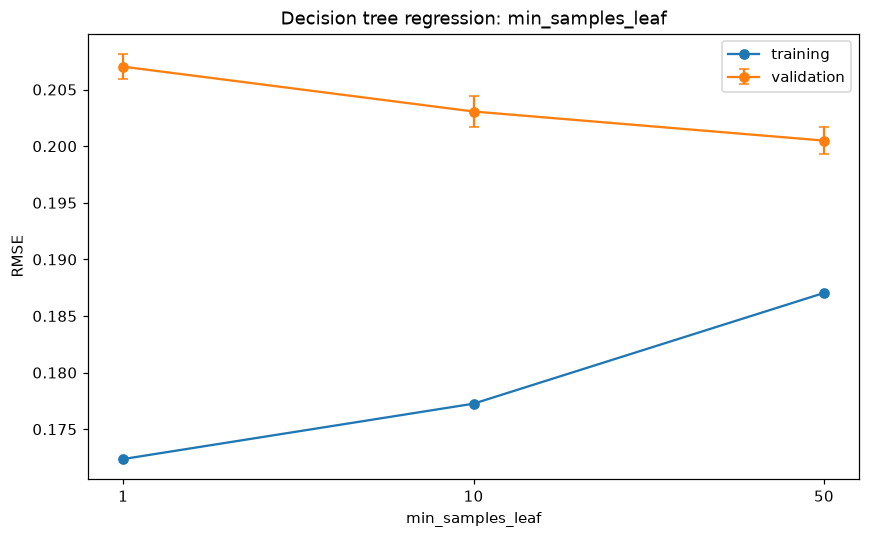

In [ ]:
tree_params = {
    "max_depth": [3, 5, 8, 12, 16, 24, None],
    "min_samples_leaf": [1, 10, 50],
}
tree_reg_grid = GridSearchCV(initial_reg["Decision tree"], tree_params,
                             cv=kf, scoring="neg_root_mean_squared_error",
                             return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
tree_reg_grid.fit(X, y)
show_search(tree_reg_grid)
plot_search(tree_reg_grid, list(tree_params), "Decision tree regression")

### 4.2 Random forest

First tune tree depth, leaf size, and feature sampling with 100 trees. Then compare the number of trees using the selected structure.

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,param_max_depth,param_max_features,param_min_samples_leaf,training_score,validation_score,validation_std,rank
12,No limit,sqrt,1,0.067169,0.178755,0.000985,1
15,No limit,1.0,1,0.067433,0.180141,0.000992,2
9,16,1.0,1,0.125874,0.181878,0.001089,3
16,No limit,1.0,5,0.114839,0.181989,0.001191,4
10,16,1.0,5,0.137767,0.182887,0.001153,5
13,No limit,sqrt,5,0.157279,0.184149,0.001152,6
17,No limit,1.0,20,0.161898,0.185717,0.001228,7
11,16,1.0,20,0.163932,0.185942,0.001244,8
6,16,sqrt,1,0.174423,0.192032,0.001211,9
14,No limit,sqrt,20,0.184151,0.192188,0.001297,10


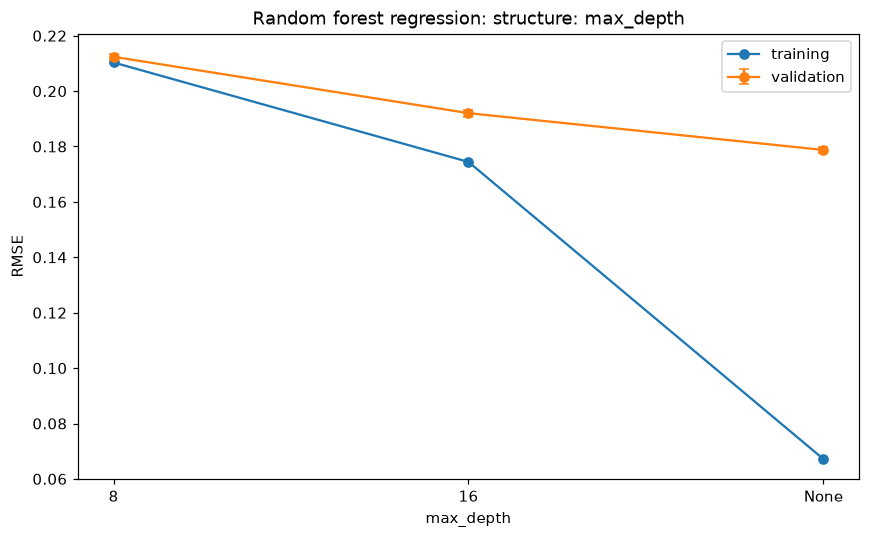

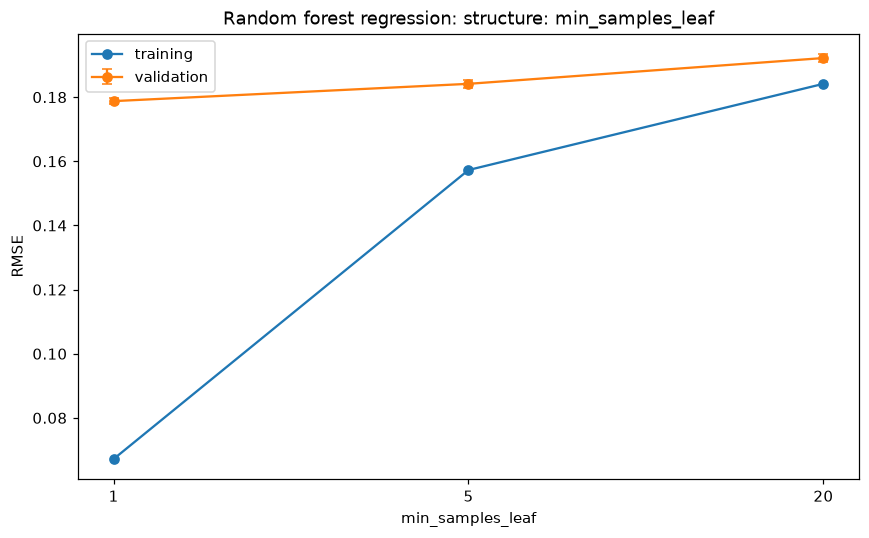

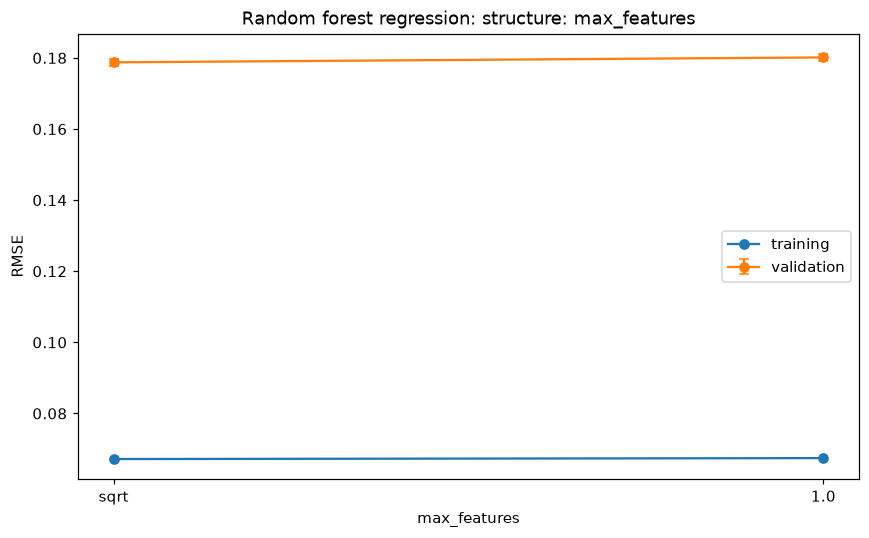

In [ ]:
forest_params = {
    "max_depth": [8, 16, None],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 1.0],
}
forest_reg_structure = GridSearchCV(initial_reg["Random forest"], forest_params,
                                    cv=kf, scoring="neg_root_mean_squared_error",
                                    return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
forest_reg_structure.fit(X, y)
show_search(forest_reg_structure)
plot_search(forest_reg_structure, list(forest_params), "Random forest regression: structure")

Best parameters: {'n_estimators': 400}


,param_n_estimators,training_score,validation_score,validation_std,rank
3,400,0.065830,0.177995,0.000935,1
2,200,0.066272,0.178104,0.000865,2
1,100,0.067169,0.178755,0.000985,3
0,50,0.068807,0.179913,0.000990,4


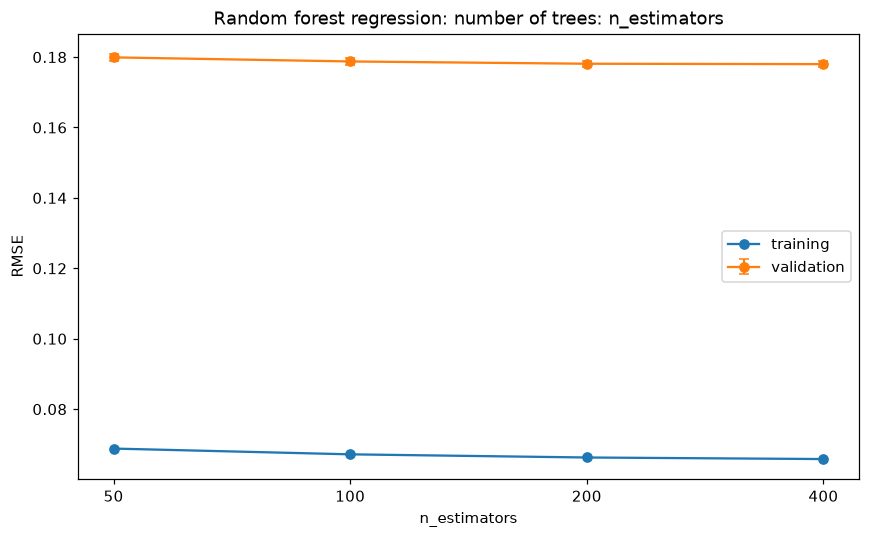

In [ ]:
forest_size_params = {"n_estimators": [50, 100, 200, 400]}
forest_reg_grid = GridSearchCV(clone(forest_reg_structure.best_estimator_), forest_size_params,
                               cv=kf, scoring="neg_root_mean_squared_error",
                               return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
forest_reg_grid.fit(X, y)
show_search(forest_reg_grid)
plot_search(forest_reg_grid, list(forest_size_params), "Random forest regression: number of trees")

### 4.3 Gradient boosting

Compare learning rate, tree depth, and the number of boosting stages. Plot training and validation scores separately.

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}


,param_learning_rate,param_max_depth,param_n_estimators,training_score,validation_score,validation_std,rank
17,0.10,5,400,0.150254,0.169473,0.001039,1
23,0.30,3,400,0.156465,0.170142,0.000809,2
25,0.30,5,150,0.148570,0.171477,0.001038,3
26,0.30,5,400,0.125368,0.172356,0.001061,4
20,0.30,2,400,0.167413,0.172771,0.000948,5
22,0.30,3,150,0.167434,0.173528,0.000784,6
14,0.10,3,400,0.168592,0.173969,0.001159,7
16,0.10,5,150,0.165410,0.174654,0.000882,8
24,0.30,5,50,0.166126,0.176070,0.001303,9
8,0.03,5,400,0.168971,0.176493,0.001044,10


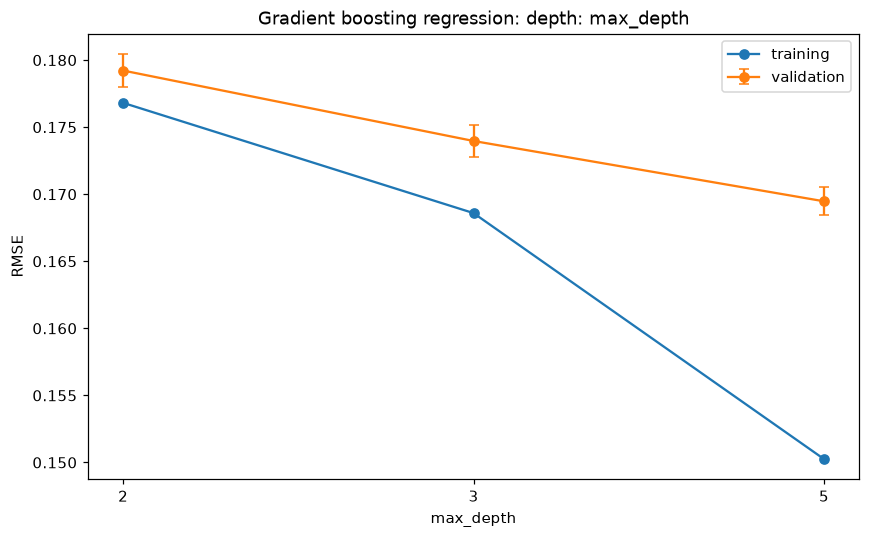

In [ ]:
boost_params = {
    "learning_rate": [0.03, 0.1, 0.3],
    "max_depth": [2, 3, 5],
    "n_estimators": [50, 150, 400],
}
boost_reg_grid = GridSearchCV(initial_reg["Gradient boosting"], boost_params,
                              cv=kf, scoring="neg_root_mean_squared_error",
                              return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=2)
boost_reg_grid.fit(X, y)
show_search(boost_reg_grid)
plot_search(boost_reg_grid, ["max_depth"], "Gradient boosting regression: depth")

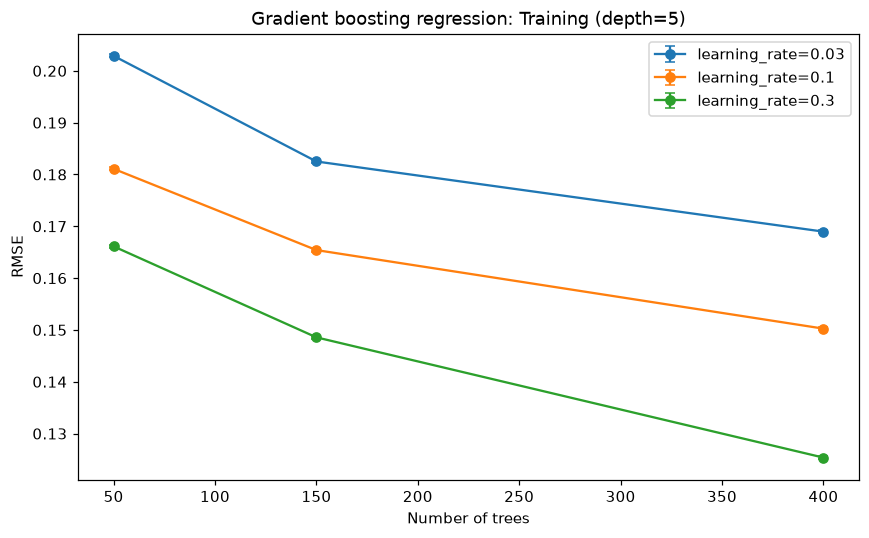

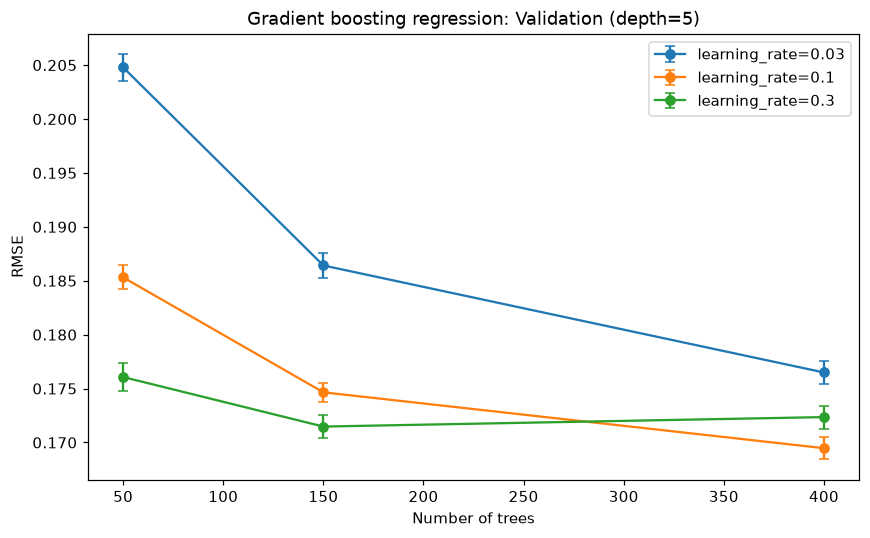

In [ ]:
def plot_boosting(search, title):
    results = pd.DataFrame(search.cv_results_)
    depth = search.best_params_["max_depth"]
    sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
    for split, label in [("train", "Training"), ("test", "Validation")]:
        plt.figure(figsize=(8, 5))
        for rate in search.param_grid["learning_rate"]:
            rows = results[[p["max_depth"] == depth and p["learning_rate"] == rate
                            for p in results["params"]]].sort_values("param_n_estimators")
            plt.errorbar(rows["param_n_estimators"].astype(int), sign * rows[f"mean_{split}_score"],
                         yerr=rows[f"std_{split}_score"], fmt="o-", capsize=3,
                         label=f"learning_rate={rate}")
        plt.xlabel("Number of trees")
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {label} (depth={depth})")
        plt.legend()
        plt.tight_layout()
        plt.show()

plot_boosting(boost_reg_grid, "Gradient boosting regression")

### 4.4 Tuned regression scores

Calculate RMSE, MAE, and R2 for each selected regressor and record its parameters.

In [ ]:
tuned_reg = {
    "Decision tree (tuned)": tree_reg_grid.best_estimator_,
    "Random forest (tuned)": forest_reg_grid.best_estimator_,
    "Gradient boosting (tuned)": boost_reg_grid.best_estimator_,
}
reg_notes = {
    "Decision tree (tuned)": str(tree_reg_grid.best_params_),
    "Random forest (tuned)": str({**forest_reg_structure.best_params_, **forest_reg_grid.best_params_}),
    "Gradient boosting (tuned)": str(boost_reg_grid.best_params_),
}
for name, model in tuned_reg.items():
    eval_regressor(name, model, notes=reg_notes[name])
pd.DataFrame(reg_results).round(4)

Decision tree (tuned): RMSE 0.2005 (+/- 0.0012), MAE 0.1597, R2 0.4150
Random forest (tuned): RMSE 0.1780 (+/- 0.0009), MAE 0.1440, R2 0.5389
Gradient boosting (tuned): RMSE 0.1695 (+/- 0.0010), MAE 0.1341, R2 0.5820


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,
4,Decision tree (tuned),0.2005,0.0012,0.1597,0.4150,"{'max_depth': 12, 'min_samples_l..."
5,Random forest (tuned),0.1780,0.0009,0.1440,0.5389,"{'max_depth': None, 'max_feature..."
6,Gradient boosting (tuned),0.1695,0.0010,0.1341,0.5820,"{'learning_rate': 0.1, 'max_dept..."


## 5. Classification tuning

Select classifier parameters by the highest mean CV ROC-AUC.

### 5.1 Decision tree

Compare depth, leaf size, and class weighting; None gives equal class weights, while balanced increases the weight of the less frequent class.

Best parameters: {'class_weight': None, 'max_depth': 12, 'min_samples_leaf': 50}


,param_class_weight,param_max_depth,param_min_samples_leaf,training_score,validation_score,validation_std,rank
11,None (equal weights),12,50,0.863923,0.819276,0.003999,1
32,balanced,12,50,0.866459,0.818323,0.003056,2
14,None (equal weights),16,50,0.872527,0.817745,0.003055,3
20,None (equal weights),No limit,50,0.873459,0.817546,0.003333,4
17,None (equal weights),24,50,0.873459,0.817546,0.003333,4
29,balanced,8,50,0.838518,0.817388,0.002696,6
28,balanced,8,10,0.841515,0.817006,0.003861,7
35,balanced,16,50,0.873761,0.816325,0.003899,8
41,balanced,No limit,50,0.874955,0.816290,0.003801,9
38,balanced,24,50,0.874955,0.816290,0.003801,9


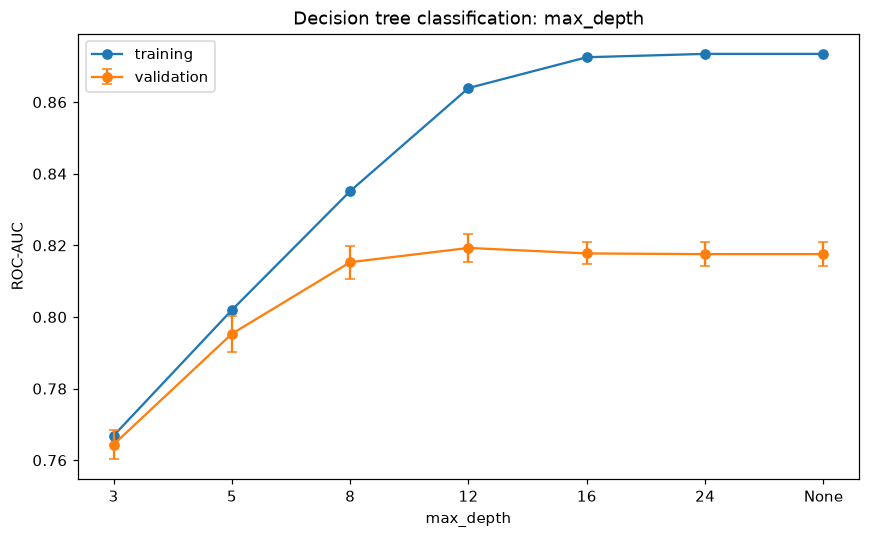

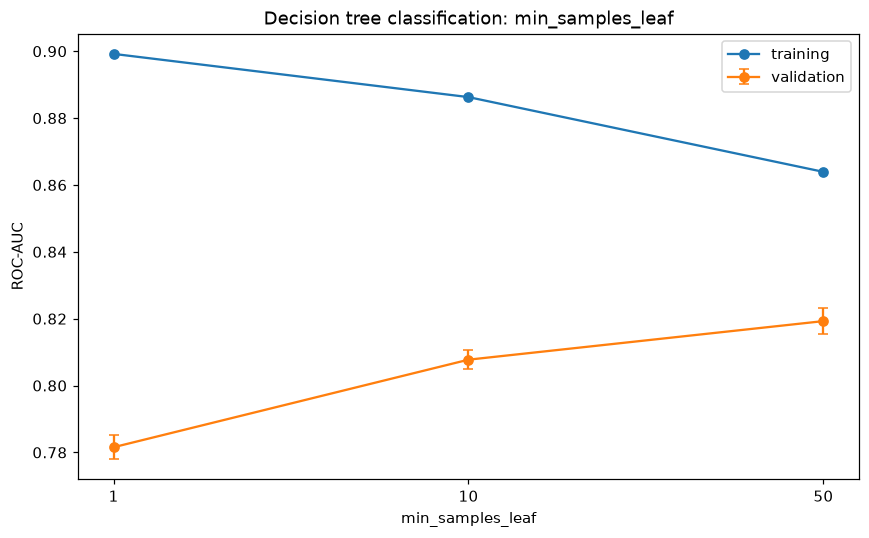

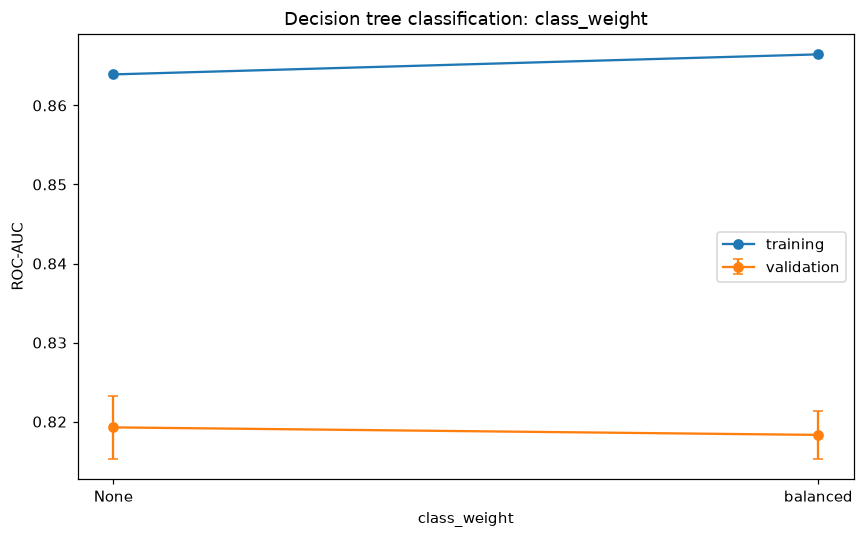

In [ ]:
tree_clf_params = {**tree_params, "class_weight": [None, "balanced"]}
tree_clf_grid = GridSearchCV(initial_clf["Decision tree"], tree_clf_params,
                             cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                             n_jobs=N_JOBS, verbose=1)
tree_clf_grid.fit(X, y_sad)
show_search(tree_clf_grid)
plot_search(tree_clf_grid, list(tree_clf_params), "Decision tree classification")

### 5.2 Random forest

Tune forest structure with 100 trees, then compare tree count and class weighting.

Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}


,param_max_depth,param_max_features,param_min_samples_leaf,training_score,validation_score,validation_std,rank
12,No limit,sqrt,1,1.000000,0.866338,0.002921,1
15,No limit,1.0,1,1.000000,0.863370,0.003266,2
13,No limit,sqrt,5,0.949261,0.862711,0.003326,3
9,16,1.0,1,0.981181,0.861296,0.003085,4
16,No limit,1.0,5,0.989009,0.860113,0.002831,5
10,16,1.0,5,0.964877,0.859164,0.002720,6
17,No limit,1.0,20,0.926300,0.855092,0.003176,7
11,16,1.0,20,0.920061,0.854590,0.003206,8
6,16,sqrt,1,0.921489,0.852953,0.003810,9
14,No limit,sqrt,20,0.884808,0.851886,0.004256,10


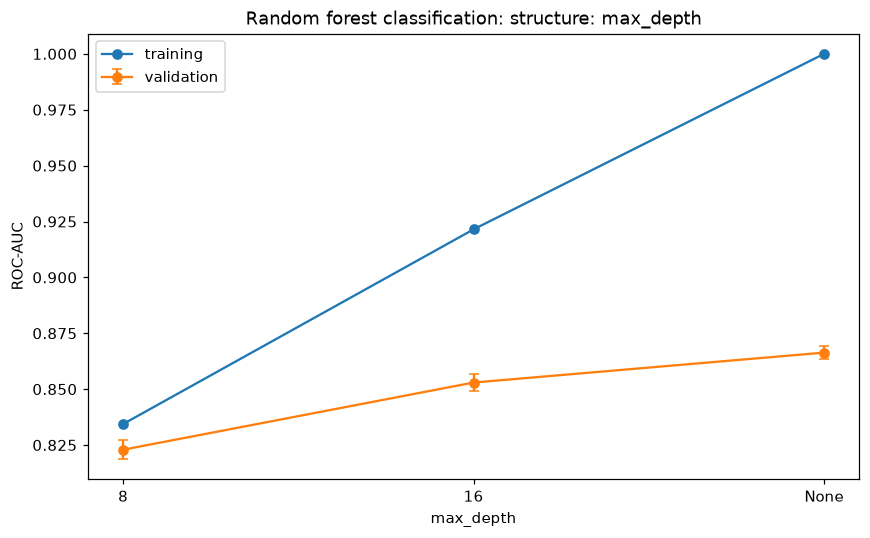

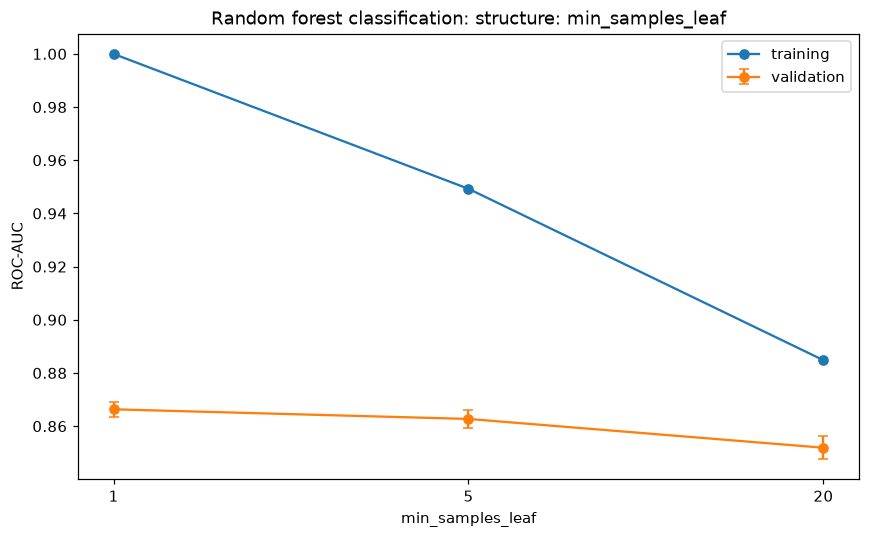

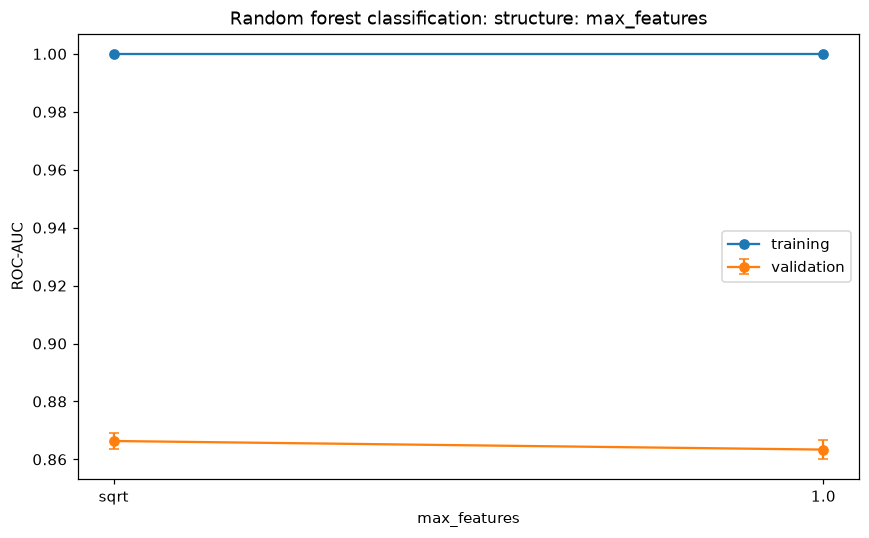

In [ ]:
forest_clf_structure = GridSearchCV(initial_clf["Random forest"], forest_params,
                                    cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                                    n_jobs=N_JOBS, verbose=1)
forest_clf_structure.fit(X, y_sad)
show_search(forest_clf_structure)
plot_search(forest_clf_structure, list(forest_params), "Random forest classification: structure")

Best parameters: {'class_weight': 'balanced', 'n_estimators': 400}


,param_class_weight,param_n_estimators,training_score,validation_score,validation_std,rank
7,balanced,400,1.0,0.870670,0.003510,1
6,balanced,200,1.0,0.870022,0.003762,2
3,None (equal weights),400,1.0,0.869976,0.003011,3
2,None (equal weights),200,1.0,0.868668,0.002983,4
5,balanced,100,1.0,0.867976,0.003695,5
1,None (equal weights),100,1.0,0.866338,0.002921,6
4,balanced,50,1.0,0.864083,0.003579,7
0,None (equal weights),50,1.0,0.861215,0.002744,8


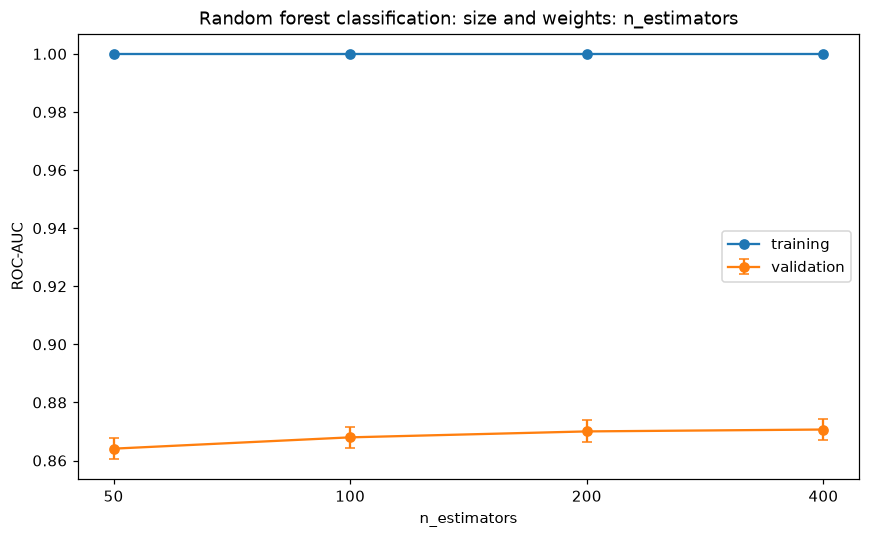

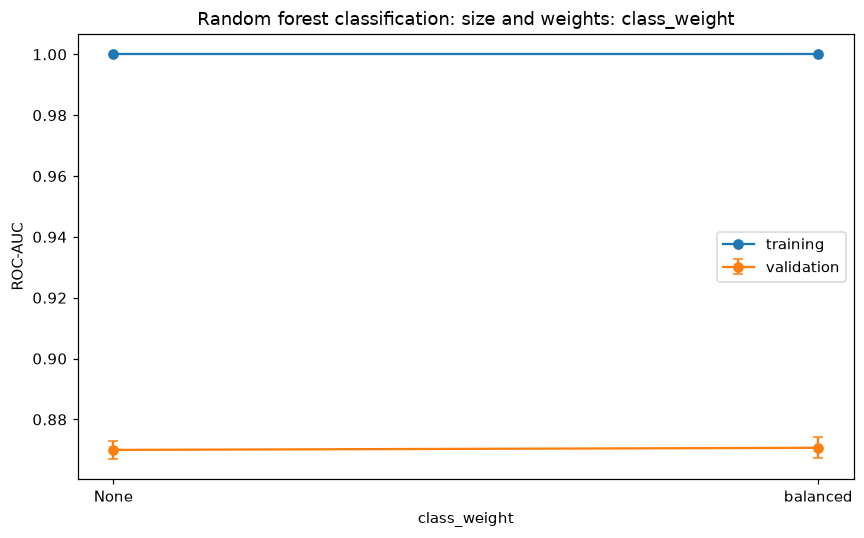

In [ ]:
forest_clf_params = {**forest_size_params, "class_weight": [None, "balanced"]}
forest_clf_grid = GridSearchCV(clone(forest_clf_structure.best_estimator_), forest_clf_params,
                               cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                               n_jobs=N_JOBS, verbose=1)
forest_clf_grid.fit(X, y_sad)
show_search(forest_clf_grid)
plot_search(forest_clf_grid, list(forest_clf_params), "Random forest classification: size and weights")

### 5.3 Gradient boosting

Compare learning rate, depth, and tree count using CV ROC-AUC.

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}


,param_learning_rate,param_max_depth,param_n_estimators,training_score,validation_score,validation_std,rank
17,0.10,5,400,0.933774,0.880805,0.002449,1
23,0.30,3,400,0.921295,0.879428,0.002287,2
20,0.30,2,400,0.895391,0.879387,0.002795,3
14,0.10,3,400,0.895024,0.877459,0.002926,4
22,0.30,3,150,0.897344,0.877084,0.003210,5
25,0.30,5,150,0.937211,0.876025,0.002719,6
16,0.10,5,150,0.903876,0.875048,0.002751,7
8,0.03,5,400,0.897447,0.872592,0.003261,8
24,0.30,5,50,0.902335,0.872104,0.003383,9
26,0.30,5,400,0.977867,0.871517,0.002956,10


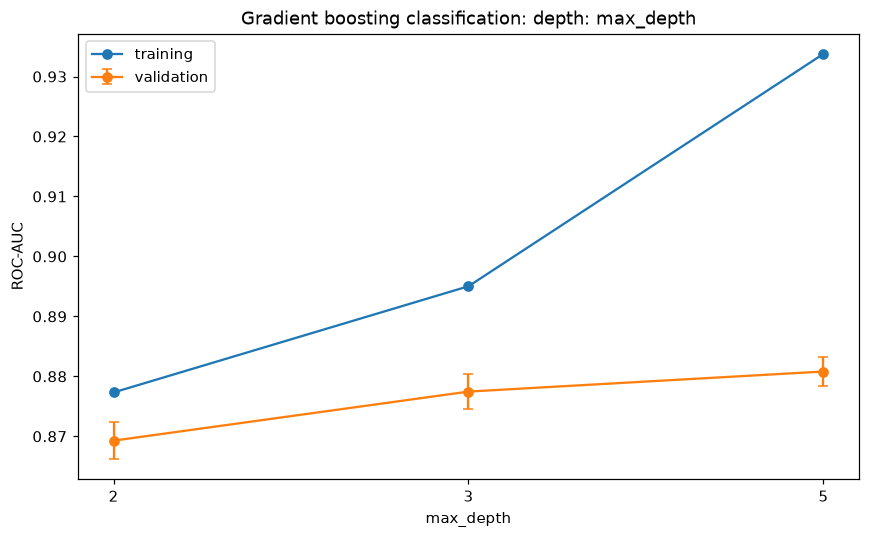

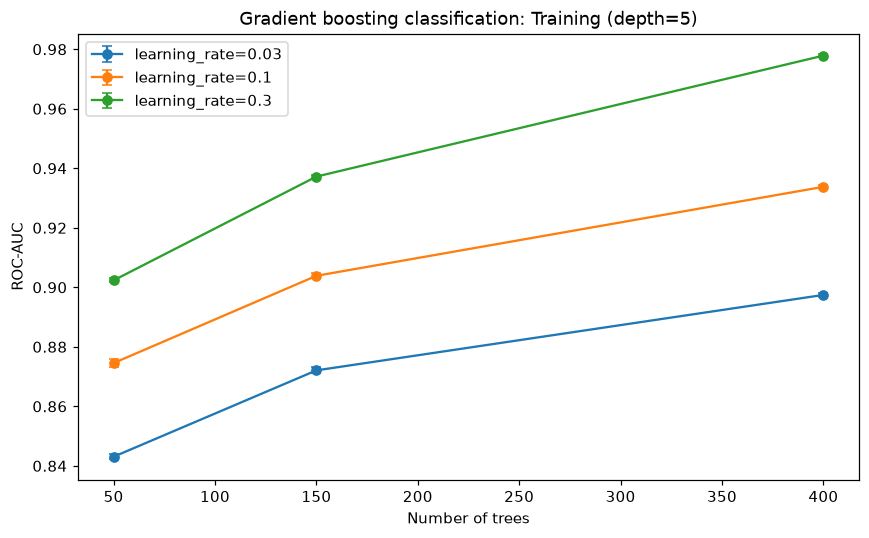

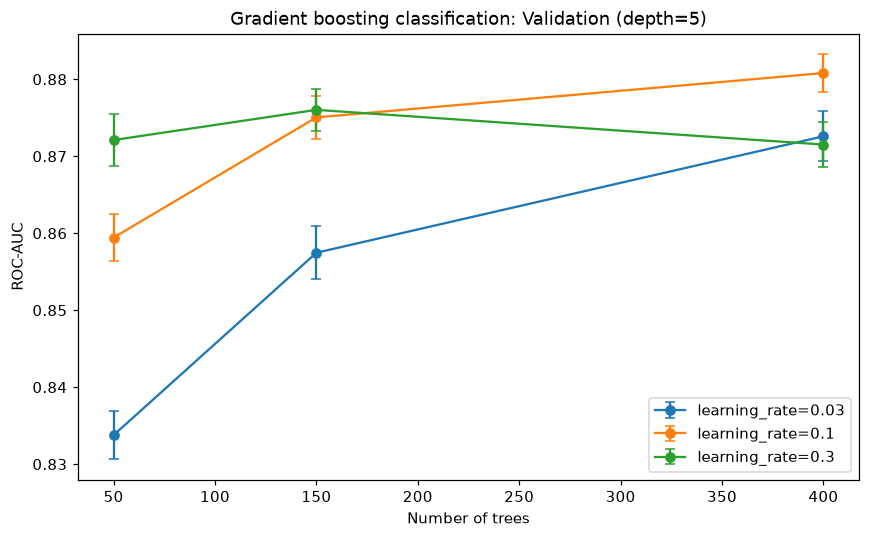

In [ ]:
boost_clf_grid = GridSearchCV(initial_clf["Gradient boosting"], boost_params,
                              cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                              n_jobs=N_JOBS, verbose=2)
boost_clf_grid.fit(X, y_sad)
show_search(boost_clf_grid)
plot_search(boost_clf_grid, ["max_depth"], "Gradient boosting classification: depth")
plot_boosting(boost_clf_grid, "Gradient boosting classification")

### 5.4 Decision thresholds

For each classifier, generate out-of-fold probabilities and test thresholds from 0.05 to 0.95 in steps of 0.01. Select the threshold with the highest OOF F1 and also report F1 at 0.5.

Decision tree (tuned, threshold 0.33): F1 0.6382, ROC-AUC 0.8193, accuracy 0.7481
Decision tree (tuned, threshold 0.50): F1 0.5972, ROC-AUC 0.8193, accuracy 0.7763
Random forest (tuned, threshold 0.45): F1 0.6980, ROC-AUC 0.8706, accuracy 0.7957
Random forest (tuned, threshold 0.50): F1 0.6919, ROC-AUC 0.8706, accuracy 0.8064
Gradient boosting (tuned, threshold 0.36): F1 0.7092, ROC-AUC 0.8808, accuracy 0.8093
Gradient boosting (tuned, threshold 0.50): F1 0.6819, ROC-AUC 0.8808, accuracy 0.8184


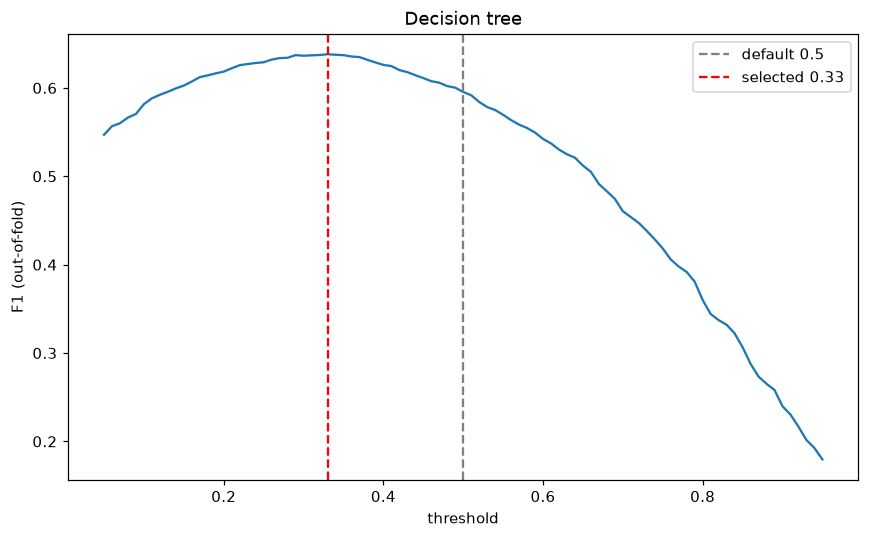

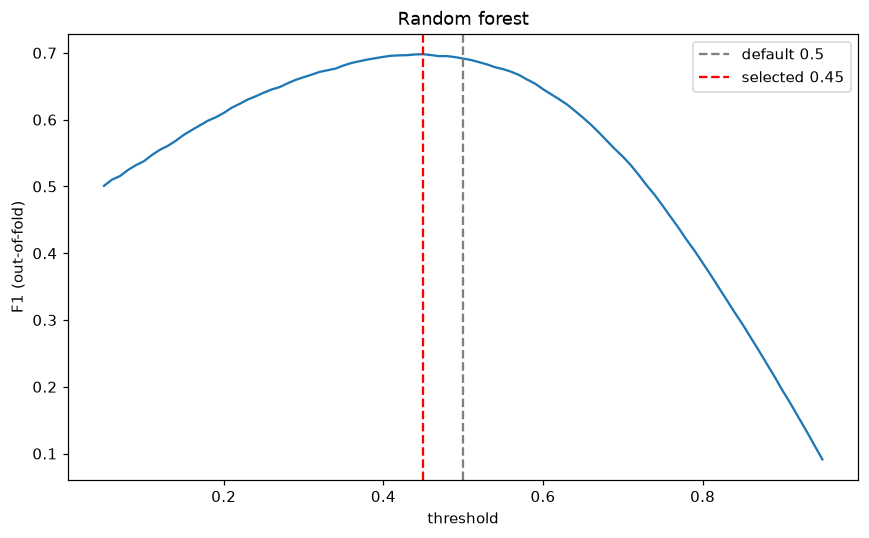

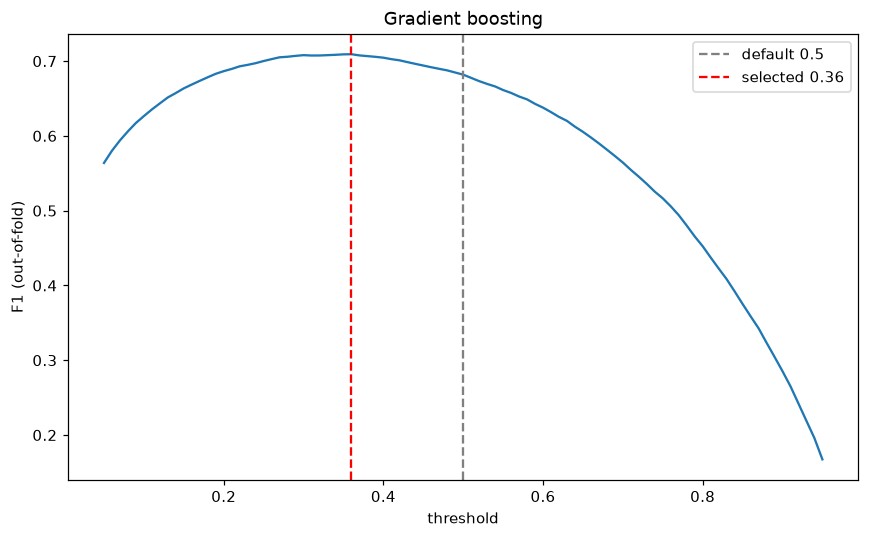

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,Decision tree (initial),0.50,0.5732,0.6908,0.7355,
2,Random forest (initial),0.50,0.6500,0.8663,0.8090,
3,Gradient boosting (initial),0.50,0.6207,0.8565,0.7998,
4,"Decision tree (tuned, threshold 0.33)",0.33,0.6382,0.8193,0.7481,"{'class_weight': None, 'max_depth': 12, 'min_s..."
5,"Decision tree (tuned, threshold 0.50)",0.50,0.5972,0.8193,0.7763,"{'class_weight': None, 'max_depth': 12, 'min_s..."
6,"Random forest (tuned, threshold 0.45)",0.45,0.6980,0.8706,0.7957,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
7,"Random forest (tuned, threshold 0.50)",0.50,0.6919,0.8706,0.8064,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
8,"Gradient boosting (tuned, threshold 0.36)",0.36,0.7092,0.8808,0.8093,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
9,"Gradient boosting (tuned, threshold 0.50)",0.50,0.6819,0.8808,0.8184,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."


In [ ]:
tuned_clf = {
    "Decision tree": tree_clf_grid.best_estimator_,
    "Random forest": forest_clf_grid.best_estimator_,
    "Gradient boosting": boost_clf_grid.best_estimator_,
}
clf_notes = {
    "Decision tree": str(tree_clf_grid.best_params_),
    "Random forest": str({**forest_clf_structure.best_params_, **forest_clf_grid.best_params_}),
    "Gradient boosting": str(boost_clf_grid.best_params_),
}
thresholds = np.arange(0.05, 0.96, 0.01)
best_thresholds = {}
clf_oof = {}

for name, model in tuned_clf.items():
    proba = cross_val_predict(model, X, y_sad, cv=skf, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    clf_oof[name] = proba
    f1s = [f1_score(y_sad, (proba >= t).astype(int)) for t in thresholds]
    best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)
    best_thresholds[name] = best_t
    for t in sorted({0.5, best_t}):
        record_classifier(f"{name} (tuned, threshold {t:.2f})", proba,
                          threshold=t, notes=clf_notes[name])
    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, f1s)
    plt.axvline(0.5, color="gray", ls="--", label="default 0.5")
    plt.axvline(best_t, color="red", ls="--", label=f"selected {best_t:.2f}")
    plt.title(name)
    plt.xlabel("threshold")
    plt.ylabel("F1 (out-of-fold)")
    plt.legend()
    plt.tight_layout()
    plt.show()
pd.DataFrame(clf_results).round(4)

### 5.5 Classification diagnostics

Select the classifier with the highest OOF ROC-AUC and plot its confusion matrix, ROC curve, and precision-recall curve separately.

Selected classifier: Gradient boosting | threshold: 0.36


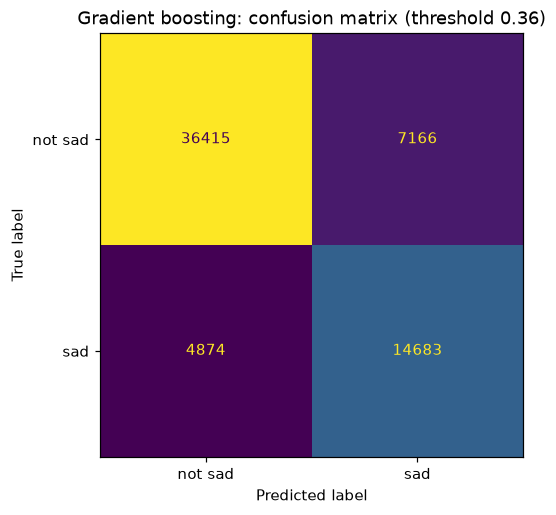

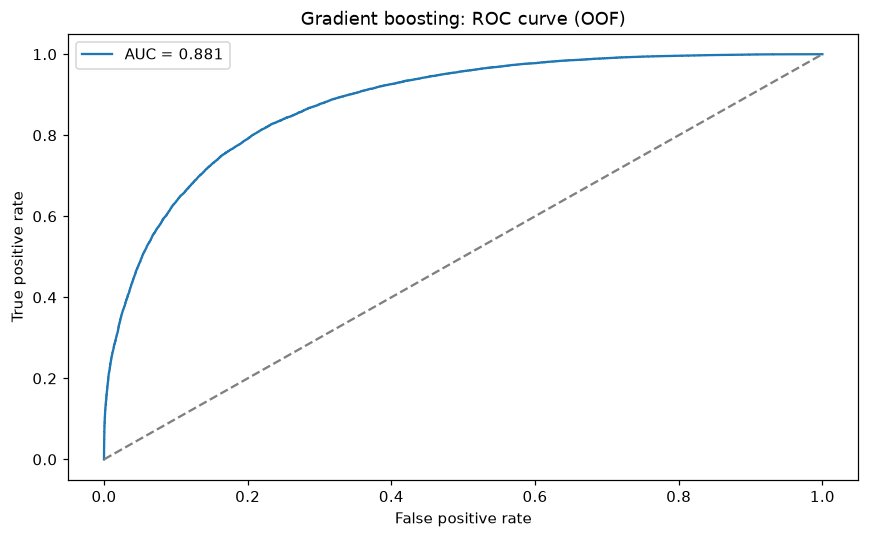

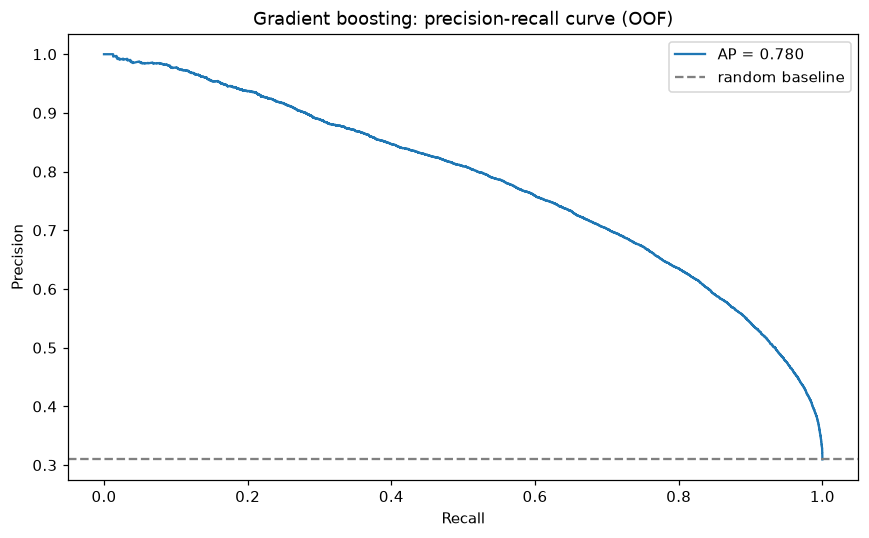

In [ ]:
best_clf_name = max(clf_oof, key=lambda name: roc_auc_score(y_sad, clf_oof[name]))
oof_proba = clf_oof[best_clf_name]
best_t = best_thresholds[best_clf_name]
print("Selected classifier:", best_clf_name, "| threshold:", best_t)

ConfusionMatrixDisplay.from_predictions(y_sad, (oof_proba >= best_t).astype(int),
                                        display_labels=["not sad", "sad"], colorbar=False)
plt.title(f"{best_clf_name}: confusion matrix (threshold {best_t:.2f})")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_sad, oof_proba):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"{best_clf_name}: ROC curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {average_precision_score(y_sad, oof_proba):.3f}")
plt.axhline(y_sad.mean(), color="gray", ls="--", label="random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"{best_clf_name}: precision-recall curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Model interpretation

### 6.1 Decision tree rules

Display the top levels of the selected regression tree using the feature values in the input data.

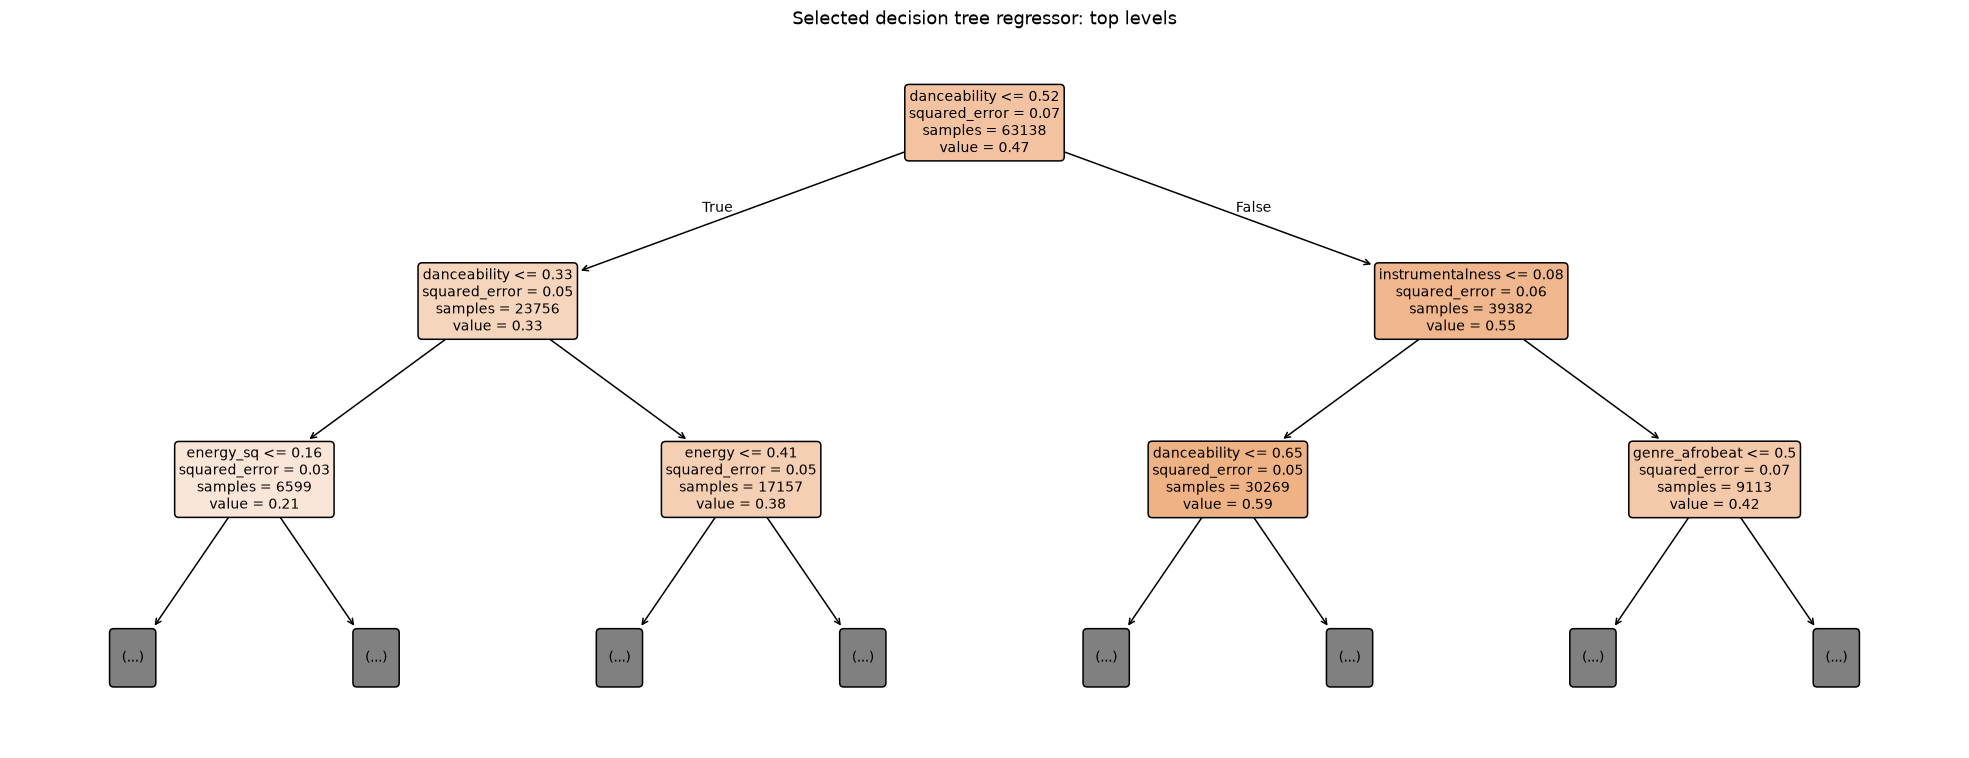

In [ ]:
tree_for_plot = tree_reg_grid.best_estimator_
feature_names = X.columns
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree_for_plot, feature_names=feature_names,
          max_depth=2, filled=True, rounded=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Selected decision tree regressor: top levels")
plt.tight_layout()
plt.show()

### 6.2 Feature importance

For the selected regressor and classifier, plot the 15 largest built-in feature importances. These describe the fitted trees' splits, not causal effects.

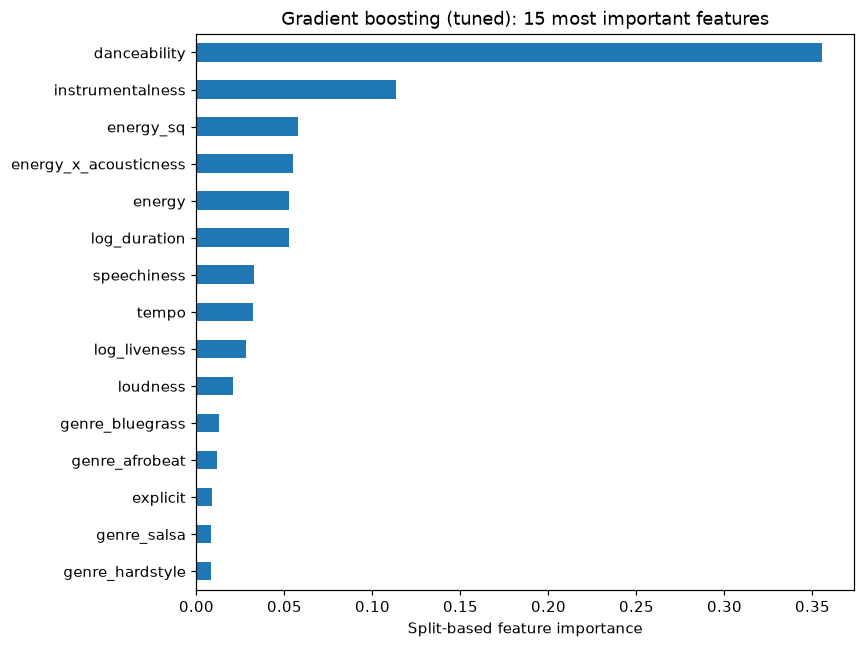

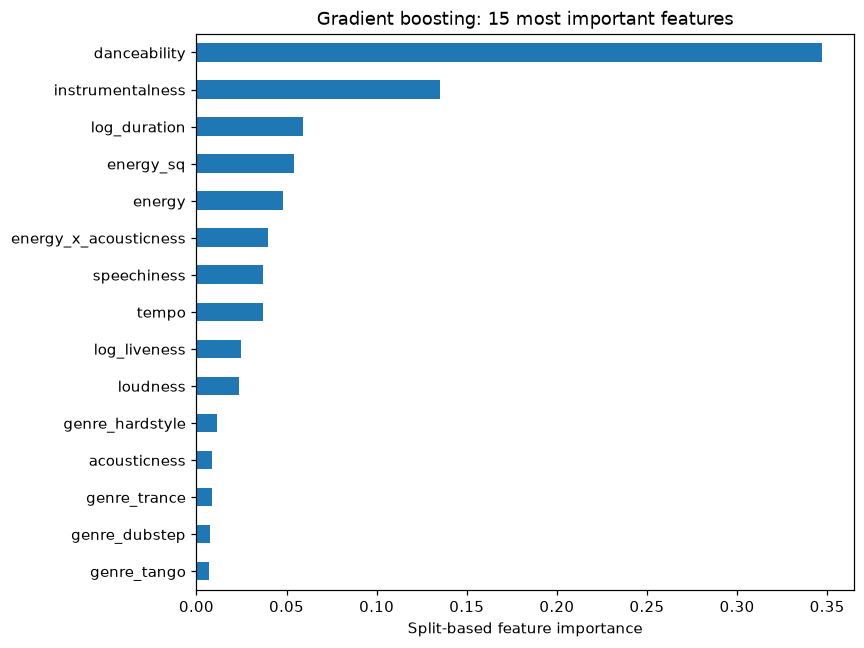

In [ ]:
reg_cv = pd.DataFrame(reg_results).set_index("model")
best_reg_name = reg_cv.loc[list(tuned_reg), "RMSE"].idxmin()
best_reg = tuned_reg[best_reg_name]

for name, model in [(best_reg_name, best_reg), (best_clf_name, tuned_clf[best_clf_name])]:
    importance = pd.Series(model.feature_importances_, index=X.columns)
    importance.sort_values().tail(15).plot.barh(figsize=(8, 6))
    plt.xlabel("Split-based feature importance")
    plt.title(f"{name}: 15 most important features")
    plt.tight_layout()
    plt.show()

### 6.3 Regression errors

Use OOF predictions to plot predicted versus true valence and mean errors by valence range.

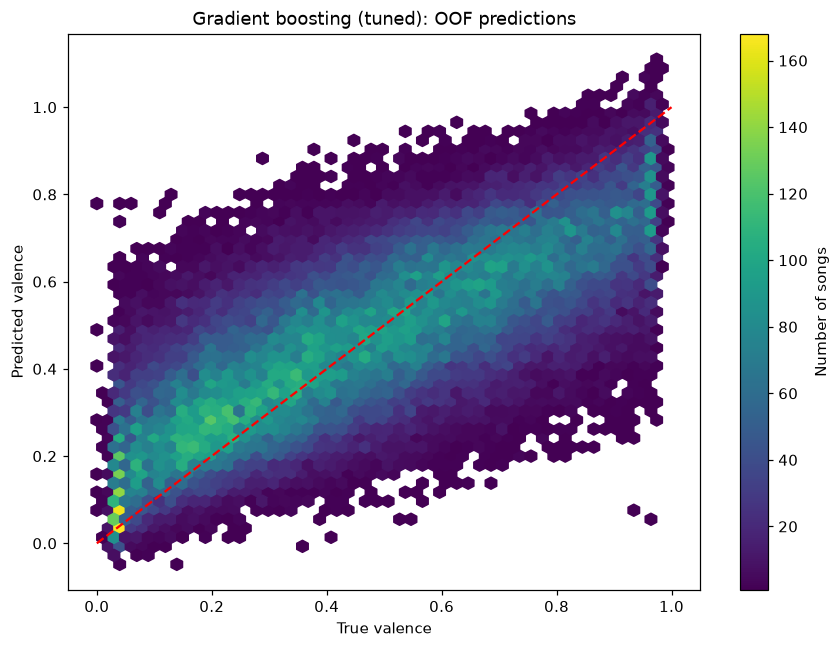

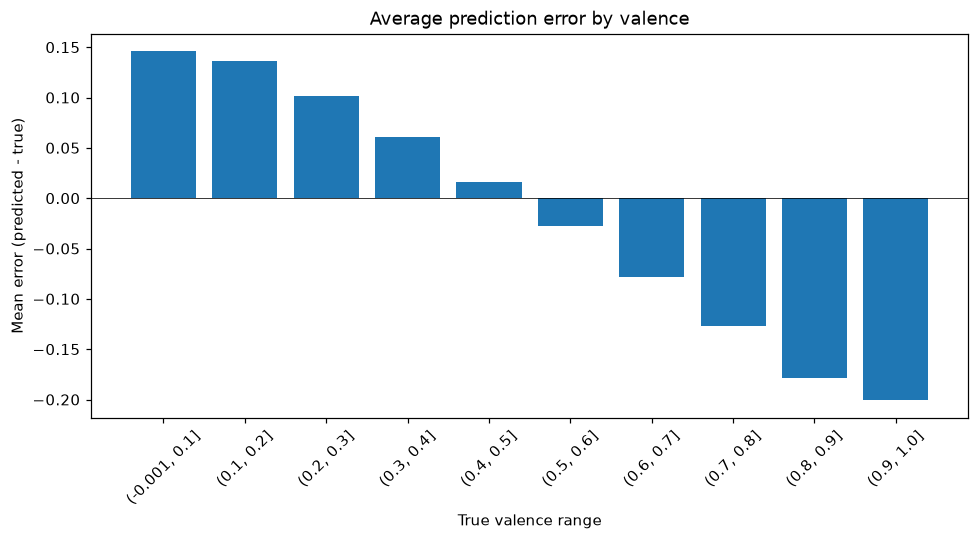

In [ ]:
oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=N_JOBS)
resid = oof_pred - y

plt.figure(figsize=(8, 6))
plt.hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("True valence")
plt.ylabel("Predicted valence")
plt.title(f"{best_reg_name}: OOF predictions")
plt.colorbar(label="Number of songs")
plt.tight_layout()
plt.show()

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
plt.figure(figsize=(9, 5))
plt.bar([str(b) for b in by_bin.index], by_bin.values)
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("True valence range")
plt.ylabel("Mean error (predicted - true)")
plt.title("Average prediction error by valence")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Compare prediction errors across low-, middle-, and high-energy songs with low valence, and songs with valence at least 0.3.

In [ ]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4) ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "low valence, middle energy (0.4 to 0.7)": low & X["energy"].between(0.4, 0.7),
    "valence >= 0.3": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()), "MAE": resid[mask].abs().mean(), "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
display(error_by_group.round(3))

,songs,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.094,0.072
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.160,0.150
"low valence, middle energy (0.4 to 0.7)",5568.0,0.165,0.158
valence >= 0.3,43581.0,0.132,-0.057


## 7. Final test scores

Fit each selected model on the full training set and calculate its test scores. Use the classification thresholds selected from training OOF predictions.

In [ ]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

final_reg = {"Baseline: predict mean": DummyRegressor(strategy="mean"), **tuned_reg}
test_reg = []
for name, model in final_reg.items():
    pred = clone(model).fit(X, y).predict(X_test)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,Decision tree (tuned),0.2002,0.1596,0.4034
2,Random forest (tuned),0.1773,0.1428,0.5321
3,Gradient boosting (tuned),0.1697,0.1339,0.5710


In [ ]:
test_clf = []
base_clf = DummyClassifier(strategy="most_frequent").fit(X, y_sad)
base_pred = base_clf.predict(X_test)
test_clf.append({"model": "Baseline: always 'not sad'",
                 "test F1": f1_score(y_test_sad, base_pred), "test ROC-AUC": 0.5,
                 "test accuracy": (base_pred == y_test_sad).mean()})

for name, model in tuned_clf.items():
    proba = clone(model).fit(X, y_sad).predict_proba(X_test)[:, 1]
    for t in sorted({0.5, best_thresholds[name]}):
        pred = (proba >= t).astype(int)
        test_clf.append({"model": f"{name} (tuned, threshold {t:.2f})",
                         "test F1": f1_score(y_test_sad, pred),
                         "test ROC-AUC": roc_auc_score(y_test_sad, proba),
                         "test accuracy": (pred == y_test_sad).mean()})
pd.DataFrame(test_clf).round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,"Decision tree (tuned, threshold 0.33)",0.6303,0.8129,0.7427
2,"Decision tree (tuned, threshold 0.50)",0.5955,0.8129,0.7744
3,"Random forest (tuned, threshold 0.45)",0.6904,0.8648,0.7886
4,"Random forest (tuned, threshold 0.50)",0.6889,0.8648,0.8029
5,"Gradient boosting (tuned, threshold 0.36)",0.7046,0.8758,0.8035
6,"Gradient boosting (tuned, threshold 0.50)",0.6736,0.8758,0.8141


## 8. Save results

Combine CV and final test scores and save the regression and classification CSV files. Initial models have CV scores only.

In [ ]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left",
                                            validate="one_to_one")
clf_table = pd.DataFrame(clf_results).merge(pd.DataFrame(test_clf), on="model", how="left",
                                            validate="one_to_one")
reg_table.to_csv("results_tree_regression.csv", index=False)
clf_table.to_csv("results_tree_classification.csv", index=False)
print("Saved results_tree_regression.csv and results_tree_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_tree_regression.csv and results_tree_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,Decision tree (initial),0.2574,0.0018,0.1982,0.0358,,NaN,NaN,NaN
2,Random forest (initial),0.1801,0.0010,0.1433,0.5278,,NaN,NaN,NaN
3,Gradient boosting (initial),0.1870,0.0015,0.1521,0.4910,,NaN,NaN,NaN
4,Decision tree (tuned),0.2005,0.0012,0.1597,0.4150,"{'max_depth': 12, 'min_samples_leaf': 50}",0.2002,0.1596,0.4034
5,Random forest (tuned),0.1780,0.0009,0.1440,0.5389,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.1773,0.1428,0.5321
6,Gradient boosting (tuned),0.1695,0.0010,0.1341,0.5820,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.1697,0.1339,0.5710


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,Decision tree (initial),0.50,0.5732,0.6908,0.7355,,NaN,NaN,NaN
2,Random forest (initial),0.50,0.6500,0.8663,0.8090,,NaN,NaN,NaN
3,Gradient boosting (initial),0.50,0.6207,0.8565,0.7998,,NaN,NaN,NaN
4,"Decision tree (tuned, threshold 0.33)",0.33,0.6382,0.8193,0.7481,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.6303,0.8129,0.7427
5,"Decision tree (tuned, threshold 0.50)",0.50,0.5972,0.8193,0.7763,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.5955,0.8129,0.7744
6,"Random forest (tuned, threshold 0.45)",0.45,0.6980,0.8706,0.7957,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.6904,0.8648,0.7886
7,"Random forest (tuned, threshold 0.50)",0.50,0.6919,0.8706,0.8064,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.6889,0.8648,0.8029
8,"Gradient boosting (tuned, threshold 0.36)",0.36,0.7092,0.8808,0.8093,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.7046,0.8758,0.8035
9,"Gradient boosting (tuned, threshold 0.50)",0.50,0.6819,0.8808,0.8184,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.6736,0.8758,0.8141


### Summary

Print the CV-selected models' final test scores and the regression scores before and after tuning.

In [ ]:
reg_selected = reg_table.set_index("model").loc[best_reg_name]
clf_selected_name = f"{best_clf_name} (tuned, threshold {best_t:.2f})"
clf_selected = clf_table.set_index("model").loc[clf_selected_name]
print(f"Selected regressor: {best_reg_name}")
print(f"Test RMSE {reg_selected['test RMSE']:.4f}, MAE {reg_selected['test MAE']:.4f}, "
      f"R2 {reg_selected['test R2']:.4f}")
print(f"Selected classifier: {best_clf_name}, threshold {best_t:.2f}")
print(f"Test F1 {clf_selected['test F1']:.4f}, ROC-AUC {clf_selected['test ROC-AUC']:.4f}")
for name in ["Decision tree", "Random forest", "Gradient boosting"]:
    initial = reg_cv.loc[f"{name} (initial)", "RMSE"]
    tuned = reg_cv.loc[f"{name} (tuned)", "RMSE"]
    print(f"{name}: CV RMSE {initial:.4f} -> {tuned:.4f} (initial -> tuned)")

Selected regressor: Gradient boosting (tuned)
Test RMSE 0.1697, MAE 0.1339, R2 0.5710
Selected classifier: Gradient boosting, threshold 0.36
Test F1 0.7046, ROC-AUC 0.8758
Decision tree: CV RMSE 0.2574 -> 0.2005 (initial -> tuned)
Random forest: CV RMSE 0.1801 -> 0.1780 (initial -> tuned)
Gradient boosting: CV RMSE 0.1870 -> 0.1695 (initial -> tuned)


---

# Part 6: kNN and Neural Network Models

*By Damien Wilson.*

A k-nearest-neighbors model (k chosen by cross-validation) and a small neural network predict continuous valence (regression) and the sad label (valence < 0.3, classification).
The inputs are the 141 numeric features in train_features.csv; test_features.csv is used for final scoring.
The setup, folds, metrics, and thresholds match Part 5 (tree models) so the results can be compared directly.

## 1. Setup

Import the libraries and set the random seed and number of parallel CPU fits.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3
N_JOBS = 2

Load the training features and targets. The text column track_genre is excluded because genre is already represented by the genre_* columns.

In [ ]:
train_df = pd.read_csv("train_features.csv")

X = train_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y = train_df["valence"]
y_sad = train_df["sad"]

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 141)
Share of sad songs: 31.0%


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,log_liveness,tempo,log_duration,mode,explicit,key_0,key_1,key_2,key_3,key_4,key_5,key_6,key_7,key_8,key_9,key_10,key_11,is_4_4,is_instrumental,is_slow,energy_sq,acousticness_sq,energy_x_acousticness,genre_acoustic,genre_afrobeat,genre_alt-rock,genre_alternative,genre_ambient,genre_anime,genre_black-metal,genre_bluegrass,genre_blues,genre_brazil,genre_breakbeat,genre_british,genre_cantopop,genre_chicago-house,genre_children,genre_chill,genre_classical,genre_club,genre_country,genre_dance,genre_dancehall,genre_death-metal,genre_deep-house,genre_detroit-techno,genre_disco,genre_disney,genre_drum-and-bass,genre_dub,genre_dubstep,genre_edm,genre_electro,genre_electronic,genre_emo,genre_folk,genre_forro,genre_french,genre_funk,genre_garage,genre_german,genre_gospel,genre_goth,genre_grindcore,genre_groove,genre_grunge,genre_guitar,genre_happy,genre_hard-rock,genre_hardcore,genre_hardstyle,genre_heavy-metal,genre_hip-hop,genre_honky-tonk,genre_house,genre_idm,genre_indian,genre_indie,genre_indie-pop,genre_industrial,genre_iranian,genre_j-dance,genre_j-idol,genre_j-pop,genre_j-rock,genre_jazz,genre_k-pop,genre_kids,genre_latin,genre_latino,genre_malay,genre_mandopop,genre_metal,genre_metalcore,genre_minimal-techno,genre_mpb,genre_new-age,genre_opera,genre_pagode,genre_party,genre_piano,genre_pop,genre_pop-film,genre_power-pop,genre_progressive-house,genre_psych-rock,genre_punk,genre_punk-rock,genre_r-n-b,genre_reggae,genre_reggaeton,genre_rock,genre_rock-n-roll,genre_rockabilly,genre_romance,genre_sad,genre_salsa,genre_samba,genre_sertanejo,genre_show-tunes,genre_singer-songwriter,genre_ska,genre_songwriter,genre_soul,genre_spanish,genre_study,genre_swedish,genre_synth-pop,genre_tango,genre_techno,genre_trance,genre_trip-hop,genre_turkish,genre_world-music
0,0.345,0.351,-7.844,0.0343,0.7130,0.000000,-2.434974,96.538,11.926888,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0.123201,0.508369,0.250263,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.469,0.650,-9.220,0.0344,0.0450,0.001110,-1.465338,123.929,12.995075,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0.422500,0.002025,0.029250,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0.622,0.459,-15.283,0.0449,0.0813,0.111000,-2.244316,135.033,12.737116,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0.210681,0.006610,0.037317,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0.320,0.384,-10.710,0.0362,0.2960,0.000006,-2.519498,119.353,12.634603,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0.147456,0.087616,0.113664,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0.524,0.515,-7.478,0.0427,0.6740,0.000000,-2.263364,169.882,12.163410,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0.265225,0.454276,0.347110,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Both models depend on distances or gradient steps, so features on large scales would dominate the rest. Every model below is a pipeline that standardizes the features inside each training fold, which keeps validation data from influencing the scaling.

## 2. Cross-validation

Create five shuffled folds for regression and five stratified folds for classification.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### Evaluation functions

Calculate regression RMSE, MAE, and R2 using five-fold CV. Classification uses out-of-fold probabilities to calculate F1, ROC-AUC, and accuracy.

In [ ]:
reg_results = []
clf_results = []

def eval_regressor(name, model, notes=""):
    scores = cross_validate(model, X, y, cv=kf, n_jobs=N_JOBS, error_score="raise",
                            scoring={"rmse": "neg_root_mean_squared_error",
                                     "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -scores["test_rmse"].mean(), "RMSE_std": scores["test_rmse"].std(),
           "MAE": -scores["test_mae"].mean(), "R2": scores["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), "
          f"MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def record_classifier(name, proba, threshold=0.5, notes=""):
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_sad, pred), "ROC_AUC": roc_auc_score(y_sad, proba),
           "accuracy": (pred == y_sad).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, "
          f"accuracy {row['accuracy']:.4f}")
    return row

def eval_classifier(name, model, notes=""):
    proba = cross_val_predict(model, X, y_sad, cv=skf,
                             method="predict_proba", n_jobs=N_JOBS)[:, 1]
    record_classifier(name, proba, notes=notes)
    return proba

### Tuning tables and plots

Display candidate scores and plot one parameter at a time, holding the other parameters at their selected values. Each plot is a separate figure.

In [ ]:
def show_search(search):
    print("Best parameters:", search.best_params_)
    results = pd.DataFrame(search.cv_results_)
    parameters = [c for c in results if c.startswith("param_")]
    score_cols = [c for c in ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"] if c in results]
    table = results[parameters + score_cols].copy()
    if search.scoring == "neg_root_mean_squared_error":
        for c in ["mean_train_score", "mean_test_score"]:
            if c in table:
                table[c] *= -1
    display(table.rename(columns={"mean_train_score": "training_score",
                                  "mean_test_score": "validation_score",
                                  "std_test_score": "validation_std",
                                  "rank_test_score": "rank"}).sort_values("rank"))

def plot_search(search, parameters, title):
    for parameter in parameters:
        results = pd.DataFrame(search.cv_results_)
        for other, value in search.best_params_.items():
            if other != parameter:
                results = results[[p[other] == value for p in results["params"]]]
        sign = -1 if search.scoring == "neg_root_mean_squared_error" else 1
        positions = np.arange(len(results))
        labels = [str(p[parameter]) for p in results["params"]]
        plt.figure(figsize=(8, 5))
        if "mean_train_score" in results:
            plt.plot(positions, sign * results["mean_train_score"], "o-", label="training")
        plt.errorbar(positions, sign * results["mean_test_score"],
                     yerr=results["std_test_score"], fmt="o-", capsize=3, label="validation")
        plt.xticks(positions, labels)
        plt.xlabel(parameter)
        plt.ylabel("RMSE" if sign == -1 else "ROC-AUC")
        plt.title(f"{title}: {parameter}")
        plt.legend()
        plt.tight_layout()
        plt.show()

## 3. Initial models

Evaluate the mean-valence and always-not-sad baselines, then evaluate each model with its default settings. The initial kNN uses k = 5. The initial neural network has one hidden layer of 100 units with early stopping on a 10% validation split.

In [ ]:
def make_knn(task):
    est = KNeighborsRegressor() if task == "reg" else KNeighborsClassifier()
    return Pipeline([("scale", StandardScaler()), ("knn", est)])

def make_mlp(task):
    kwargs = dict(early_stopping=True, n_iter_no_change=10, max_iter=300, random_state=RANDOM_STATE)
    est = MLPRegressor(**kwargs) if task == "reg" else MLPClassifier(**kwargs)
    return Pipeline([("scale", StandardScaler()), ("mlp", est)])

initial_reg = {"kNN": make_knn("reg"), "Neural network": make_mlp("reg")}
initial_clf = {"kNN": make_knn("clf"), "Neural network": make_mlp("clf")}

eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"))
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"));

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000
Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


In [ ]:
for name, model in initial_reg.items():
    eval_regressor(f"{name} (initial)", model)
pd.DataFrame(reg_results).round(4)

kNN (initial): RMSE 0.2070 (+/- 0.0009), MAE 0.1645, R2 0.3763
Neural network (initial): RMSE 0.1780 (+/- 0.0011), MAE 0.1404, R2 0.5388


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,


In [ ]:
for name, model in initial_clf.items():
    eval_classifier(f"{name} (initial)", model)
pd.DataFrame(clf_results).round(4)

kNN (initial): F1 0.5822, ROC-AUC 0.7865, accuracy 0.7644
Neural network (initial): F1 0.6643, ROC-AUC 0.8662, accuracy 0.8076


,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.5,0.0000,0.5000,0.6902,
1,kNN (initial),0.5,0.5822,0.7865,0.7644,
2,Neural network (initial),0.5,0.6643,0.8662,0.8076,


## 4. Regression tuning

Select parameters by the lowest mean CV RMSE.

### 4.1 kNN

Choose k by cross-validation. Small k fits the training data closely and is noisy; large k averages over many songs and smooths the prediction. Distance weighting is also compared with equal weighting.

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'knn__n_neighbors': 80, 'knn__weights': 'distance'}


,param_knn__n_neighbors,param_knn__weights,training_score,validation_score,validation_std,rank
7,80,distance,-0.000000,0.197618,0.000764,1
6,80,uniform,0.195920,0.198485,0.000775,2
5,40,distance,-0.000000,0.198866,0.000757,3
3,20,distance,-0.000000,0.199806,0.000812,4
9,160,distance,-0.000000,0.199922,0.000728,5
4,40,uniform,0.195402,0.200520,0.000741,6
1,10,distance,-0.000000,0.200709,0.000991,7
8,160,uniform,0.199587,0.200923,0.000729,8
2,20,uniform,0.191693,0.201976,0.000785,9
0,10,uniform,0.182423,0.202522,0.000992,10


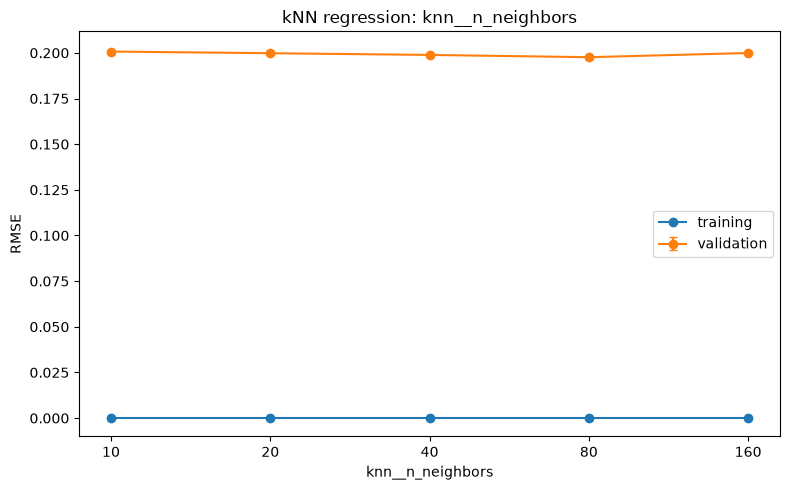

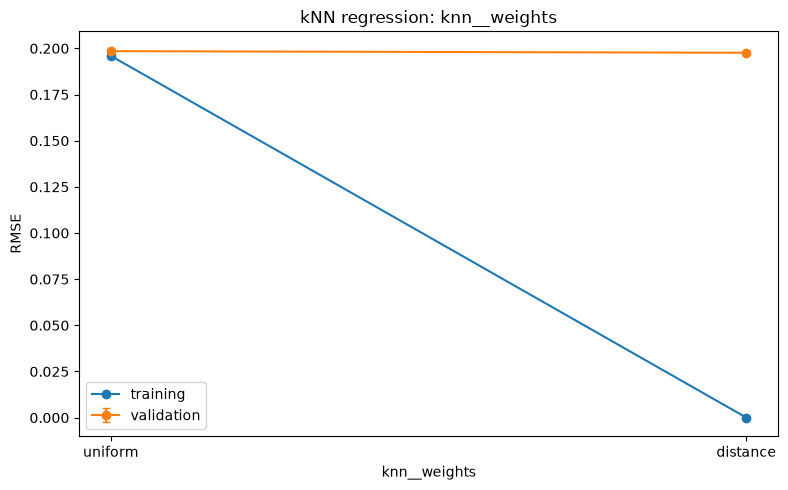

In [ ]:
knn_params = {
    "knn__n_neighbors": [10, 20, 40, 80, 160],
    "knn__weights": ["uniform", "distance"],
}
knn_reg_grid = GridSearchCV(initial_reg["kNN"], knn_params,
                            cv=kf, scoring="neg_root_mean_squared_error",
                            return_train_score=True, error_score="raise", n_jobs=-1, verbose=1)
knn_reg_grid.fit(X, y)
show_search(knn_reg_grid)
plot_search(knn_reg_grid, list(knn_params), "kNN regression")

### 4.2 Neural network

Compare the hidden layer sizes and the L2 penalty (alpha). The network is kept small: one or two hidden layers with ReLU activations, the Adam optimizer, and early stopping.

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (64, 32)}


,param_mlp__alpha,param_mlp__hidden_layer_sizes,training_score,validation_score,validation_std,rank
8,0.1000,"(64, 32)",0.167063,0.173646,0.001088,1
7,0.1000,"(64,)",0.167585,0.174911,0.000739,2
6,0.1000,"(16,)",0.170292,0.175219,0.001458,3
3,0.0100,"(16,)",0.170550,0.175320,0.001140,4
0,0.0001,"(16,)",0.171253,0.175882,0.000302,5
4,0.0100,"(64,)",0.164295,0.176097,0.000613,6
5,0.0100,"(64, 32)",0.160368,0.176774,0.001131,7
1,0.0001,"(64,)",0.165568,0.177114,0.000914,8
2,0.0001,"(64, 32)",0.161966,0.179056,0.001515,9


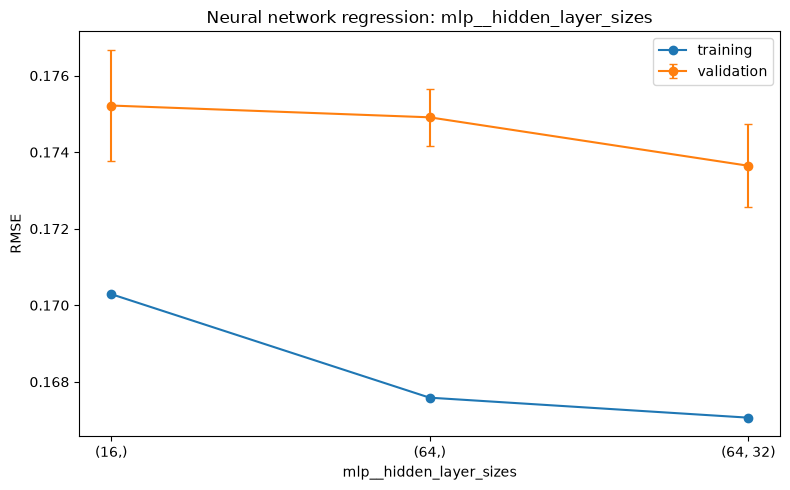

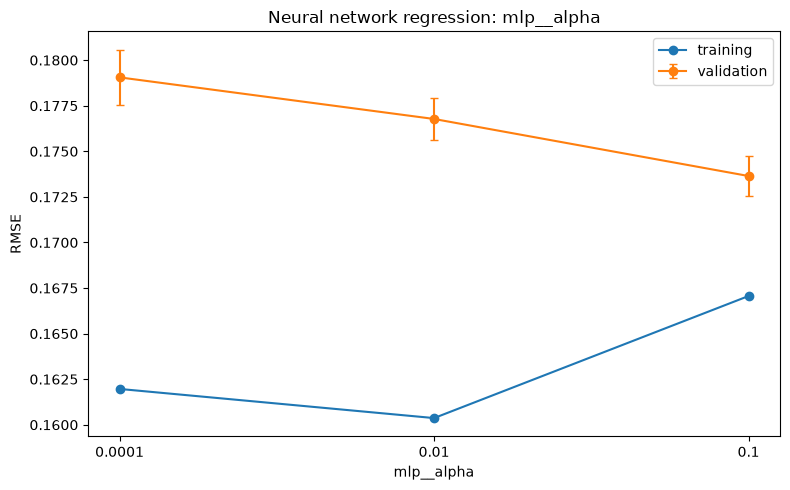

In [ ]:
mlp_params = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],
    "mlp__alpha": [1e-4, 1e-2, 1e-1],
}
mlp_reg_grid = GridSearchCV(initial_reg["Neural network"], mlp_params,
                            cv=kf, scoring="neg_root_mean_squared_error",
                            return_train_score=True, error_score="raise", n_jobs=N_JOBS, verbose=1)
mlp_reg_grid.fit(X, y)
show_search(mlp_reg_grid)
plot_search(mlp_reg_grid, list(mlp_params), "Neural network regression")

### 4.3 Tuned regression scores

Calculate RMSE, MAE, and R2 for each selected regressor and record its parameters.

In [ ]:
tuned_reg = {
    "kNN (tuned)": knn_reg_grid.best_estimator_,
    "Neural network (tuned)": mlp_reg_grid.best_estimator_,
}
reg_notes = {
    "kNN (tuned)": str(knn_reg_grid.best_params_),
    "Neural network (tuned)": str(mlp_reg_grid.best_params_),
}
for name, model in tuned_reg.items():
    eval_regressor(name, model, notes=reg_notes[name])
pd.DataFrame(reg_results).round(4)

kNN (tuned): RMSE 0.1976 (+/- 0.0008), MAE 0.1606, R2 0.4317
Neural network (tuned): RMSE 0.1736 (+/- 0.0011), MAE 0.1374, R2 0.5612


,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,
3,kNN (tuned),0.1976,0.0008,0.1606,0.4317,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
4,Neural network (tuned),0.1736,0.0011,0.1374,0.5612,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."


## 5. Classification tuning

Select classifier parameters by the highest mean CV ROC-AUC.

### 5.1 kNN

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'knn__n_neighbors': 80, 'knn__weights': 'distance'}


,param_knn__n_neighbors,param_knn__weights,training_score,validation_score,validation_std,rank
7,80,distance,1.000000,0.831778,0.002035,1
6,80,uniform,0.840261,0.829770,0.002380,2
9,160,distance,1.000000,0.828197,0.002088,3
5,40,distance,1.000000,0.826397,0.001216,4
8,160,uniform,0.830929,0.825561,0.002448,5
4,40,uniform,0.843329,0.822842,0.001567,6
3,20,distance,1.000000,0.819176,0.002177,7
2,20,uniform,0.854007,0.814022,0.002487,8
1,10,distance,1.000000,0.810333,0.001820,9
0,10,uniform,0.876083,0.805468,0.001818,10


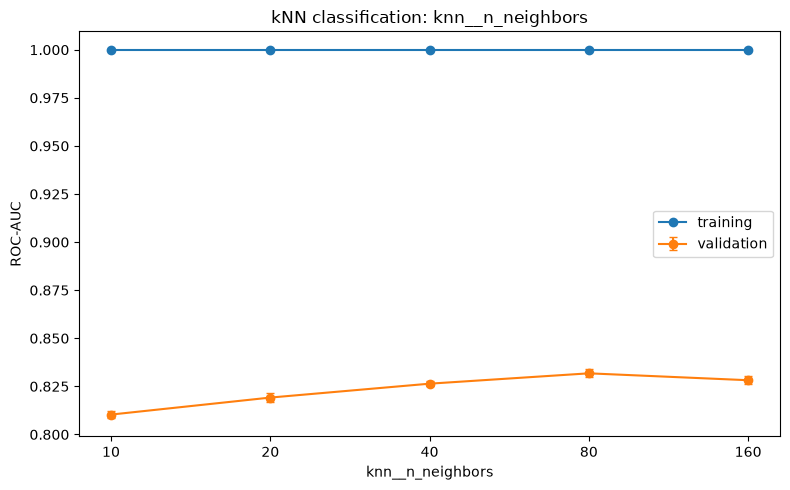

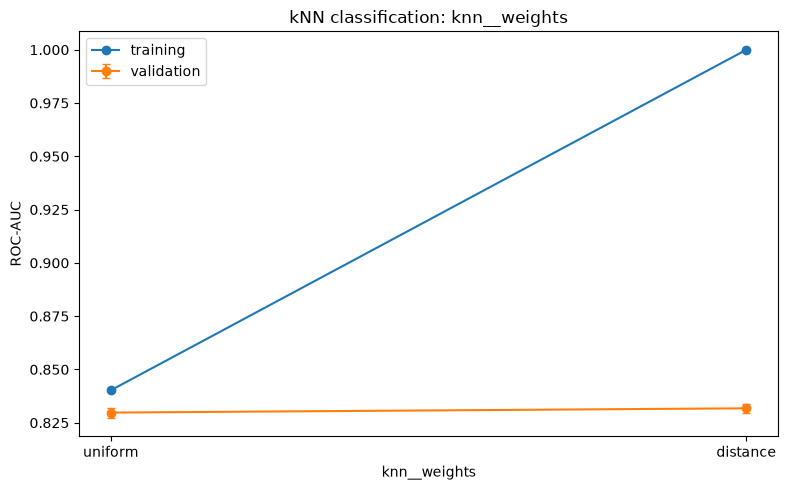

In [ ]:
knn_clf_grid = GridSearchCV(initial_clf["kNN"], knn_params,
                            cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                            n_jobs=N_JOBS, verbose=1)
knn_clf_grid.fit(X, y_sad)
show_search(knn_clf_grid)
plot_search(knn_clf_grid, list(knn_params), "kNN classification")

### 5.2 Neural network

Fitting 5 folds for each of 9 candidates, totalling 45 fits
Best parameters: {'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (16,)}


,param_mlp__alpha,param_mlp__hidden_layer_sizes,training_score,validation_score,validation_std,rank
6,0.1000,"(16,)",0.883592,0.870373,0.002656,1
7,0.1000,"(64,)",0.895681,0.869702,0.002218,2
4,0.0100,"(64,)",0.888667,0.869545,0.002786,3
1,0.0001,"(64,)",0.890069,0.869038,0.003790,4
0,0.0001,"(16,)",0.880463,0.868789,0.002429,5
3,0.0100,"(16,)",0.877561,0.868453,0.003560,6
2,0.0001,"(64, 32)",0.897602,0.868334,0.002158,7
8,0.1000,"(64, 32)",0.891430,0.868266,0.002067,8
5,0.0100,"(64, 32)",0.894869,0.867781,0.002370,9


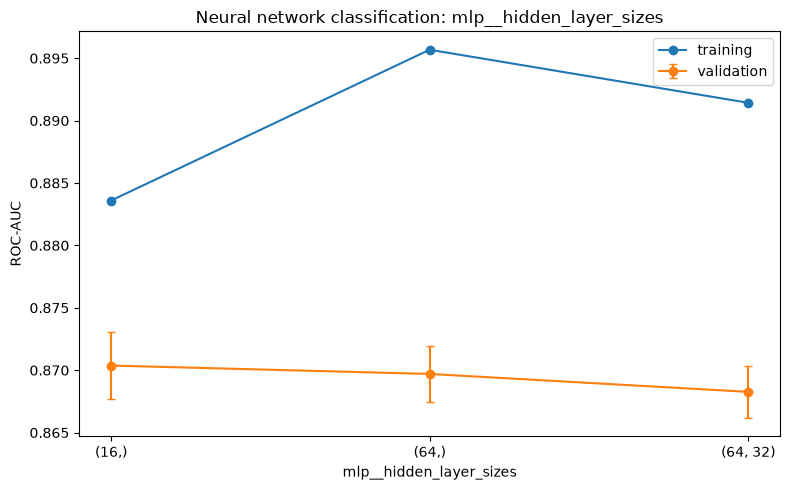

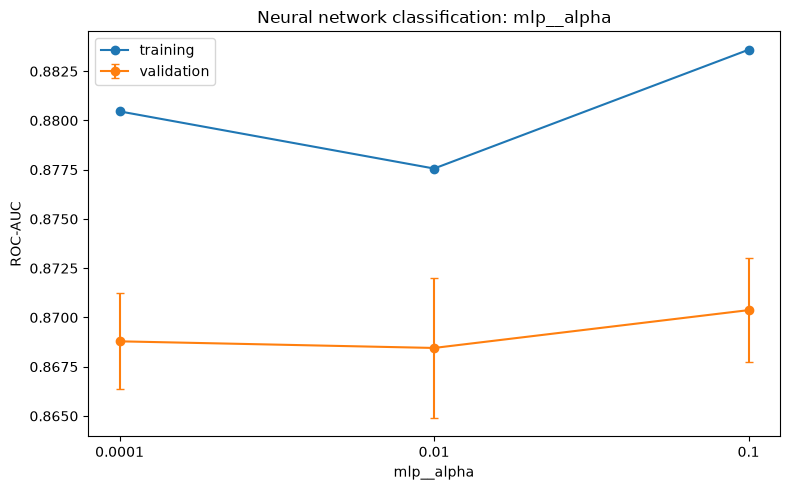

In [ ]:
mlp_clf_grid = GridSearchCV(initial_clf["Neural network"], mlp_params,
                            cv=skf, scoring="roc_auc", return_train_score=True, error_score="raise",
                            n_jobs=N_JOBS, verbose=1)
mlp_clf_grid.fit(X, y_sad)
show_search(mlp_clf_grid)
plot_search(mlp_clf_grid, list(mlp_params), "Neural network classification")

### 5.3 Decision thresholds

For each classifier, generate out-of-fold probabilities and test thresholds from 0.05 to 0.95 in steps of 0.01. Select the threshold with the highest OOF F1 and also report F1 at 0.5.

kNN (tuned, threshold 0.32): F1 0.6505, ROC-AUC 0.8317, accuracy 0.7562
kNN (tuned, threshold 0.50): F1 0.5862, ROC-AUC 0.8317, accuracy 0.7841


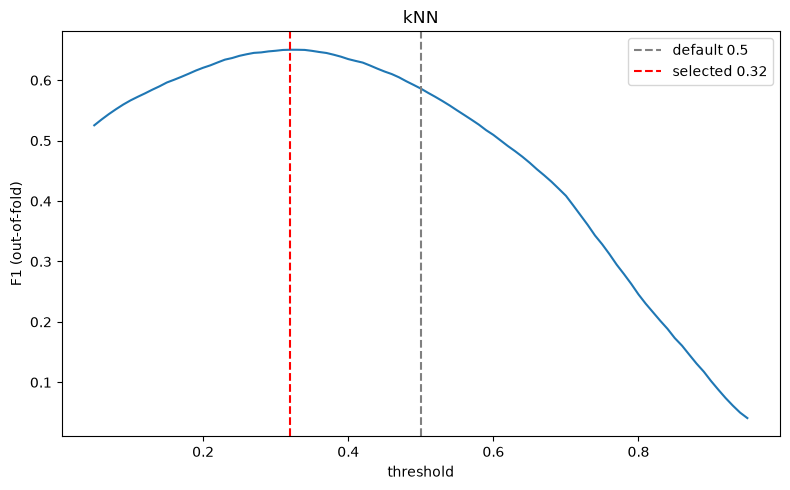

Neural network (tuned, threshold 0.35): F1 0.6967, ROC-AUC 0.8702, accuracy 0.7948
Neural network (tuned, threshold 0.50): F1 0.6698, ROC-AUC 0.8702, accuracy 0.8101


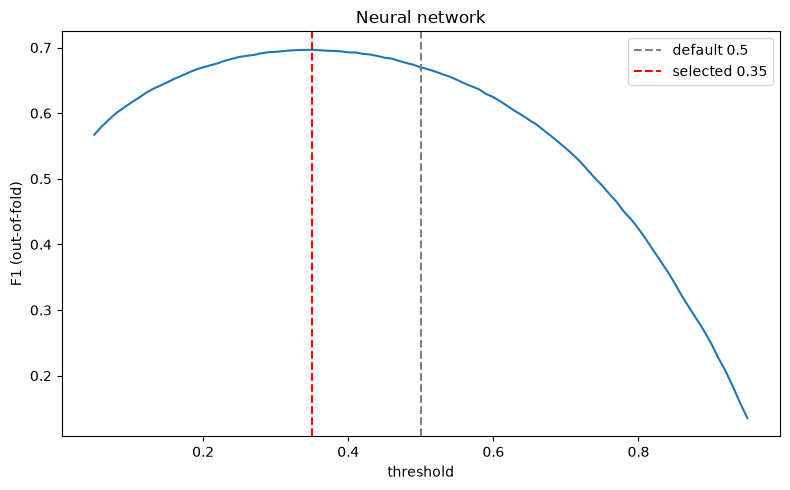

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,kNN (initial),0.50,0.5822,0.7865,0.7644,
2,Neural network (initial),0.50,0.6643,0.8662,0.8076,
3,"kNN (tuned, threshold 0.32)",0.32,0.6505,0.8317,0.7562,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
4,"kNN (tuned, threshold 0.50)",0.50,0.5862,0.8317,0.7841,"{'knn__n_neighbors': 80, 'knn__weights': 'dist..."
5,"Neural network (tuned, threshold 0.35)",0.35,0.6967,0.8702,0.7948,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."
6,"Neural network (tuned, threshold 0.50)",0.50,0.6698,0.8702,0.8101,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':..."


In [ ]:
tuned_clf = {
    "kNN": knn_clf_grid.best_estimator_,
    "Neural network": mlp_clf_grid.best_estimator_,
}
clf_notes = {
    "kNN": str(knn_clf_grid.best_params_),
    "Neural network": str(mlp_clf_grid.best_params_),
}
thresholds = np.arange(0.05, 0.96, 0.01)
best_thresholds = {}
clf_oof = {}

for name, model in tuned_clf.items():
    proba = cross_val_predict(model, X, y_sad, cv=skf, method="predict_proba", n_jobs=N_JOBS)[:, 1]
    clf_oof[name] = proba
    f1s = [f1_score(y_sad, (proba >= t).astype(int)) for t in thresholds]
    best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)
    best_thresholds[name] = best_t
    for t in sorted({0.5, best_t}):
        record_classifier(f"{name} (tuned, threshold {t:.2f})", proba,
                          threshold=t, notes=clf_notes[name])
    plt.figure(figsize=(8, 5))
    plt.plot(thresholds, f1s)
    plt.axvline(0.5, color="gray", ls="--", label="default 0.5")
    plt.axvline(best_t, color="red", ls="--", label=f"selected {best_t:.2f}")
    plt.title(name)
    plt.xlabel("threshold")
    plt.ylabel("F1 (out-of-fold)")
    plt.legend()
    plt.tight_layout()
    plt.show()
pd.DataFrame(clf_results).round(4)

### 5.4 Classification diagnostics

Select the classifier with the highest OOF ROC-AUC and plot its confusion matrix, ROC curve, and precision-recall curve separately.

Selected classifier: Neural network | threshold: 0.35


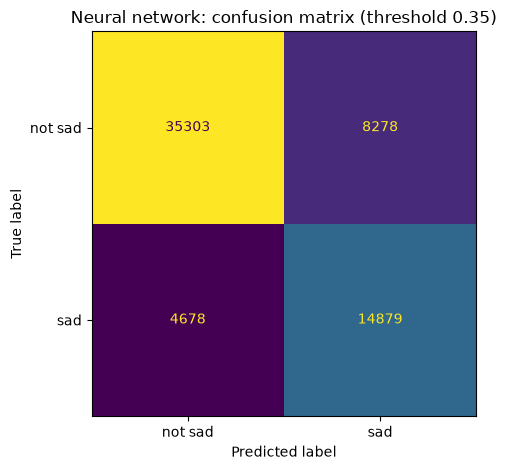

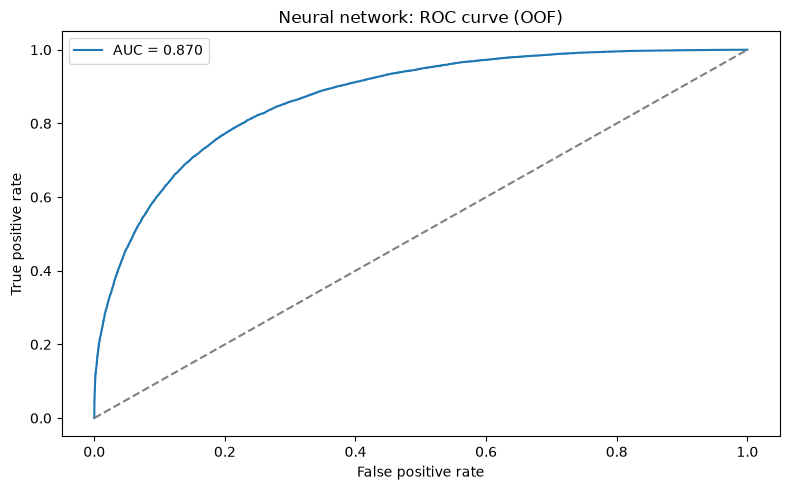

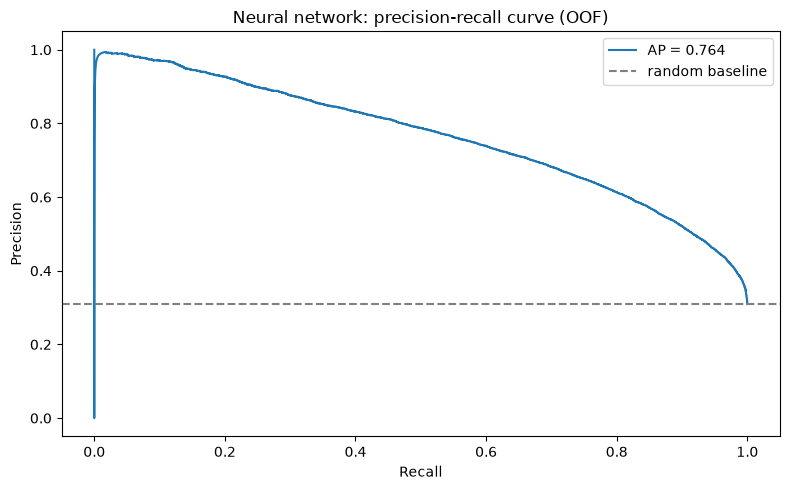

In [ ]:
best_clf_name = max(clf_oof, key=lambda name: roc_auc_score(y_sad, clf_oof[name]))
oof_proba = clf_oof[best_clf_name]
best_t = best_thresholds[best_clf_name]
print("Selected classifier:", best_clf_name, "| threshold:", best_t)

ConfusionMatrixDisplay.from_predictions(y_sad, (oof_proba >= best_t).astype(int),
                                        display_labels=["not sad", "sad"], colorbar=False)
plt.title(f"{best_clf_name}: confusion matrix (threshold {best_t:.2f})")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_sad, oof_proba):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"{best_clf_name}: ROC curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

precision, recall, _ = precision_recall_curve(y_sad, oof_proba)
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"AP = {average_precision_score(y_sad, oof_proba):.3f}")
plt.axhline(y_sad.mean(), color="gray", ls="--", label="random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"{best_clf_name}: precision-recall curve (OOF)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Model interpretation

### 6.1 Regression errors

Use OOF predictions from the selected regressor to plot predicted versus true valence and mean errors by valence range. Neither kNN nor a neural network has built-in feature importances, so this section looks at errors instead.

Selected regressor: Neural network (tuned)


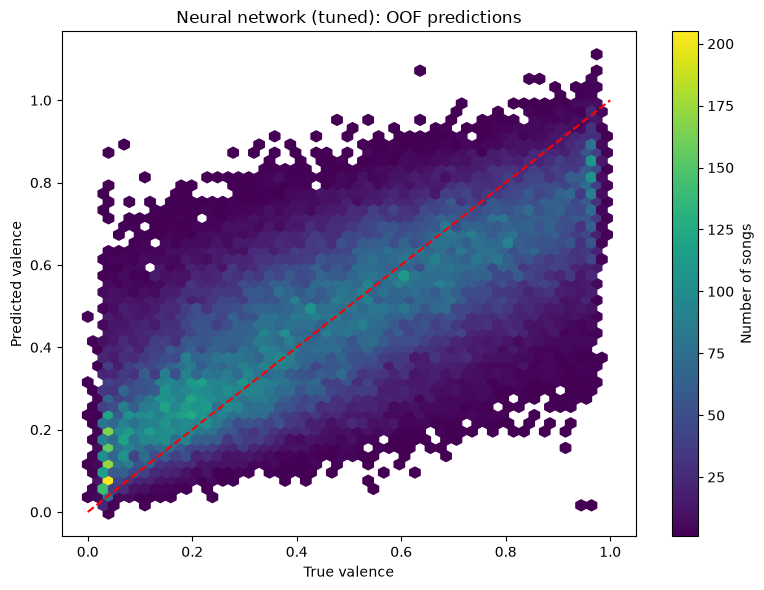

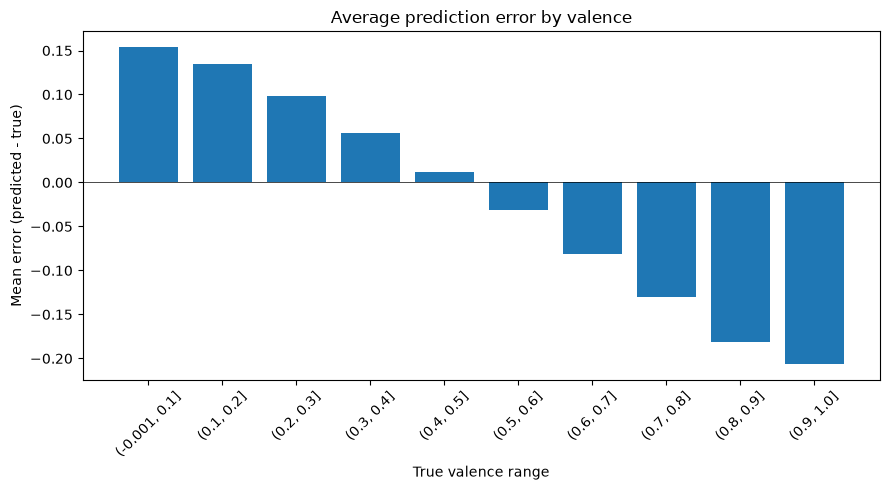

In [ ]:
reg_cv = pd.DataFrame(reg_results).set_index("model")
best_reg_name = reg_cv.loc[list(tuned_reg), "RMSE"].idxmin()
best_reg = tuned_reg[best_reg_name]
print("Selected regressor:", best_reg_name)

oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=N_JOBS)
resid = oof_pred - y

plt.figure(figsize=(8, 6))
plt.hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
plt.plot([0, 1], [0, 1], "--", color="red")
plt.xlabel("True valence")
plt.ylabel("Predicted valence")
plt.title(f"{best_reg_name}: OOF predictions")
plt.colorbar(label="Number of songs")
plt.tight_layout()
plt.show()

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
plt.figure(figsize=(9, 5))
plt.bar([str(b) for b in by_bin.index], by_bin.values)
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("True valence range")
plt.ylabel("Mean error (predicted - true)")
plt.title("Average prediction error by valence")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.2 Errors by energy

Compare prediction errors across low-, middle-, and high-energy songs with low valence, and songs with valence at least 0.3.

In [ ]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4) ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "low valence, middle energy (0.4 to 0.7)": low & X["energy"].between(0.4, 0.7),
    "valence >= 0.3": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()), "MAE": resid[mask].abs().mean(), "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
display(error_by_group.round(3))

,songs,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.092,0.073
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.162,0.152
"low valence, middle energy (0.4 to 0.7)",5568.0,0.163,0.155
valence >= 0.3,43581.0,0.137,-0.061


## 7. Final test scores

Fit each selected model on the full training set and calculate its test scores. Use the classification thresholds selected from training OOF predictions.

In [ ]:
test_df = pd.read_csv("test_features.csv")
X_test = test_df.drop(columns=["valence", "sad", "track_genre"]).copy()
y_test = test_df["valence"]
y_test_sad = test_df["sad"]
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

final_reg = {"Baseline: predict mean": DummyRegressor(strategy="mean"), **tuned_reg}
test_reg = []
for name, model in final_reg.items():
    pred = clone(model).fit(X, y).predict(X_test)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 141) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,kNN (tuned),0.1970,0.1601,0.4219
2,Neural network (tuned),0.1738,0.1370,0.5503


In [ ]:
test_clf = []
base_clf = DummyClassifier(strategy="most_frequent").fit(X, y_sad)
base_pred = base_clf.predict(X_test)
test_clf.append({"model": "Baseline: always 'not sad'",
                 "test F1": f1_score(y_test_sad, base_pred), "test ROC-AUC": 0.5,
                 "test accuracy": (base_pred == y_test_sad).mean()})

for name, model in tuned_clf.items():
    proba = clone(model).fit(X, y_sad).predict_proba(X_test)[:, 1]
    for t in sorted({0.5, best_thresholds[name]}):
        pred = (proba >= t).astype(int)
        test_clf.append({"model": f"{name} (tuned, threshold {t:.2f})",
                         "test F1": f1_score(y_test_sad, pred),
                         "test ROC-AUC": roc_auc_score(y_test_sad, proba),
                         "test accuracy": (pred == y_test_sad).mean()})
pd.DataFrame(test_clf).round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,"kNN (tuned, threshold 0.32)",0.6420,0.8245,0.7483
2,"kNN (tuned, threshold 0.50)",0.5723,0.8245,0.7766
3,"Neural network (tuned, threshold 0.35)",0.6904,0.8649,0.7898
4,"Neural network (tuned, threshold 0.50)",0.6601,0.8649,0.8042


## 8. Save results

Combine CV and final test scores and save the regression and classification CSV files. Initial models have CV scores only.

In [ ]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left",
                                            validate="one_to_one")
clf_table = pd.DataFrame(clf_results).merge(pd.DataFrame(test_clf), on="model", how="left",
                                            validate="one_to_one")
reg_table.to_csv("results_knn_nn_regression.csv", index=False)
clf_table.to_csv("results_knn_nn_classification.csv", index=False)
print("Saved results_knn_nn_regression.csv and results_knn_nn_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_knn_nn_regression.csv and results_knn_nn_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,kNN (initial),0.2070,0.0009,0.1645,0.3763,,NaN,NaN,NaN
2,Neural network (initial),0.1780,0.0011,0.1404,0.5388,,NaN,NaN,NaN
3,kNN (tuned),0.1976,0.0008,0.1606,0.4317,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.1970,0.1601,0.4219
4,Neural network (tuned),0.1736,0.0011,0.1374,0.5612,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.1738,0.1370,0.5503


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,0.0000,0.5000,0.6903
1,kNN (initial),0.50,0.5822,0.7865,0.7644,,NaN,NaN,NaN
2,Neural network (initial),0.50,0.6643,0.8662,0.8076,,NaN,NaN,NaN
3,"kNN (tuned, threshold 0.32)",0.32,0.6505,0.8317,0.7562,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.6420,0.8245,0.7483
4,"kNN (tuned, threshold 0.50)",0.50,0.5862,0.8317,0.7841,"{'knn__n_neighbors': 80, 'knn__weights': 'dist...",0.5723,0.8245,0.7766
5,"Neural network (tuned, threshold 0.35)",0.35,0.6967,0.8702,0.7948,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.6904,0.8649,0.7898
6,"Neural network (tuned, threshold 0.50)",0.50,0.6698,0.8702,0.8101,"{'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes':...",0.6601,0.8649,0.8042


### Summary

Print the CV-selected models' final test scores and the regression scores before and after tuning.

In [ ]:
reg_selected = reg_table.set_index("model").loc[best_reg_name]
clf_selected_name = f"{best_clf_name} (tuned, threshold {best_t:.2f})"
clf_selected = clf_table.set_index("model").loc[clf_selected_name]
print(f"Selected regressor: {best_reg_name}")
print(f"Test RMSE {reg_selected['test RMSE']:.4f}, MAE {reg_selected['test MAE']:.4f}, "
      f"R2 {reg_selected['test R2']:.4f}")
print(f"Selected classifier: {best_clf_name}, threshold {best_t:.2f}")
print(f"Test F1 {clf_selected['test F1']:.4f}, ROC-AUC {clf_selected['test ROC-AUC']:.4f}")
for name in ["kNN", "Neural network"]:
    initial = reg_cv.loc[f"{name} (initial)", "RMSE"]
    tuned = reg_cv.loc[f"{name} (tuned)", "RMSE"]
    print(f"{name}: CV RMSE {initial:.4f} -> {tuned:.4f} (initial -> tuned)")

Selected regressor: Neural network (tuned)
Test RMSE 0.1738, MAE 0.1370, R2 0.5503
Selected classifier: Neural network, threshold 0.35
Test F1 0.6904, ROC-AUC 0.8649
kNN: CV RMSE 0.2070 -> 0.1976 (initial -> tuned)
Neural network: CV RMSE 0.1780 -> 0.1736 (initial -> tuned)


---

# Part 7: Results

This part puts all the models side by side and goes back to the questions from the introduction.
Each modeling part saved its scores to `results_*.csv`, so we read those files here instead of training anything again.

We **choose the best model by its cross-validation (CV) score**, not its test score.
The test scores are only there to report how well the chosen model does on songs it has never seen.

## 1. Regression: predicting `valence`

Below is every final model with a test score, sorted by CV R².

In [ ]:
reg_all = pd.concat([pd.read_csv(f"results_{part}_regression.csv") for part in ["linear", "tree", "knn_nn"]])
reg_all = (reg_all.dropna(subset=["test R2"])     # final models only (the initial ones have no test score)
                  .drop_duplicates("model")       # the baseline appears in every file
                  .sort_values("R2", ascending=False)
                  .rename(columns={"RMSE": "CV RMSE", "R2": "CV R2"})
                  .reset_index(drop=True))
reg_all[["model", "CV RMSE", "CV R2", "test RMSE", "test MAE", "test R2"]].round(3)

,model,CV RMSE,CV R2,test RMSE,test MAE,test R2
0,Gradient boosting (tuned),0.169,0.582,0.170,0.134,0.571
1,Neural network (tuned),0.174,0.561,0.174,0.137,0.550
2,Random forest (tuned),0.178,0.539,0.177,0.143,0.532
3,Ridge + degree-2 polynomial (tuned),0.179,0.535,0.179,0.143,0.522
4,Ridge (tuned),0.182,0.517,0.183,0.147,0.504
5,Linear regression (engineered + genre),0.182,0.517,0.183,0.147,0.504
6,Linear regression (raw + genre),0.184,0.506,0.185,0.149,0.491
7,kNN (tuned),0.198,0.432,0.197,0.160,0.422
8,Decision tree (tuned),0.200,0.415,0.200,0.160,0.403
9,Baseline: predict mean,0.262,-0.000,0.259,0.221,-0.000


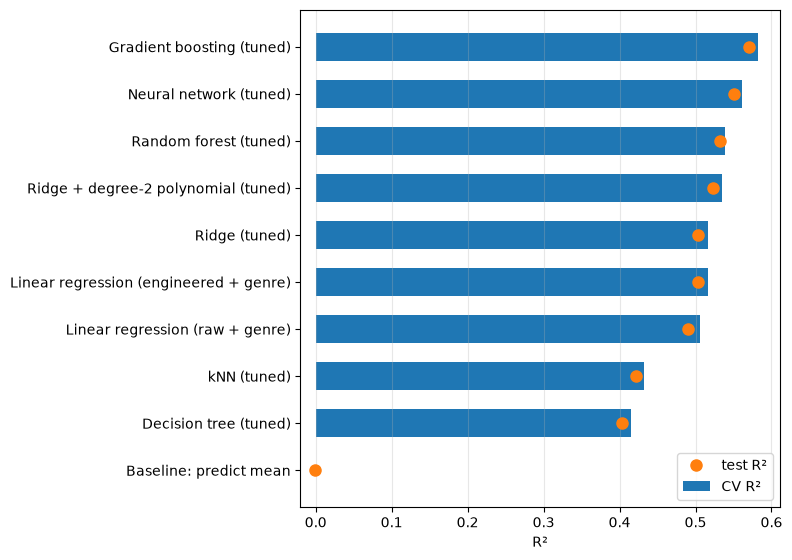

In [ ]:
def plot_scores(table, cv_col, test_col, label):
    """Bars for the CV score (used to choose the model), dots for the test score."""
    table = table.iloc[::-1]    # best model at the top
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(table) + 1.2))
    ax.barh(table["model"], table[cv_col], color="C0", height=0.6, label=f"CV {label}")
    ax.plot(table[test_col], table["model"], "o", color="C1", markersize=8, label=f"test {label}")
    ax.set_xlabel(label)
    ax.set_xlim(left=-0.02)    # so the baseline's dot at 0 is not cut off
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

plot_scores(reg_all, "CV R2", "test R2", "R²")

- **Gradient boosting is the best regressor:** CV R² 0.582, test R² 0.571, and test RMSE 0.170. The baseline (always predict the average valence) has a test RMSE of 0.259, so the error drops by about a third.
- The neural network (CV R² 0.561) and random forest (0.539) come next, then ridge with polynomial features (0.535). Models that can learn curves and interactions do better than plain linear regression (0.517).
- kNN (0.432) and a single decision tree (0.415) are the weakest tuned models.
- Every test score is within 0.02 of its CV score, so cross-validation was a fair guide and tuning did not overfit.
- Even the best model explains only a bit more than half of the variation in valence. The audio features tell part of the story, not all of it.

## 2. Classification: predicting "sad" (`valence < 0.3`)

Each model was scored at the usual threshold of 0.5 and at a threshold chosen with cross-validation.
For each model we keep the row with the higher CV F1, which is the CV-chosen threshold.

In [ ]:
clf_all = pd.concat([pd.read_csv(f"results_{part}_classification.csv") for part in ["linear", "tree", "knn_nn"]])
clf_all = clf_all.dropna(subset=["test F1"]).drop_duplicates("model")
clf_all["model type"] = clf_all["model"].str.split(" (", regex=False).str[0]
clf_all = (clf_all.sort_values("F1", ascending=False)
                  .drop_duplicates("model type")  # keep the CV-chosen threshold for each model
                  .rename(columns={"F1": "CV F1", "ROC_AUC": "CV ROC-AUC"})
                  .reset_index(drop=True))
clf_all[["model", "threshold", "CV F1", "CV ROC-AUC", "test F1", "test ROC-AUC", "test accuracy"]].round(3)

,model,threshold,CV F1,CV ROC-AUC,test F1,test ROC-AUC,test accuracy
0,"Gradient boosting (tuned, threshold 0.36)",0.36,0.709,0.881,0.705,0.876,0.804
1,"Random forest (tuned, threshold 0.45)",0.45,0.698,0.871,0.690,0.865,0.789
2,"Neural network (tuned, threshold 0.35)",0.35,0.697,0.870,0.690,0.865,0.790
3,"Logistic regression (tuned, threshold 0.53)",0.53,0.693,0.866,0.684,0.857,0.785
4,"kNN (tuned, threshold 0.32)",0.32,0.650,0.832,0.642,0.825,0.748
5,"Decision tree (tuned, threshold 0.33)",0.33,0.638,0.819,0.630,0.813,0.743
6,Baseline: always 'not sad',0.50,0.000,0.500,0.000,0.500,0.690


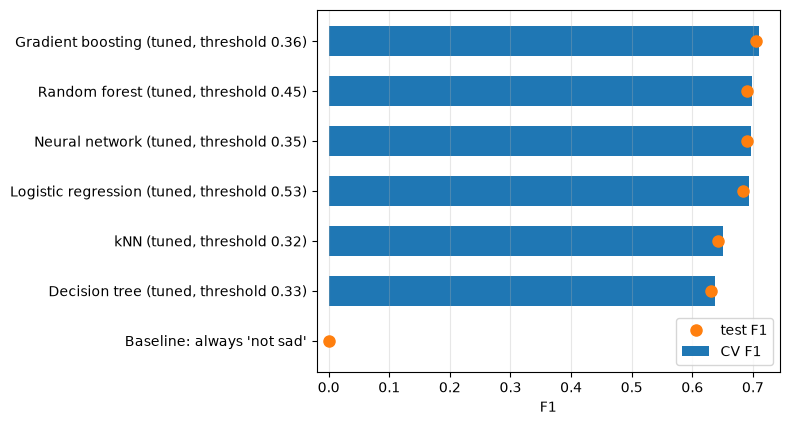

In [ ]:
plot_scores(clf_all, "CV F1", "test F1", "F1")

- **Gradient boosting is also the best classifier:** CV F1 0.709, test F1 0.705, and test ROC-AUC 0.876.
- Random forest, the neural network, and logistic regression are close behind (test F1 0.68 to 0.69). The top four are within 0.02 F1 of each other, so the choice of model matters less here than for regression.
- The baseline that always says "not sad" is right 69% of the time but has an F1 of 0. This is why we don't judge the models by accuracy alone.
- For every model except logistic regression (which already uses balanced class weights), a threshold below 0.5 gives a better F1. Only 31% of songs are sad, so the models are too careful about calling a song sad at 0.5.

## 3. Where the models go wrong

The EDA (Part 2, section 6) found that low valence covers two kinds of songs: calm sad songs, and intense songs such as metal and hard electronic music.
Parts 4, 5, and 6 each checked their errors on these groups, using out-of-fold predictions on the training set.

| Model | MAE: calm sad songs (valence < 0.3, energy < 0.4) | MAE: intense low-valence songs (valence < 0.3, energy > 0.7) | MAE: songs with valence ≥ 0.3 |
|---|---|---|---|
| Ridge + polynomial features (Part 4) | 0.108 | 0.175 | 0.138 |
| Gradient boosting (Part 5) | 0.094 | 0.160 | 0.132 |
| Neural network (Part 6) | 0.092 | 0.162 | 0.137 |

- Every model does worst on the intense low-valence songs. Their error is 1.6 to 1.8 times the error on calm sad songs.
- The non-linear models help a little (0.175 down to 0.160) but don't fix the problem. An angry metal song has high energy and loudness, just like a happy dance song, so the models predict its valence too high.
- All models pull their predictions toward the middle. Low-valence songs are predicted too high (by 0.07 to 0.16 on average) and the other songs a little too low (by about 0.06).

## 4. Back to our question

**Can we predict how sad a song is?** Partly.
The best model (gradient boosting) gets a test R² of 0.57 when predicting valence, and a test F1 of 0.70 and ROC-AUC of 0.88 when finding sad songs.
That is much better than the baseline, but far from perfect.

## 5. Limitations

- **The models lean on genre.** Genre is a label given to a song, not something measured from its audio. In Part 4, linear regression with only the audio features gets a CV R² of 0.40, and adding genre raises it to 0.52. So the models would do worse on songs without a genre label. We only ran this comparison for linear regression.
- **The same artist can appear in both the training and test sets** (Part 1, section 3.7). Songs by the same artist tend to be similar, so the test scores may be a little better than they would be for new artists.
- **Intense low-valence songs are predicted badly** by every model (section 3).
- **The limits from the introduction still apply.** Valence comes from Spotify's own model, not from people, and the dataset has exactly 1,000 songs per genre, so it is not a random sample of all music.